In [1]:
import pandas as pd
from IPython.display import display

payloads = pd.read_csv("payloads.csv")

display(payloads)

,payload_id,name,year,type,mass_kg,orbit,owner_country,design_lifetime_years,operational_status,is_crewed,dry_mass_kg,power_watts,commercial
0,PL0000001,O3b-87,1979,Human Transport,193.4,Suborbital,USA,NaN,Retired,1,150.5,852.0,0
1,PL0000002,Pleiades-9,1996,Earth Observation,98.9,ISS,USA,6.0,Operational,0,68.2,1484.0,1
2,PL0000003,ATV-69,1993,Technology Demo,57.8,SSO,Europe,2.0,Operational,0,34.3,27.0,1
3,PL0000004,Mangalyaan-32,1965,Technology Demo,707.0,Suborbital,Other,2.0,Retired,0,521.5,76.0,1
4,PL0000005,Express-29,1979,Space Station,267.5,MEO,Russia,6.0,Operational,0,151.1,389.0,0
5,PL0000006,ATV-47,1979,Cargo Resupply,386.5,LEO,USA,NaN,Operational,0,222.2,448.0,0
6,PL0000007,HTV-8,1988,Communications,759.7,ISS,USA,9.0,Retired,0,464.5,216.0,1
7,PL0000008,HTV-73,1985,Military,319.5,Interplanetary,Russia,5.0,Operational,0,253.4,302.0,0
8,PL0000009,Kepler-33,1964,Debris,245.8,TLI,USA,8.0,Operational,0,191.3,1318.0,0
9,PL0000010,Pioneer-54,2024,Navigation,11.2,SSO,USA,3.0,Operational,0,8.9,916.0,0


In [2]:
missing = pd.DataFrame({
    "Missing": payloads.isnull().sum(),
    "Missing %": round(payloads.isnull().mean() * 100, 2)
})

display(missing.sort_values("Missing", ascending=False))

,Missing,Missing %
design_lifetime_years,574,5.74
name,0,0.00
year,0,0.00
type,0,0.00
payload_id,0,0.00
mass_kg,0,0.00
orbit,0,0.00
owner_country,0,0.00
operational_status,0,0.00
is_crewed,0,0.00


In [3]:
import pandas as pd

payloads = pd.read_csv("payloads.csv")

payloads_clean = payloads.dropna(
    subset=["design_lifetime_years"]
).copy()

print("Original Shape :", payloads.shape)
print("New Shape      :", payloads_clean.shape)

Original Shape : (10000, 13)
New Shape      : (9426, 13)


In [4]:
display(payloads_clean.head(20))

,payload_id,name,year,type,mass_kg,orbit,owner_country,design_lifetime_years,operational_status,is_crewed,dry_mass_kg,power_watts,commercial
1,PL0000002,Pleiades-9,1996,Earth Observation,98.9,ISS,USA,6.0,Operational,0,68.2,1484.0,1
2,PL0000003,ATV-69,1993,Technology Demo,57.8,SSO,Europe,2.0,Operational,0,34.3,27.0,1
3,PL0000004,Mangalyaan-32,1965,Technology Demo,707.0,Suborbital,Other,2.0,Retired,0,521.5,76.0,1
4,PL0000005,Express-29,1979,Space Station,267.5,MEO,Russia,6.0,Operational,0,151.1,389.0,0
6,PL0000007,HTV-8,1988,Communications,759.7,ISS,USA,9.0,Retired,0,464.5,216.0,1
7,PL0000008,HTV-73,1985,Military,319.5,Interplanetary,Russia,5.0,Operational,0,253.4,302.0,0
8,PL0000009,Kepler-33,1964,Debris,245.8,TLI,USA,8.0,Operational,0,191.3,1318.0,0
9,PL0000010,Pioneer-54,2024,Navigation,11.2,SSO,USA,3.0,Operational,0,8.9,916.0,0
10,PL0000011,SPOT-52,1995,Scientific,807.0,HEO,India,30.0,Operational,0,543.4,582.0,0
12,PL0000013,SES-62,1996,Scientific,517.0,ISS,USA,6.0,Decayed,0,367.0,774.0,0


In [5]:
payloads_clean.isnull().sum()

payload_id               0
name                     0
year                     0
type                     0
mass_kg                  0
orbit                    0
owner_country            0
design_lifetime_years    0
operational_status       0
is_crewed                0
dry_mass_kg              0
power_watts              0
commercial               0
dtype: int64

In [6]:
payloads_clean = payloads.dropna(
    subset=["design_lifetime_years"]
)[
[
    "payload_id",
    "year",
    "mass_kg",
    "dry_mass_kg",
    "power_watts",
    "design_lifetime_years"
]
].copy()

display(payloads_clean.head())

print("Shape:", payloads_clean.shape)

print("\nMissing Values:")
print(payloads_clean.isnull().sum())

Shape: (9426, 6)

Missing Values:
payload_id               0
year                     0
mass_kg                  0
dry_mass_kg              0
power_watts              0
design_lifetime_years    0
dtype: int64


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years
1,PL0000002,1996,98.9,68.2,1484.0,6.0
2,PL0000003,1993,57.8,34.3,27.0,2.0
3,PL0000004,1965,707.0,521.5,76.0,2.0
4,PL0000005,1979,267.5,151.1,389.0,6.0
6,PL0000007,1988,759.7,464.5,216.0,9.0


In [7]:
from IPython.display import Math, display

# ============================================================
# MATHEMATICAL DEFINITIONS
# ============================================================

display(Math(r"(1)\quad ME_i=\frac{D_i}{M_i}"))
print("ME_i : Mass Efficiency of payload i")
print("D_i  : Dry Mass (kg)")
print("M_i  : Total Payload Mass (kg)")
print("Purpose : Measures how much of the total mass is useful dry mass.\n")

display(Math(r"(2)\quad PD_i=\frac{P_i}{M_i}"))
print("PD_i : Power Density of payload i")
print("P_i  : Power Consumption (Watts)")
print("M_i  : Total Payload Mass (kg)")
print("Purpose : Measures power requirement per unit mass.\n")

display(Math(r"(3)\quad SF_i=\frac{M_i-D_i}{M_i}"))
print("SF_i : Structural Fraction of payload i")
print("M_i  : Total Payload Mass (kg)")
print("D_i  : Dry Mass (kg)")
print("Purpose : Measures the fraction of non-dry structural mass.\n")

display(Math(r"(4)\quad TA_i=2025-Y_i"))
print("TA_i : Technology Age of payload i")
print("Y_i  : Launch Year")
print("Purpose : Measures how old the technology is relative to 2025.\n")

display(Math(r"(5)\quad PDM_i=\frac{P_i}{D_i}"))
print("PDM_i : Power per Dry Mass")
print("P_i   : Power Consumption (Watts)")
print("D_i   : Dry Mass (kg)")
print("Purpose : Measures power requirement per unit dry mass.\n")

display(Math(r"(6)\quad PAA_i=\frac{P_i}{TA_i+1}"))
print("PAA_i : Power-Adjusted Age")
print("P_i   : Power Consumption (Watts)")
print("TA_i  : Technology Age")
print("Purpose : Relates power capability to technology age.\n")

display(Math(r"(7)\quad LM_i=\frac{L_i}{M_i}"))
print("LM_i : Lifetime per Mass")
print("L_i  : Design Lifetime (years)")
print("M_i  : Total Payload Mass (kg)")
print("Purpose : Measures mission lifetime achieved per unit mass.\n")

display(Math(r"(8)\quad LP_i=\frac{L_i}{P_i}"))
print("LP_i : Lifetime per Power")
print("L_i  : Design Lifetime (years)")
print("P_i  : Power Consumption (Watts)")
print("Purpose : Measures mission lifetime achieved per unit power.\n")

display(Math(r"(9)\quad CLI_i=P_i\times L_i"))
print("CLI_i : Capability-Lifetime Index")
print("P_i   : Power Consumption (Watts)")
print("L_i   : Design Lifetime (years)")
print("Purpose : Combines power capability and mission lifetime.\n")

display(Math(r"(10)\quad DML_i=\frac{D_i\times L_i}{M_i}"))
print("DML_i : Dry-Mass Lifetime Index")
print("D_i   : Dry Mass (kg)")
print("L_i   : Design Lifetime (years)")
print("M_i   : Total Payload Mass (kg)")
print("Purpose : Relates useful dry mass to mission lifetime.\n")


# ============================================================
# DERIVED TECHNICAL CHARACTERISTICS
# ============================================================

payloads_clean["mass_efficiency"] = (
    payloads_clean["dry_mass_kg"]
    / payloads_clean["mass_kg"]
)

payloads_clean["power_density"] = (
    payloads_clean["power_watts"]
    / payloads_clean["mass_kg"]
)

payloads_clean["structural_fraction"] = (
    (payloads_clean["mass_kg"] - payloads_clean["dry_mass_kg"])
    / payloads_clean["mass_kg"]
)

payloads_clean["technology_age"] = (
    2025 - payloads_clean["year"]
)

payloads_clean["power_per_dry_mass"] = (
    payloads_clean["power_watts"]
    / payloads_clean["dry_mass_kg"]
)

payloads_clean["power_adjusted_age"] = (
    payloads_clean["power_watts"]
    / (payloads_clean["technology_age"] + 1)
)

payloads_clean["lifetime_per_mass"] = (
    payloads_clean["design_lifetime_years"]
    / payloads_clean["mass_kg"]
)

payloads_clean["lifetime_per_power"] = (
    payloads_clean["design_lifetime_years"]
    / payloads_clean["power_watts"]
)

payloads_clean["capability_lifetime_index"] = (
    payloads_clean["power_watts"]
    * payloads_clean["design_lifetime_years"]
)

payloads_clean["dry_mass_lifetime_index"] = (
    payloads_clean["dry_mass_kg"]
    * payloads_clean["design_lifetime_years"]
    / payloads_clean["mass_kg"]
)

# ============================================================
# FINAL DATASET
# ============================================================

display(payloads_clean.head())

print("Shape:", payloads_clean.shape)

print("\nMissing Values:")
display(payloads_clean.isnull().sum())

print("\nSummary Statistics:")
display(payloads_clean.describe())

ME_i : Mass Efficiency of payload i
D_i  : Dry Mass (kg)
M_i  : Total Payload Mass (kg)
Purpose : Measures how much of the total mass is useful dry mass.

PD_i : Power Density of payload i
P_i  : Power Consumption (Watts)
M_i  : Total Payload Mass (kg)
Purpose : Measures power requirement per unit mass.

SF_i : Structural Fraction of payload i
M_i  : Total Payload Mass (kg)
D_i  : Dry Mass (kg)
Purpose : Measures the fraction of non-dry structural mass.

TA_i : Technology Age of payload i
Y_i  : Launch Year
Purpose : Measures how old the technology is relative to 2025.

PDM_i : Power per Dry Mass
P_i   : Power Consumption (Watts)
D_i   : Dry Mass (kg)
Purpose : Measures power requirement per unit dry mass.

PAA_i : Power-Adjusted Age
P_i   : Power Consumption (Watts)
TA_i  : Technology Age
Purpose : Relates power capability to technology age.

LM_i : Lifetime per Mass
L_i  : Design Lifetime (years)
M_i  : Total Payload Mass (kg)
Purpose : Measures mission lifetime achieved per unit mas

$$(1)\quad ME_i=\frac{D_i}{M_i}$$

$$(2)\quad PD_i=\frac{P_i}{M_i}$$

$$(3)\quad SF_i=\frac{M_i-D_i}{M_i}$$

$$(4)\quad TA_i=2025-Y_i$$

$$(5)\quad PDM_i=\frac{P_i}{D_i}$$

... (4 outputs left out)

$$(10)\quad DML_i=\frac{D_i\times L_i}{M_i}$$

,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996,98.9,68.2,1484.0,6.0,0.689585,15.005056,0.310415,29,21.759531,49.466667,0.060667,0.004043,8904.0,4.137513
2,PL0000003,1993,57.8,34.3,27.0,2.0,0.593426,0.467128,0.406574,32,0.787172,0.818182,0.034602,0.074074,54.0,1.186851
3,PL0000004,1965,707.0,521.5,76.0,2.0,0.737624,0.107496,0.262376,60,0.145733,1.245902,0.002829,0.026316,152.0,1.475248
4,PL0000005,1979,267.5,151.1,389.0,6.0,0.564860,1.454206,0.435140,46,2.574454,8.276596,0.022430,0.015424,2334.0,3.389159
6,PL0000007,1988,759.7,464.5,216.0,9.0,0.611426,0.284323,0.388574,37,0.465016,5.684211,0.011847,0.041667,1944.0,5.502830


payload_id                   0
year                         0
mass_kg                      0
dry_mass_kg                  0
power_watts                  0
design_lifetime_years        0
mass_efficiency              0
power_density                0
structural_fraction          0
technology_age               0
power_per_dry_mass           0
power_adjusted_age           0
lifetime_per_mass            0
lifetime_per_power           0
capability_lifetime_index    0
dry_mass_lifetime_index      0
dtype: int64

,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
count,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000,9426.000000
mean,1990.430830,652.536410,439.447942,1100.191067,9.513686,0.674394,11.861770,0.325606,34.569170,17.976692,62.267214,0.100436,0.024121,10459.396987,6.409510
std,19.662455,1327.669806,904.140421,1517.231547,6.880447,0.072651,49.600568,0.072651,19.662455,79.973102,208.560921,0.292596,0.042683,19936.634021,4.694622
min,1957.000000,1.100000,0.700000,14.000000,1.000000,0.545455,0.004294,0.197183,1.000000,0.007343,0.208955,0.000071,0.000107,29.000000,0.549660
25%,1973.000000,95.325000,64.425000,334.000000,5.000000,0.611619,0.830393,0.262285,18.000000,1.231758,9.606031,0.010245,0.004815,2090.000000,3.029927
50%,1991.000000,248.150000,165.800000,653.000000,8.000000,0.673638,2.610240,0.326362,34.000000,3.939554,22.113527,0.030021,0.011304,4904.500000,5.052303
75%,2007.000000,644.475000,429.825000,1286.000000,13.000000,0.737715,8.354525,0.388381,52.000000,12.482114,53.580357,0.086525,0.026596,11364.000000,8.454808
max,2024.000000,25000.000000,17999.500000,50000.000000,30.000000,0.802817,2372.222222,0.454545,68.000000,4003.125000,12504.500000,8.181818,1.227273,900000.000000,23.945228


In [8]:
import numpy as np
import pandas as pd
from IPython.display import Math, display
from sklearn.preprocessing import MinMaxScaler

# ============================================================
# 1. TECHNICAL CHARACTERISTICS
# ============================================================

tc_columns = [
    "year",
    "mass_kg",
    "dry_mass_kg",
    "power_watts",
    "design_lifetime_years",
    "mass_efficiency",
    "power_density",
    "structural_fraction",
    "technology_age",
    "power_per_dry_mass",
    "power_adjusted_age",
    "lifetime_per_mass",
    "lifetime_per_power",
    "capability_lifetime_index",
    "dry_mass_lifetime_index"
]

tc_codes = [f"TC{i}" for i in range(1, 16)]

tc_names = {
    "TC1":  "Launch Year",
    "TC2":  "Payload Mass",
    "TC3":  "Dry Mass",
    "TC4":  "Power Consumption",
    "TC5":  "Design Lifetime",
    "TC6":  "Mass Efficiency",
    "TC7":  "Power Density",
    "TC8":  "Structural Fraction",
    "TC9":  "Technology Age",
    "TC10": "Power per Dry Mass",
    "TC11": "Power-Adjusted Age",
    "TC12": "Lifetime per Mass",
    "TC13": "Lifetime per Power",
    "TC14": "Capability-Lifetime Index",
    "TC15": "Dry-Mass Lifetime Index"
}

X_tc = payloads_clean[tc_columns].copy()
X_tc.columns = tc_codes

# ============================================================
# 2. NORMALIZATION
# ============================================================

scaler = MinMaxScaler()

X_norm = pd.DataFrame(
    scaler.fit_transform(X_tc),
    columns=tc_codes,
    index=X_tc.index
)

# ============================================================
# 3. PEARSON CORRELATION MATRIX
# ============================================================

display(Math(
r"(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}"
r"{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}"
r"\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}"
))

print("r_jk : Pearson correlation coefficient")
print("TC_j : Technical Characteristic j")
print("TC_k : Technical Characteristic k")
print()

tc_corr = X_norm.corr()

print("Pearson Correlation Matrix")
display(tc_corr.round(3))

# ============================================================
# 4. CONTINUOUS HOUSE OF QUALITY ROOF MATRIX
# ============================================================

display(Math(
r"(2)\quad Q_{jk}=r_{jk}"
))

print("Q_jk : Continuous roof relationship")
print("Range : [-1, 1]")
print("Positive values indicate positive technical synergy.")
print("Negative values indicate technical trade-offs.")
print()

roof_matrix = tc_corr.copy()

# Diagonal values are not used
# [compatibility] pandas >= 3 returns a read-only .values array, so the diagonal is
# set on a copy (identical result with pandas 2)
roof_values = roof_matrix.to_numpy(copy=True)
np.fill_diagonal(roof_values, 0.0)
roof_matrix = pd.DataFrame(roof_values, index=roof_matrix.index, columns=roof_matrix.columns)

print("Table 1. Continuous House of Quality Roof Matrix")
display(roof_matrix.round(3))

# ============================================================
# 5. TC DEFINITIONS
# ============================================================

tc_definition_table = pd.DataFrame({
    "TC Code": list(tc_names.keys()),
    "Technical Characteristic": list(tc_names.values())
})

print("Table 2. Technical Characteristics")
display(tc_definition_table)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1, 1]
Positive values indicate positive technical synergy.
Negative values indicate technical trade-offs.

Table 1. Continuous House of Quality Roof Matrix
Table 2. Technical Characteristics


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.007,0.007,-0.008,-0.002,0.006,-0.008,-0.006,-1.000,-0.008,0.272,0.009,0.003,0.000,0.000
TC2,0.007,1.000,0.993,-0.009,0.005,-0.006,-0.101,0.006,-0.007,-0.095,0.001,-0.144,0.009,-0.002,0.005
TC3,0.007,0.993,1.000,-0.007,0.005,0.048,-0.100,-0.048,-0.007,-0.094,0.002,-0.143,0.008,-0.001,0.012
TC4,-0.008,-0.009,-0.007,1.000,-0.001,-0.003,0.317,0.003,0.008,0.305,0.502,0.007,-0.263,0.780,-0.002
TC5,-0.002,0.005,0.005,-0.001,1.000,-0.013,0.002,0.013,0.002,0.003,0.004,0.254,0.417,0.371,0.983
TC6,0.006,-0.006,0.048,-0.003,-0.013,1.000,-0.022,-1.000,-0.006,-0.045,0.009,-0.008,0.005,-0.014,0.135
TC7,-0.008,-0.101,-0.100,0.317,0.002,-0.022,1.000,0.022,0.008,0.996,0.168,0.477,-0.088,0.230,-0.002
TC8,-0.006,0.006,-0.048,0.003,0.013,-1.000,0.022,1.000,0.006,0.045,-0.009,0.008,-0.005,0.014,-0.135
TC9,-1.000,-0.007,-0.007,0.008,0.002,-0.006,0.008,0.006,1.000,0.008,-0.272,-0.009,-0.003,-0.000,-0.000
TC10,-0.008,-0.095,-0.094,0.305,0.003,-0.045,0.996,0.045,0.008,1.000,0.162,0.461,-0.083,0.221,-0.005


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.007,0.007,-0.008,-0.002,0.006,-0.008,-0.006,-1.000,-0.008,0.272,0.009,0.003,0.000,0.000
TC2,0.007,0.000,0.993,-0.009,0.005,-0.006,-0.101,0.006,-0.007,-0.095,0.001,-0.144,0.009,-0.002,0.005
TC3,0.007,0.993,0.000,-0.007,0.005,0.048,-0.100,-0.048,-0.007,-0.094,0.002,-0.143,0.008,-0.001,0.012
TC4,-0.008,-0.009,-0.007,0.000,-0.001,-0.003,0.317,0.003,0.008,0.305,0.502,0.007,-0.263,0.780,-0.002
TC5,-0.002,0.005,0.005,-0.001,0.000,-0.013,0.002,0.013,0.002,0.003,0.004,0.254,0.417,0.371,0.983
TC6,0.006,-0.006,0.048,-0.003,-0.013,0.000,-0.022,-1.000,-0.006,-0.045,0.009,-0.008,0.005,-0.014,0.135
TC7,-0.008,-0.101,-0.100,0.317,0.002,-0.022,0.000,0.022,0.008,0.996,0.168,0.477,-0.088,0.230,-0.002
TC8,-0.006,0.006,-0.048,0.003,0.013,-1.000,0.022,0.000,0.006,0.045,-0.009,0.008,-0.005,0.014,-0.135
TC9,-1.000,-0.007,-0.007,0.008,0.002,-0.006,0.008,0.006,0.000,0.008,-0.272,-0.009,-0.003,-0.000,-0.000
TC10,-0.008,-0.095,-0.094,0.305,0.003,-0.045,0.996,0.045,0.008,0.000,0.162,0.461,-0.083,0.221,-0.005


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


In [9]:
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)

customer_requirements = pd.DataFrame({
    "CR Code": [
        "CR1","CR2","CR3","CR4","CR5",
        "CR6","CR7","CR8","CR9","CR10",
        "CR11","CR12","CR13","CR14","CR15"
    ],

    "Customer Requirement": [
        "High Mission Reliability",
        "High Payload Capability",
        "Long Operational Lifetime",
        "Low Structural Mass",
        "Efficient Power Utilization",
        "High Mass Efficiency",
        "High Power Capability",
        "Optimized Structural Design",
        "Technology Modernity",
        "Efficient Energy Utilization",
        "Long-Term Operational Capability",
        "High Lifetime Efficiency",
        "Sustainable Mission Performance",
        "High Mission Capability",
        "Maximum System Effectiveness"
    ],

    "Importance": [
        10, 9, 10, 7, 8,
        8, 7, 6, 5, 8,
        10, 9, 8, 10, 10
    ],

    "Rationale": [
        "Görev başarısız olursa tüm sistem değersiz hale gelir.",
        "Daha fazla bilimsel veya ticari yük taşıyabilmek temel görev hedefidir.",
        "Uzun görev ömrü yatırım geri dönüşünü ve veri toplama süresini artırır.",
        "Önemlidir ancak tek başına görev başarısını belirlemez.",
        "Uzay sistemlerinde enerji en kritik kısıtlardan biridir.",
        "Faydalı yük ile toplam kütle arasındaki verimliliği artırır.",
        "Yüksek güç faydalıdır ancak her görev için kritik değildir.",
        "Tasarım optimizasyonu önemli olsa da üst düzey görev gereksinimlerinin gerisindedir.",
        "Yeni teknoloji avantajlıdır fakat güvenilirlikten daha önemli değildir.",
        "Uzun süreli görevler için enerji verimliliği kritik rol oynar.",
        "Sistemin yıllarca çalışabilmesi görev başarısının temelidir.",
        "Kaynak başına elde edilen görev ömrünü artırır.",
        "Görevin zaman içinde performansını koruyabilmesi önemlidir.",
        "Görevin amaçlarını yerine getirme kapasitesi en üst önceliktedir.",
        "Tüm sistem performansını temsil eden genel hedef kriterdir."
    ]
})

display(
    customer_requirements.style.set_properties(
        subset=["Customer Requirement", "Rationale"],
        **{
            "white-space": "normal",
            "text-align": "left",
            "min-width": "250px"
        }
    ).set_properties(
        subset=["CR Code", "Importance"],
        **{
            "text-align": "center"
        }
    )
)

cr_importance = customer_requirements["Importance"].to_numpy()

,CR Code,Customer Requirement,Importance,Rationale
0,CR1,High Mission Reliability,10,Görev başarısız olursa tüm sistem değersiz hale gelir.
1,CR2,High Payload Capability,9,Daha fazla bilimsel veya ticari yük taşıyabilmek temel görev hedefidir.
2,CR3,Long Operational Lifetime,10,Uzun görev ömrü yatırım geri dönüşünü ve veri toplama süresini artırır.
3,CR4,Low Structural Mass,7,Önemlidir ancak tek başına görev başarısını belirlemez.
4,CR5,Efficient Power Utilization,8,Uzay sistemlerinde enerji en kritik kısıtlardan biridir.
5,CR6,High Mass Efficiency,8,Faydalı yük ile toplam kütle arasındaki verimliliği artırır.
6,CR7,High Power Capability,7,Yüksek güç faydalıdır ancak her görev için kritik değildir.
7,CR8,Optimized Structural Design,6,Tasarım optimizasyonu önemli olsa da üst düzey görev gereksinimlerinin gerisindedir.
8,CR9,Technology Modernity,5,Yeni teknoloji avantajlıdır fakat güvenilirlikten daha önemli değildir.
9,CR10,Efficient Energy Utilization,8,Uzun süreli görevler için enerji verimliliği kritik rol oynar.


In [10]:
relationship_matrix = pd.DataFrame([

# TC1 TC2 TC3 TC4 TC5 TC6 TC7 TC8 TC9 TC10 TC11 TC12 TC13 TC14 TC15

[1, 1, 1, 1, 9, 3, 1, 1, 1, 1, 1, 3, 3, 9, 9],   # CR1
[1, 9, 3, 1, 1, 3, 1, 1, 0, 1, 0, 1, 1, 3, 1],   # CR2
[0, 1, 1, 1, 9, 1, 0, 0, 1, 1, 1, 9, 9, 3, 9],   # CR3
[0, 3, 9, 0, 1, 3, 0, 9, 0, 1, 0, 1, 0, 1, 3],   # CR4
[0, 0, 0, 9, 1, 1, 9, 0, 0, 9, 3, 1, 3, 1, 0],   # CR5
[0, 1, 3, 0, 1, 9, 1, 9, 0, 3, 0, 1, 1, 1, 3],   # CR6
[0, 1, 1, 9, 1, 1, 9, 0, 0, 3, 3, 1, 1, 3, 1],   # CR7
[0, 3, 9, 0, 1, 9, 0, 9, 0, 1, 0, 1, 0, 1, 3],   # CR8
[9, 0, 0, 0, 1, 0, 0, 0, 9, 0, 9, 0, 0, 1, 0],   # CR9
[0, 0, 0, 9, 1, 1, 9, 0, 0, 9, 3, 1, 3, 1, 0],   # CR10
[1, 1, 1, 1, 9, 1, 1, 1, 1, 1, 1, 9, 9, 9, 9],   # CR11
[0, 1, 1, 1, 3, 1, 1, 0, 0, 1, 1, 9, 9, 3, 3],   # CR12
[1, 1, 1, 3, 9, 3, 1, 1, 1, 1, 1, 3, 3, 9, 9],   # CR13
[1, 3, 1, 3, 3, 3, 3, 1, 1, 3, 1, 3, 3, 9, 3],   # CR14
[1, 3, 3, 3, 9, 9, 3, 3, 1, 3, 1, 3, 3, 9, 9]    # CR15

],

index=[f"CR{i}" for i in range(1,16)],
columns=[f"TC{i}" for i in range(1,16)]
)

display(relationship_matrix)

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR1,1,1,1,1,9,3,1,1,1,1,1,3,3,9,9
CR2,1,9,3,1,1,3,1,1,0,1,0,1,1,3,1
CR3,0,1,1,1,9,1,0,0,1,1,1,9,9,3,9
CR4,0,3,9,0,1,3,0,9,0,1,0,1,0,1,3
CR5,0,0,0,9,1,1,9,0,0,9,3,1,3,1,0
CR6,0,1,3,0,1,9,1,9,0,3,0,1,1,1,3
CR7,0,1,1,9,1,1,9,0,0,3,3,1,1,3,1
CR8,0,3,9,0,1,9,0,9,0,1,0,1,0,1,3
CR9,9,0,0,0,1,0,0,0,9,0,9,0,0,1,0
CR10,0,0,0,9,1,1,9,0,0,9,3,1,3,1,0


In [11]:
relationship_matrix["Justification"] = [
    "Strong emphasis on design lifetime, capability-lifetime index and dry-mass lifetime index due to their direct contribution to mission reliability.",
    "Payload capability is primarily driven by payload mass, while dry mass and mass efficiency provide secondary support.",
    "Operational lifetime is directly associated with design lifetime and lifetime-based performance indicators.",
    "Structural mass is mainly represented by dry mass and structural fraction metrics.",
    "Power utilization is strongly related to power consumption, power density and power-per-dry-mass measures.",
    "Mass efficiency is directly reflected by mass efficiency and structural fraction characteristics.",
    "Power capability depends primarily on available power and power density.",
    "Structural optimization is represented by dry mass, mass efficiency and structural fraction.",
    "Technology modernity is captured through launch year, technology age and power-adjusted age.",
    "Energy utilization is primarily determined by power consumption and power efficiency indicators.",
    "Long-term capability relies heavily on lifetime-related technical characteristics.",
    "Lifetime efficiency is mainly represented by lifetime-per-mass and lifetime-per-power metrics.",
    "Sustainable performance requires both long operational life and efficient resource utilization.",
    "Mission capability is primarily represented by the capability-lifetime index and supporting performance measures.",
    "Overall system effectiveness is influenced by lifetime, efficiency and capability indicators simultaneously."
]

In [12]:
display(relationship_matrix)

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15,Justification
CR1,1,1,1,1,9,3,1,1,1,1,1,3,3,9,9,"Strong emphasis on design lifetime, capability-lifetime index and dry-mass lifetime index due to their direct contribution to mission reliability."
CR2,1,9,3,1,1,3,1,1,0,1,0,1,1,3,1,"Payload capability is primarily driven by payload mass, while dry mass and mass efficiency provide secondary support."
CR3,0,1,1,1,9,1,0,0,1,1,1,9,9,3,9,Operational lifetime is directly associated with design lifetime and lifetime-based performance indicators.
CR4,0,3,9,0,1,3,0,9,0,1,0,1,0,1,3,Structural mass is mainly represented by dry mass and structural fraction metrics.
CR5,0,0,0,9,1,1,9,0,0,9,3,1,3,1,0,"Power utilization is strongly related to power consumption, power density and power-per-dry-mass measures."
CR6,0,1,3,0,1,9,1,9,0,3,0,1,1,1,3,Mass efficiency is directly reflected by mass efficiency and structural fraction characteristics.
CR7,0,1,1,9,1,1,9,0,0,3,3,1,1,3,1,Power capability depends primarily on available power and power density.
CR8,0,3,9,0,1,9,0,9,0,1,0,1,0,1,3,"Structural optimization is represented by dry mass, mass efficiency and structural fraction."
CR9,9,0,0,0,1,0,0,0,9,0,9,0,0,1,0,"Technology modernity is captured through launch year, technology age and power-adjusted age."
CR10,0,0,0,9,1,1,9,0,0,9,3,1,3,1,0,Energy utilization is primarily determined by power consumption and power efficiency indicators.


In [13]:
print(
"""
Moderate relationships (R = 3) were assigned where a technical
characteristic indirectly contributes to the corresponding customer
requirement. Weak relationships (R = 1) indicate limited influence,
while zero values indicate no meaningful relationship.
"""
)


Moderate relationships (R = 3) were assigned where a technical
characteristic indirectly contributes to the corresponding customer
requirement. Weak relationships (R = 1) indicate limited influence,
while zero values indicate no meaningful relationship.



In [14]:
import pandas as pd

# ============================================================
# CUSTOMER IMPORTANCE SCORES
# ============================================================

cr_importance_scores = [
    10, 9, 10, 7, 8,
    8, 7, 6, 5, 8,
    10, 9, 8, 10, 10
]

# ============================================================
# TC1-TC14 ONLY
# ============================================================

tc_cols = [f"TC{i}" for i in range(1,16)]

# ============================================================
# ROOF PART
# ============================================================

roof_part = roof_matrix.loc[
    tc_cols,
    tc_cols
].copy()

roof_part.insert(
    0,
    "CR / TC",
    roof_part.index
)

roof_part.insert(
    0,
    "Customer Importance Score",
    ""
)

# ============================================================
# SEPARATOR ROW
# ============================================================

separator = pd.DataFrame(
    [[
        "Customer Importance Score",
        "CR / TC",
        *tc_cols
    ]],
    columns=roof_part.columns
)

# ============================================================
# BASE PART
# ============================================================

base_part = relationship_matrix[
    tc_cols
].copy()

base_part.insert(
    0,
    "CR / TC",
    base_part.index
)

base_part.insert(
    0,
    "Customer Importance Score",
    cr_importance_scores
)

# ============================================================
# FULL HOUSE OF QUALITY
# ============================================================

full_hoq = pd.concat(
    [
        roof_part,
        separator,
        base_part
    ],
    ignore_index=True
)

print("Complete House of Quality Matrix")

display(full_hoq)

Complete House of Quality Matrix


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [15]:
import numpy as np
import pandas as pd
from IPython.display import display, Math

# ============================================================
# ADJUSTED RELATIONSHIP MATRIX
# ============================================================

display(Math(
r"R^{*}=R\left(I+\lambda Q_n\right)"
))

display(Math(
r"Q_{n,jk}=\max(0,Q_{jk})"
))
# ------------------------------------------------------------
# PARAMETER
# ------------------------------------------------------------

lambda_value = 0.50

# ------------------------------------------------------------
# TC COLUMNS
# ------------------------------------------------------------

tc_cols = [f"TC{i}" for i in range(1,16)]

# ------------------------------------------------------------
# RELATIONSHIP MATRIX
# ------------------------------------------------------------

R = relationship_matrix[tc_cols].astype(float)

# ------------------------------------------------------------
# CONTINUOUS ROOF MATRIX
# ------------------------------------------------------------

Q = roof_matrix.loc[tc_cols, tc_cols].astype(float)

# Keep only positive technical correlations
Qn = Q.clip(lower=0)

# ------------------------------------------------------------
# IDENTITY MATRIX
# ------------------------------------------------------------

I = np.eye(len(tc_cols))

# ------------------------------------------------------------
# ADJUSTED RELATIONSHIP MATRIX
# ------------------------------------------------------------

adjusted_relationship_matrix = pd.DataFrame(
    R.values @ (I + lambda_value * Qn.values),
    index=R.index,
    columns=R.columns
)

# Ensure no negative adjusted relationship values
adjusted_relationship_matrix = adjusted_relationship_matrix.clip(lower=0)

display(Math(
r"\lambda = 0.50"
))

print("Adjusted Relationship Matrix")
display(adjusted_relationship_matrix.round(3))

Adjusted Relationship Matrix


$$R^{*}=R\left(I+\lambda Q_n\right)$$

$$Q_{n,jk}=\max(0,Q_{jk})$$

$$\lambda = 0.50$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR1,1.173,1.561,1.660,5.086,16.119,3.647,3.515,1.174,1.023,3.455,3.484,6.342,6.893,13.288,16.264
CR2,1.058,10.505,7.555,2.485,2.424,3.145,2.252,1.095,0.016,2.236,1.203,1.931,1.520,4.041,2.609
CR3,0.202,1.582,1.633,2.607,17.012,1.657,3.246,0.147,1.015,3.655,2.049,12.038,13.142,7.478,17.031
CR4,0.055,7.506,10.581,0.558,2.877,3.418,0.954,9.050,0.034,1.545,0.323,1.819,0.930,1.953,4.061
CR5,0.420,0.018,0.040,12.946,1.965,1.020,15.515,0.334,0.111,15.443,6.965,5.578,3.254,7.395,1.493
CR6,0.049,2.532,3.736,1.022,3.069,9.277,2.950,9.099,0.046,4.043,0.590,2.562,1.911,2.289,4.633
CR7,0.424,1.507,1.535,12.810,2.407,1.107,12.756,0.216,0.087,9.663,6.897,4.338,1.470,8.915,2.449
CR8,0.074,7.506,10.725,0.558,2.877,9.418,0.954,9.050,0.034,1.545,0.350,1.819,0.944,1.953,4.467
CR9,10.223,0.039,0.039,2.688,1.210,0.068,0.908,0.042,9.001,0.877,10.432,0.274,0.222,3.051,0.692
CR10,0.420,0.018,0.040,12.946,1.965,1.020,15.515,0.334,0.111,15.443,6.965,5.578,3.254,7.395,1.493


In [16]:
import pandas as pd

# ============================================================
# CUSTOMER IMPORTANCE SCORES
# ============================================================

cr_importance_scores = [
    10, 9, 10, 7, 8,
    8, 7, 6, 5, 8,
    10, 9, 8, 10, 10
]

# ============================================================
# TC1-TC14 ONLY
# ============================================================

tc_cols = [f"TC{i}" for i in range(1,16)]

# ============================================================
# ROOF PART (UNCHANGED)
# ============================================================

roof_part = roof_matrix.loc[
    tc_cols,
    tc_cols
].copy()

roof_part.insert(
    0,
    "CR / TC",
    roof_part.index
)

roof_part.insert(
    0,
    "Customer Importance Score",
    ""
)

# ============================================================
# SEPARATOR ROW
# ============================================================

separator = pd.DataFrame(
    [[
        "Customer Importance Score",
        "CR / TC",
        *tc_cols
    ]],
    columns=roof_part.columns
)

# ============================================================
# ADJUSTED RELATIONSHIP MATRIX PART
# ============================================================

adjusted_part = adjusted_relationship_matrix[
    tc_cols
].round(2).copy()

adjusted_part.insert(
    0,
    "CR / TC",
    adjusted_part.index
)

adjusted_part.insert(
    0,
    "Customer Importance Score",
    cr_importance_scores
)

# ============================================================
# COMPLETE ADJUSTED HOUSE OF QUALITY
# ============================================================

full_adjusted_hoq = pd.concat(
    [
        roof_part,
        separator,
        adjusted_part
    ],
    ignore_index=True
)

print("Complete Adjusted House of Quality Matrix")

display(full_adjusted_hoq)

Complete Adjusted House of Quality Matrix


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [17]:
from IPython.display import display, Math

display(Math(
    r"TIS_j=\sum_{i=1}^{m} I_i R_{ij}"
))

$$TIS_j=\sum_{i=1}^{m} I_i R_{ij}$$

In [18]:
full_adjusted_hoq = pd.concat(
    [
        roof_part,
        separator,
        adjusted_part
    ],
    ignore_index=True
)

In [19]:
# Remove previously added Adjusted Technical Importance Score row (if exists)
full_adjusted_hoq = full_adjusted_hoq[
    full_adjusted_hoq["CR / TC"] != "Adjusted Technical Importance Score"
].reset_index(drop=True)

# ============================================================
# TECHNICAL IMPORTANCE SCORE
# ============================================================

import numpy as np
import pandas as pd

importance = np.array(cr_importance_scores)

technical_importance = (
    importance @ adjusted_relationship_matrix[tc_cols].values
)

technical_importance_row = pd.DataFrame(
    [[
        "",
        "Technical Importance Score",
        *technical_importance
    ]],
    columns=full_adjusted_hoq.columns
)

# ============================================================
# ADD TO HOUSE OF QUALITY
# ============================================================

full_adjusted_hoq = pd.concat(
    [
        full_adjusted_hoq,
        technical_importance_row
    ],
    ignore_index=True
)

print("Complete Adjusted House of Quality Matrix")

display(full_adjusted_hoq.round(3))

Complete Adjusted House of Quality Matrix


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [20]:
display(Math(
    r"IP_j=\frac{TIS_j}{\sum_{k=1}^{n}TIS_k}\times100"
))

$$IP_j=\frac{TIS_j}{\sum_{k=1}^{n}TIS_k}\times100$$

In [21]:
# ============================================================
# IMPORTANCE (%)
# ============================================================

importance_percent = (
    technical_importance / technical_importance.sum()
) * 100

importance_percent = np.round(importance_percent, 2)

importance_percent_row = pd.DataFrame(
    [[
        "",
        "Importance (%)",
        *importance_percent
    ]],
    columns=full_hoq.columns
)

full_hoq = pd.concat(
    [full_hoq, importance_percent_row],
    ignore_index=True
)

display(full_hoq)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [22]:
from IPython.display import display, Math

display(Math(
    r"PR_j=\operatorname{Rank}_{\mathrm{desc}}\left(TIS_j\right)"
))

$$PR_j=\operatorname{Rank}_{\mathrm{desc}}\left(TIS_j\right)$$

In [23]:
# ============================================================
# PRIORITY RANK
# ============================================================

# Varsa eski satırı kaldır
full_hoq = full_hoq[
    full_hoq.iloc[:, 1] != "Priority Rank"
].reset_index(drop=True)

priority_rank = (
    pd.Series(technical_importance)
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
    .to_numpy()
)

priority_rank_row = pd.DataFrame(
    [[
        "",
        "Priority Rank",
        *priority_rank
    ]],
    columns=full_hoq.columns
)

full_hoq = pd.concat(
    [full_hoq, priority_rank_row],
    ignore_index=True
)

display(full_hoq)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [24]:
from IPython.display import display, Math, Markdown

display(Math(
r"""
\begin{aligned}
\textbf{Current\ Performance}\;(CP_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Very\ Poor},\;
10=\mathrm{Excellent}
\\[6pt]

\textbf{Target}\;(T_j)
&=10,
&&\forall j=1,\ldots,n,\;
\mathrm{representing\ the\ ideal\ engineering\ performance}
\\[6pt]

\textbf{Difficulty}\;(D_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Very\ Easy},\;
10=\mathrm{Very\ Difficult}
\\[6pt]

\textbf{Cost\ and\ Time}\;(CT_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Low\ Cost/Short\ Time},\;
10=\mathrm{High\ Cost/Long\ Time}
\\[8pt]

\left\{
\textbf{Current\ Performance},
\textbf{Target},
\textbf{Difficulty},
\textbf{Cost\ and\ Time}
\right\}
&\leftarrow
\mathrm{Expert\ Assessment}
\end{aligned}
"""
))

display(Markdown("""
**Expert Assessment:**  
The values of **Current Performance, Target, Difficulty, and Cost and Time** were determined through expert judgment based on engineering knowledge, satellite payload design practices, and practical implementation considerations. The **Target** value was fixed at **10** for every technical characteristic to represent the ideal engineering performance that each characteristic should ultimately achieve. Keeping these parameters constant across all experiments ensures that any changes in the QFD results arise solely from the different missing data imputation methods and the resulting correlation-based roof matrix, rather than from subjective evaluation criteria.
"""))

$$\begin{aligned}
\textbf{Current\ Performance}\;(CP_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Very\ Poor},\;
10=\mathrm{Excellent}
\\[6pt]

\textbf{Target}\;(T_j)
&=10,
&&\forall j=1,\ldots,n,\;
\mathrm{representing\ the\ ideal\ engineering\ performance}
\\[6pt]

\textbf{Difficulty}\;(D_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Very\ Easy},\;
10=\mathrm{Very\ Difficult}
\\[6pt]

\textbf{Cost\ and\ Time}\;(CT_j)
&\in\{1,\ldots,10\},
&&1=\mathrm{Low\ Cost/Short\ Time},\;
10=\mathrm{High\ Cost/Long\ Time}
\\[8pt]

\left\{
\textbf{Current\ Performance},
\textbf{Target},
\textbf{Difficulty},
\textbf{Cost\ and\ Time}
\right\}
&\leftarrow
\mathrm{Expert\ Assessment}
\end{aligned}$$


**Expert Assessment:**  
The values of **Current Performance, Target, Difficulty, and Cost and Time** were determined through expert judgment based on engineering knowledge, satellite payload design practices, and practical implementation considerations. The **Target** value was fixed at **10** for every technical characteristic to represent the ideal engineering performance that each characteristic should ultimately achieve. Keeping these parameters constant across all experiments ensures that any changes in the QFD results arise solely from the different missing data imputation methods and the resulting correlation-based roof matrix, rather than from subjective evaluation criteria.


In [25]:
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# ============================================================
# RATING SCALE
# ============================================================

display(Markdown("""
### Technical Evaluation Rating Scale

| Criterion | Scale |
|-----------|-------|
| **Current Performance** | **1 = Very Poor, 10 = Excellent** |
| **Target** | **Fixed at 10 (Desired Engineering Target)** |
| **Difficulty** | **1 = Very Easy, 10 = Very Difficult** |
| **Cost and Time** | **1 = Low Cost / Short Time, 10 = High Cost / Long Implementation Time** |
"""))

# ============================================================
# TECHNICAL EVALUATION (EXPERT ASSESSMENT)
# ============================================================

technical_evaluation = pd.DataFrame({

    "TC Code": [f"TC{i}" for i in range(1,16)],

    "Technical Characteristic": [
        "Launch Year",
        "Payload Mass",
        "Dry Mass",
        "Power Consumption",
        "Design Lifetime",
        "Mass Efficiency",
        "Power Density",
        "Structural Fraction",
        "Technology Age",
        "Power per Dry Mass",
        "Power Adjusted Age",
        "Lifetime per Mass",
        "Lifetime per Power",
        "Capability Lifetime Index",
        "Dry-Mass Lifetime Index"
    ],

    # 1 = Very Poor, 10 = Excellent
    "Current Performance": [
        6, 5, 5, 6, 7, 6, 6,
        5, 7, 6, 6, 5, 5, 7,
        6
    ],

    # Desired Engineering Target
    "Target": [10]*15,

    # 1 = Very Easy, 10 = Very Difficult
    "Difficulty": [
        3, 6, 6, 7, 9, 7, 6,
        6, 5, 6, 5, 8, 8, 9,
        7
    ],

    # 1 = Low Cost / Short Time, 10 = High Cost / Long Time
    "Cost and Time": [
        2, 6, 6, 7, 9, 7, 6,
        5, 4, 5, 4, 8, 8, 9,
        6
    ],

    "Rationale": [
        "Updating the launch year mainly depends on adopting newer platforms and is relatively easy and inexpensive.",
        "Reducing payload mass requires structural redesign and lightweight materials.",
        "Reducing dry mass requires subsystem optimization and advanced manufacturing techniques.",
        "Lowering power consumption requires redesign of electronic subsystems and power management.",
        "Extending design lifetime requires highly reliable components and extensive qualification testing.",
        "Improving mass efficiency requires multidisciplinary optimization between payload and structure.",
        "Increasing power density requires improvements in power generation and storage technologies.",
        "Reducing structural fraction requires lightweight structural materials and optimization.",
        "Improving technology modernity mainly depends on adopting newer technologies with moderate effort.",
        "Improving power per dry mass requires simultaneous optimization of mass and power subsystems.",
        "Improving power adjusted by technology age mainly depends on technology upgrades.",
        "Increasing lifetime per mass requires significant optimization across multiple engineering disciplines.",
        "Increasing lifetime per power requires improvements in both energy efficiency and durability.",
        "Improving capability lifetime index requires simultaneous enhancement of mission capability and operational lifetime.",
        "Improving the dry-mass lifetime index requires simultaneous optimization of dry-mass efficiency and design lifetime, involving coordinated structural, material, and reliability improvements."
    ]

})

display(
    technical_evaluation.style.set_properties(
        subset=["Technical Characteristic", "Rationale"],
        **{
            "white-space": "normal",
            "text-align": "left",
            "min-width": "280px"
        }
    ).set_properties(
        subset=[
            "TC Code",
            "Current Performance",
            "Target",
            "Difficulty",
            "Cost and Time"
        ],
        **{
            "text-align": "center"
        }
    )
)


### Technical Evaluation Rating Scale

| Criterion | Scale |
|-----------|-------|
| **Current Performance** | **1 = Very Poor, 10 = Excellent** |
| **Target** | **Fixed at 10 (Desired Engineering Target)** |
| **Difficulty** | **1 = Very Easy, 10 = Very Difficult** |
| **Cost and Time** | **1 = Low Cost / Short Time, 10 = High Cost / Long Implementation Time** |


,TC Code,Technical Characteristic,Current Performance,Target,Difficulty,Cost and Time,Rationale
0,TC1,Launch Year,6,10,3,2,Updating the launch year mainly depends on adopting newer platforms and is relatively easy and inexpensive.
1,TC2,Payload Mass,5,10,6,6,Reducing payload mass requires structural redesign and lightweight materials.
2,TC3,Dry Mass,5,10,6,6,Reducing dry mass requires subsystem optimization and advanced manufacturing techniques.
3,TC4,Power Consumption,6,10,7,7,Lowering power consumption requires redesign of electronic subsystems and power management.
4,TC5,Design Lifetime,7,10,9,9,Extending design lifetime requires highly reliable components and extensive qualification testing.
5,TC6,Mass Efficiency,6,10,7,7,Improving mass efficiency requires multidisciplinary optimization between payload and structure.
6,TC7,Power Density,6,10,6,6,Increasing power density requires improvements in power generation and storage technologies.
7,TC8,Structural Fraction,5,10,6,5,Reducing structural fraction requires lightweight structural materials and optimization.
8,TC9,Technology Age,7,10,5,4,Improving technology modernity mainly depends on adopting newer technologies with moderate effort.
9,TC10,Power per Dry Mass,6,10,6,5,Improving power per dry mass requires simultaneous optimization of mass and power subsystems.


In [26]:
# ============================================================
# TC1-TC15
# ============================================================

tc_cols = [f"TC{i}" for i in range(1,16)]

# ============================================================
# TECHNICAL IMPORTANCE SCORE
# ============================================================

importance = np.array(cr_importance_scores)

adjusted_technical_importance = (
    importance @ adjusted_relationship_matrix[tc_cols].values
)

# ============================================================
# IMPORTANCE (%)
# ============================================================

importance_percent = (
    adjusted_technical_importance /
    adjusted_technical_importance.sum()
) * 100

importance_percent = np.round(
    importance_percent,
    2
)

# ============================================================
# PRIORITY RANK
# ============================================================

priority_rank = (
    pd.Series(adjusted_technical_importance)
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
    .to_numpy()
)

# ============================================================
# CHECK
# ============================================================

print("TC count                    :", len(tc_cols))
print("Technical Importance count  :", len(adjusted_technical_importance))
print("Importance % count           :", len(importance_percent))
print("Priority Rank count          :", len(priority_rank))

display(
    pd.DataFrame({
        "TC": tc_cols,
        "Technical Importance Score": adjusted_technical_importance,
        "Importance (%)": importance_percent,
        "Priority Rank": priority_rank
    })
)

TC count                    : 15
Technical Importance count  : 15
Importance % count           : 15
Priority Rank count          : 15


,TC,Technical Importance Score,Importance (%),Priority Rank
0,TC1,132.346388,1.46,14
1,TC2,378.105276,4.16,12
2,TC3,398.696151,4.39,11
3,TC4,711.790694,7.84,7
4,TC5,1085.536217,11.95,2
5,TC6,446.770632,4.92,10
6,TC7,720.958100,7.94,5
7,TC8,287.631290,3.17,13
8,TC9,108.297474,1.19,15
9,TC10,713.995415,7.86,6


In [27]:
import pandas as pd
import numpy as np

# ============================================================
# CUSTOMER IMPORTANCE SCORES
# ============================================================

cr_importance_scores = [
    10, 9, 10, 7, 8,
    8, 7, 6, 5, 8,
    10, 9, 8, 10, 10
]

# ============================================================
# TECHNICAL CHARACTERISTICS
# ============================================================

tc_cols = [f"TC{i}" for i in range(1,16)]

# ============================================================
# ROOF MATRIX
# ============================================================

roof_part = roof_matrix.loc[
    tc_cols,
    tc_cols
].copy()

roof_part.insert(0, "CR / TC", roof_part.index)
roof_part.insert(0, "Customer Importance Score", "")

# ============================================================
# SEPARATOR
# ============================================================

separator = pd.DataFrame(
    [[
        "Customer Importance Score",
        "CR / TC",
        *tc_cols
    ]],
    columns=roof_part.columns
)

# ============================================================
# ADJUSTED RELATIONSHIP MATRIX
# ============================================================

base_part = adjusted_relationship_matrix[tc_cols].copy()

base_part.insert(
    0,
    "CR / TC",
    base_part.index
)

base_part.insert(
    0,
    "Customer Importance Score",
    cr_importance_scores
)

# ============================================================
# TECHNICAL EVALUATION SUMMARY
# ============================================================

summary_rows = pd.DataFrame(
    [
        ["", "Technical Importance Score", *adjusted_technical_importance],
        ["", "Importance (%)", *importance_percent],
        ["", "Priority Rank", *priority_rank],
        ["", "Current Performance", *technical_evaluation["Current Performance"].values],
        ["", "Target", *technical_evaluation["Target"].values],
        ["", "Difficulty", *technical_evaluation["Difficulty"].values],
        ["", "Cost and Time", *technical_evaluation["Cost and Time"].values],
    ],
    columns=base_part.columns
)

# ============================================================
# COMPLETE ADJUSTED HOUSE OF QUALITY
# ============================================================

full_adjusted_hoq = pd.concat(
    [
        roof_part,
        separator,
        base_part,
        summary_rows
    ],
    ignore_index=True
)

print("Complete Adjusted House of Quality Matrix")

display(full_adjusted_hoq.round(3))

Complete Adjusted House of Quality Matrix


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


In [28]:
from IPython.display import display, Math

from IPython.display import display, Markdown

display(Markdown(r"""
where

- \(PI_j\): Priority to Improve of the \(j^{th}\) technical characteristic,
- \(T_j\): Target,
- \(CP_j\): Current Performance,
- \(IP_j\): Importance Percentage,
- \(D_j\): Difficulty,
- \(CT_j\): Cost and Time.
"""))

from IPython.display import display, Math

display(Math(r"""
\begin{aligned}
\textbf{Priority\ to\ Improve}\;(PI_j)
&=
\frac{\left(T_j-CP_j\right)\times IP_j}
{D_j+CT_j}
\\[10pt]

\textbf{Normalized\ Priority\ to\ Improve}\;(NPI_j)
&=
\frac{PI_j}
{\displaystyle\sum_{k=1}^{n}PI_k}
\times100
\\[10pt]

\textbf{Priority\ to\ Improve\ Rank}\;(PIR_j)
&=
\operatorname{Rank}_{\mathrm{desc}}
\left(
NPI_j
\right)
\end{aligned}
"""))


where

- \(PI_j\): Priority to Improve of the \(j^{th}\) technical characteristic,
- \(T_j\): Target,
- \(CP_j\): Current Performance,
- \(IP_j\): Importance Percentage,
- \(D_j\): Difficulty,
- \(CT_j\): Cost and Time.


$$\begin{aligned}
\textbf{Priority\ to\ Improve}\;(PI_j)
&=
\frac{\left(T_j-CP_j\right)\times IP_j}
{D_j+CT_j}
\\[10pt]

\textbf{Normalized\ Priority\ to\ Improve}\;(NPI_j)
&=
\frac{PI_j}
{\displaystyle\sum_{k=1}^{n}PI_k}
\times100
\\[10pt]

\textbf{Priority\ to\ Improve\ Rank}\;(PIR_j)
&=
\operatorname{Rank}_{\mathrm{desc}}
\left(
NPI_j
\right)
\end{aligned}$$

In [29]:
# ============================================================
# PRIORITY TO IMPROVE
# ============================================================

# 1) Priority to Improve
priority_to_improve = (
    (
        technical_evaluation["Target"].values
        - technical_evaluation["Current Performance"].values
    )
    * importance_percent
    / (
        technical_evaluation["Difficulty"].values
        + technical_evaluation["Cost and Time"].values
    )
)

# 2) Normalized Priority to Improve (%)
priority_to_improve_percent = (
    priority_to_improve / priority_to_improve.sum()
) * 100

priority_to_improve_percent = np.round(
    priority_to_improve_percent,
    2
)

# 3) Priority to Improve Rank
priority_to_improve_rank = (
    pd.Series(priority_to_improve_percent)
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
    .to_numpy()
)

# ============================================================
# REMOVE PREVIOUS ROWS (IF ANY)
# ============================================================

full_adjusted_hoq = full_adjusted_hoq[
    ~full_adjusted_hoq.iloc[:, 1].isin([
        "Priority to Improve",
        "Priority to Improve (%)",
        "Priority to Improve Rank"
    ])
].reset_index(drop=True)

# ============================================================
# ADD TO ADJUSTED HOUSE OF QUALITY
# ============================================================

priority_rows = pd.DataFrame(
    [
        ["", "Priority to Improve", *np.round(priority_to_improve, 4)],
        ["", "Priority to Improve (%)", *priority_to_improve_percent],
        ["", "Priority to Improve Rank", *priority_to_improve_rank],
    ],
    columns=full_adjusted_hoq.columns
)

full_adjusted_hoq = pd.concat(
    [
        full_adjusted_hoq,
        priority_rows
    ],
    ignore_index=True
)

display(full_adjusted_hoq.round(3))

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007095,0.006542,-0.008323,-0.001569,0.006476,-0.008082,-0.006476,-1.0,-0.008172,0.271829,0.009045,0.002953,0.00021,0.000278
1,,TC2,0.007095,0.0,0.992757,-0.008787,0.005266,-0.006415,-0.100842,0.006415,-0.007095,-0.094934,0.001,-0.144233,0.009003,-0.001581,0.004564
2,,TC3,0.006542,0.992757,0.0,-0.00736,0.004841,0.047746,-0.099707,-0.047746,-0.006542,-0.094048,0.001522,-0.142624,0.007938,-0.000697,0.012162
3,,TC4,-0.008323,-0.008787,-0.00736,0.0,-0.000716,-0.002803,0.316741,0.002803,0.008323,0.305441,0.502335,0.006663,-0.262912,0.77962,-0.002478
4,,TC5,-0.001569,0.005266,0.004841,-0.000716,0.0,-0.012931,0.001778,0.012931,0.001569,0.002757,0.003907,0.253992,0.417461,0.371307,0.983229
5,,TC6,0.006476,-0.006415,0.047746,-0.002803,-0.012931,0.0,-0.022451,-1.0,-0.006476,-0.04503,0.008728,-0.008436,0.004508,-0.013614,0.13517
6,,TC7,-0.008082,-0.100842,-0.099707,0.316741,0.001778,-0.022451,0.0,0.022451,0.008082,0.996264,0.168026,0.477468,-0.087717,0.230022,-0.002387
7,,TC8,-0.006476,0.006415,-0.047746,0.002803,0.012931,-1.0,0.022451,0.0,0.006476,0.04503,-0.008728,0.008436,-0.004508,0.013614,-0.13517
8,,TC9,-1.0,-0.007095,-0.006542,0.008323,0.001569,-0.006476,0.008082,0.006476,0.0,0.008172,-0.271829,-0.009045,-0.002953,-0.00021,-0.000278
9,,TC10,-0.008172,-0.094934,-0.094048,0.305441,0.002757,-0.04503,0.996264,0.04503,0.008172,0.0,0.161902,0.460986,-0.082798,0.220573,-0.004704


Data Imputation

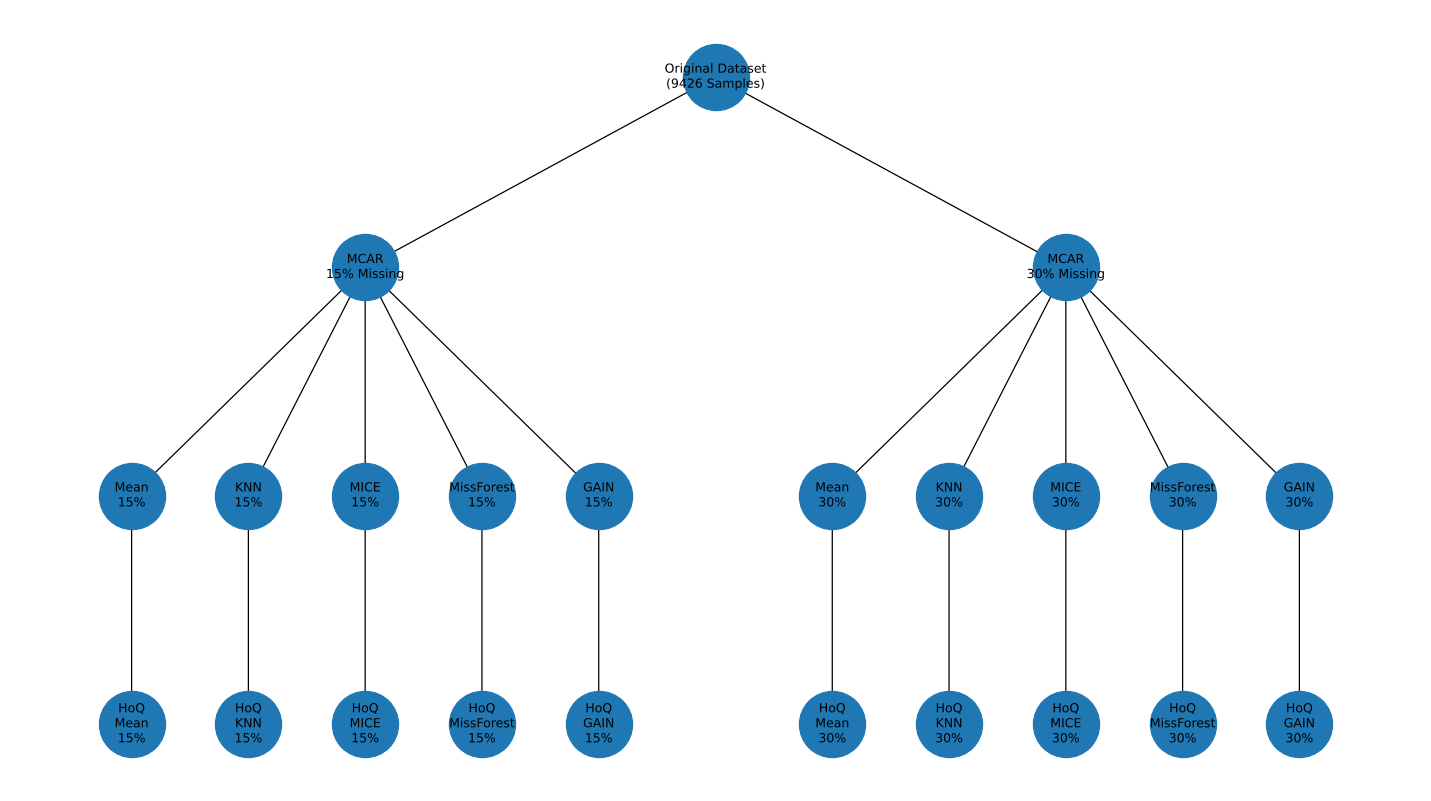

In [30]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()

# Root
G.add_edge("Original Dataset\n(9426 Samples)", "MCAR\n15% Missing")
G.add_edge("Original Dataset\n(9426 Samples)", "MCAR\n30% Missing")

methods = ["Mean", "KNN", "MICE", "MissForest", "GAIN"]

for m in methods:
    G.add_edge("MCAR\n15% Missing", f"{m}\n15%")
    G.add_edge("MCAR\n30% Missing", f"{m}\n30%")

    G.add_edge(f"{m}\n15%", f"HoQ\n{m}\n15%")
    G.add_edge(f"{m}\n30%", f"HoQ\n{m}\n30%")

# ----------------------------------------------------
# Position
# ----------------------------------------------------

pos = {}

pos["Original Dataset\n(9426 Samples)"] = (0.5,1.0)

pos["MCAR\n15% Missing"] = (0.2,0.75)
pos["MCAR\n30% Missing"] = (0.8,0.75)

x_left=[0.00,0.10,0.20,0.30,0.40]
x_right=[0.60,0.70,0.80,0.90,1.00]

for i,m in enumerate(methods):

    pos[f"{m}\n15%"]=(x_left[i],0.45)
    pos[f"{m}\n30%"]=(x_right[i],0.45)

    pos[f"HoQ\n{m}\n15%"]=(x_left[i],0.15)
    pos[f"HoQ\n{m}\n30%"]=(x_right[i],0.15)

# ----------------------------------------------------
# Draw
# ----------------------------------------------------

plt.figure(figsize=(16,9))

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2800,
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Imputation_Framework.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

%15 missing data

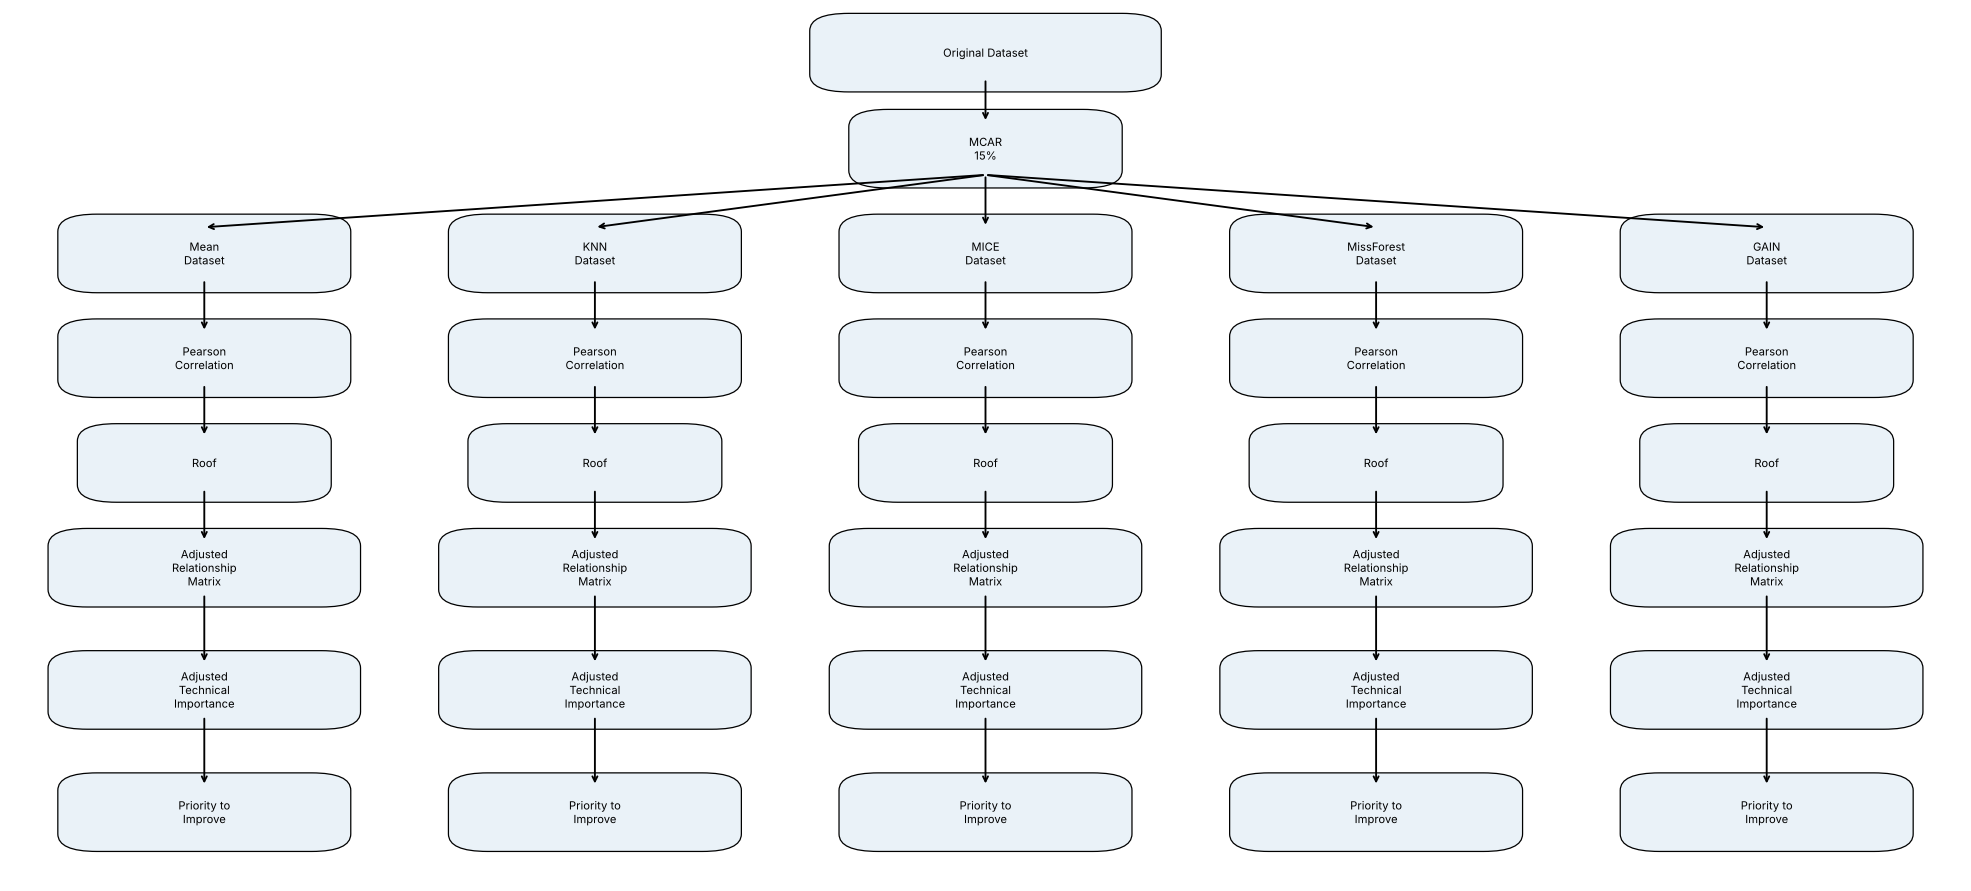

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ==========================================================
# FIGURE
# ==========================================================

fig, ax = plt.subplots(figsize=(22,10))
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.axis("off")

# ==========================================================
# BOX FUNCTION
# ==========================================================

def box(x,y,text,width=0.10,height=0.05,color="#EAF2F8"):

    rect = FancyBboxPatch(
        (x-width/2,y-height/2),
        width,
        height,
        boxstyle="round,pad=0.02",
        facecolor=color,
        edgecolor="black"
    )

    ax.add_patch(rect)

    ax.text(
        x,
        y,
        text,
        ha="center",
        va="center",
        fontsize=9
    )

def arrow(x1,y1,x2,y2):

    ax.annotate(
        "",
        xy=(x2,y2),
        xytext=(x1,y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5
        )
    )

# ==========================================================
# ROOT
# ==========================================================

box(0.5,0.95,"Original Dataset",0.14)
box(0.5,0.84,"MCAR\n15%",0.10)

arrow(0.5,0.92,0.5,0.87)

# ==========================================================
# METHODS
# ==========================================================

methods=[
    "Mean",
    "KNN",
    "MICE",
    "MissForest",
    "GAIN"
]

xs=[0.10,0.30,0.50,0.70,0.90]

# horizontal split
for x in xs:
    arrow(0.5,0.81,x,0.75)

# ==========================================================
# PIPELINES
# ==========================================================

for i,m in enumerate(methods):

    x=xs[i]

    box(x,0.72,f"{m}\nDataset",0.11)
    box(x,0.60,"Pearson\nCorrelation",0.11)
    box(x,0.48,"Roof",0.09)
    box(x,0.36,"Adjusted\nRelationship\nMatrix",0.12)
    box(x,0.22,"Adjusted\nTechnical\nImportance",0.12)
    box(x,0.08,"Priority to\nImprove",0.11)

    arrow(x,0.69,x,0.63)
    arrow(x,0.57,x,0.51)
    arrow(x,0.45,x,0.39)
    arrow(x,0.33,x,0.25)
    arrow(x,0.19,x,0.11)

plt.tight_layout()
plt.savefig("QFD_Imputation_Pipeline.png",dpi=500,bbox_inches="tight")
plt.show()

In [32]:
import numpy as np
import pandas as pd

# ============================================================
# PARAMETERS
# ============================================================

MISSING_RATE = 0.15
RANDOM_STATE = 42

# ============================================================
# [REVISION - R1-1, R1-2, R2]
# The MCAR procedure below is the same as in the first version.
# It is only written as a function so that it can be repeated
# for different missing rates and different random seeds.
# ============================================================

def create_mcar_dataset(original_data, missing_rate, random_state, verbose=True):

    np.random.seed(random_state)

    # NUMERICAL COLUMNS
    numeric_cols = original_data.select_dtypes(
        include=np.number
    ).columns.tolist()

    # CREATE MCAR MASK
    missing_mask = pd.DataFrame(
        np.random.rand(*original_data[numeric_cols].shape) < missing_rate,
        columns=numeric_cols,
        index=original_data.index
    )

    # APPLY MASK
    data_missing = original_data.copy()

    # (column assignment instead of .loc so that integer columns such as
    #  "year" can receive NaN in every pandas version)
    data_missing[numeric_cols] = (
        data_missing[numeric_cols]
        .mask(missing_mask)
    )

    # SUMMARY
    if verbose:
        total_cells = missing_mask.size
        missing_cells = missing_mask.values.sum()
        print("Numerical Columns:")
        print(numeric_cols)
        print(f"Total cells      : {total_cells:,}")
        print(f"Missing cells    : {missing_cells:,}")
        print(f"Missing rate (%) : {100*missing_cells/total_cells:.2f}")

    return data_missing

# ============================================================
# ORIGINAL DATASET  ->  15% MCAR DATASET (same as first version)
# ============================================================

original_data = payloads_clean.copy()

data_15 = create_mcar_dataset(original_data, MISSING_RATE, RANDOM_STATE)

display(data_15.head())

Numerical Columns:
['year', 'mass_kg', 'dry_mass_kg', 'power_watts', 'design_lifetime_years', 'mass_efficiency', 'power_density', 'structural_fraction', 'technology_age', 'power_per_dry_mass', 'power_adjusted_age', 'lifetime_per_mass', 'lifetime_per_power', 'capability_lifetime_index', 'dry_mass_lifetime_index']
Total cells      : 141,390
Missing cells    : 21,246
Missing rate (%) : 15.03


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.9,68.2,1484.0,6.0,0.689585,NaN,0.310415,29.0,21.759531,NaN,0.060667,0.004043,8904.0,4.137513
2,PL0000003,1993.0,57.8,34.3,27.0,2.0,0.593426,NaN,0.406574,32.0,0.787172,0.818182,0.034602,0.074074,54.0,NaN
3,PL0000004,1965.0,707.0,NaN,76.0,2.0,0.737624,0.107496,NaN,60.0,0.145733,NaN,0.002829,NaN,152.0,1.475248
4,PL0000005,1979.0,267.5,151.1,389.0,6.0,0.564860,1.454206,0.435140,46.0,2.574454,8.276596,NaN,0.015424,NaN,3.389159
6,PL0000007,1988.0,759.7,464.5,216.0,9.0,0.611426,NaN,0.388574,NaN,0.465016,5.684211,0.011847,NaN,1944.0,5.502830


In [33]:
import pandas as pd

datasets = pd.DataFrame({
    "Missing Rate": ["15%", "15%", "15%", "15%", "15%"],
    "Imputation Method": ["Mean", "KNN", "MICE", "MissForest", "GAIN"],
    "Dataset Name": [
        "dataset_mean_15",
        "dataset_knn_15",
        "dataset_mice_15",
        "dataset_missforest_15",
        "dataset_gain_15"
    ],

})

display(datasets)

,Missing Rate,Imputation Method,Dataset Name
0,15%,Mean,dataset_mean_15
1,15%,KNN,dataset_knn_15
2,15%,MICE,dataset_mice_15
3,15%,MissForest,dataset_missforest_15
4,15%,GAIN,dataset_gain_15


In [34]:
from IPython.display import display, Math

display(Math(r"""
\textbf{Mean Imputation}
"""))

display(Math(r"""
x_{ij}=
\begin{cases}
x_{ij}, & \text{if } x_{ij}\ \text{is observed} \\[6pt]
\bar{x}_j, & \text{if } x_{ij}\ \text{is missing}
\end{cases}
"""))

display(Math(r"""
\bar{x}_j=
\frac{1}{n_j}
\sum_{i:x_{ij}\neq\mathrm{NaN}}
x_{ij}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{Mean})}
=
\operatorname{MeanImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\ 15\%)}
\right)
"""))

$$\textbf{Mean Imputation}$$

$$x_{ij}=
\begin{cases}
x_{ij}, & \text{if } x_{ij}\ \text{is observed} \\[6pt]
\bar{x}_j, & \text{if } x_{ij}\ \text{is missing}
\end{cases}$$

$$\bar{x}_j=
\frac{1}{n_j}
\sum_{i:x_{ij}\neq\mathrm{NaN}}
x_{ij}$$

$$\mathbf{X}^{(\mathrm{Mean})}
=
\operatorname{MeanImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\ 15\%)}
\right)$$

In [35]:
import pandas as pd
from sklearn.impute import SimpleImputer

# ============================================================
# MEAN IMPUTATION
# [REVISION - R1-7] Same code as before, written as a function
# so it can be re-used for every missing rate / seed.
# Hyper-parameter: strategy = "mean"
# ============================================================

def impute_mean(data_missing, random_state=None, verbose=True):

    # Copy dataset
    mean_data = data_missing.copy()

    # Select numerical columns
    numeric_cols = mean_data.select_dtypes(include="number").columns

    # Mean imputer
    imputer = SimpleImputer(strategy="mean")

    # Apply mean imputation
    mean_data[numeric_cols] = imputer.fit_transform(
        mean_data[numeric_cols]
    )

    if verbose:
        print("="*55)
        print("MEAN IMPUTATION COMPLETED")
        print("="*55)
        print(f"Missing values before : {data_missing[numeric_cols].isna().sum().sum()}")
        print(f"Missing values after  : {mean_data[numeric_cols].isna().sum().sum()}")
        print(f"Numerical columns     : {len(numeric_cols)}")
        print("="*55)

    return mean_data

# ============================================================
# 15% MCAR DATASET
# ============================================================

dataset_mean_15 = impute_mean(data_15)

display(dataset_mean_15.head())

MEAN IMPUTATION COMPLETED
Missing values before : 21246
Missing values after  : 0
Numerical columns     : 15


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.9,68.200000,1484.0,6.0,0.689585,12.008650,0.310415,29.000000,21.759531,61.840878,0.060667,0.004043,8904.000000,4.137513
2,PL0000003,1993.0,57.8,34.300000,27.0,2.0,0.593426,12.008650,0.406574,32.000000,0.787172,0.818182,0.034602,0.074074,54.000000,6.412418
3,PL0000004,1965.0,707.0,433.495002,76.0,2.0,0.737624,0.107496,0.325228,60.000000,0.145733,61.840878,0.002829,0.024229,152.000000,1.475248
4,PL0000005,1979.0,267.5,151.100000,389.0,6.0,0.564860,1.454206,0.435140,46.000000,2.574454,8.276596,0.101679,0.015424,10476.874139,3.389159
6,PL0000007,1988.0,759.7,464.500000,216.0,9.0,0.611426,12.008650,0.388574,34.685455,0.465016,5.684211,0.011847,0.024229,1944.000000,5.502830


In [36]:
from IPython.display import display, Math

display(Math(r"""
\textbf{K-Nearest Neighbors (KNN) Imputation}
"""))

display(Math(r"""
\mathcal{N}_k(x_i)
=
\{x_{i_1},x_{i_2},\ldots,x_{i_k}\}
"""))

display(Math(r"""
x_{ij}=
\frac{1}{k}
\sum_{x_r\in\mathcal{N}_k(x_i)}
x_{rj}
"""))

display(Math(r"""
d(x_i,x_r)=
\sqrt{
\sum_{l\in\mathcal{O}}
(x_{il}-x_{rl})^2
}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{KNN})}
=
\operatorname{KNNImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

$$\textbf{K-Nearest Neighbors (KNN) Imputation}$$

$$\mathcal{N}_k(x_i)
=
\{x_{i_1},x_{i_2},\ldots,x_{i_k}\}$$

$$x_{ij}=
\frac{1}{k}
\sum_{x_r\in\mathcal{N}_k(x_i)}
x_{rj}$$

$$d(x_i,x_r)=
\sqrt{
\sum_{l\in\mathcal{O}}
(x_{il}-x_{rl})^2
}$$

$$\mathbf{X}^{(\mathrm{KNN})}
=
\operatorname{KNNImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)$$

In [37]:
import pandas as pd
from sklearn.impute import KNNImputer

# ============================================================
# KNN IMPUTATION
# [REVISION - R1-7] Same code as before, written as a function.
# Hyper-parameters: n_neighbors = 5, weights = "uniform",
#                   metric = "nan_euclidean" (scikit-learn default)
# ============================================================

def impute_knn(data_missing, random_state=None, verbose=True):

    # Copy dataset
    knn_data = data_missing.copy()

    # Numerical columns
    numeric_cols = knn_data.select_dtypes(include="number").columns

    # KNN Imputer
    imputer = KNNImputer(
        n_neighbors=5,
        weights="uniform"
    )

    # Apply KNN Imputation
    knn_data[numeric_cols] = imputer.fit_transform(
        knn_data[numeric_cols]
    )

    if verbose:
        print("="*55)
        print("KNN IMPUTATION COMPLETED")
        print("="*55)
        print(f"Missing values before : {data_missing[numeric_cols].isna().sum().sum()}")
        print(f"Missing values after  : {knn_data[numeric_cols].isna().sum().sum()}")
        print(f"Numerical columns     : {len(numeric_cols)}")
        print("="*55)

    return knn_data

# ============================================================
# 15% MCAR DATASET
# ============================================================

dataset_knn_15 = impute_knn(data_15)

display(dataset_knn_15.head())

KNN IMPUTATION COMPLETED
Missing values before : 21246
Missing values after  : 0
Numerical columns     : 15


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.9,68.20,1484.0,6.0,0.689585,11.116482,0.310415,29.0,21.759531,35.925401,0.060667,0.004043,8904.0,4.137513
2,PL0000003,1993.0,57.8,34.30,27.0,2.0,0.593426,5.057663,0.406574,32.0,0.787172,0.818182,0.034602,0.074074,54.0,8.474181
3,PL0000004,1965.0,707.0,2655.54,76.0,2.0,0.737624,0.107496,0.299783,60.0,0.145733,16.751477,0.002829,0.012073,152.0,1.475248
4,PL0000005,1979.0,267.5,151.10,389.0,6.0,0.564860,1.454206,0.435140,46.0,2.574454,8.276596,0.024631,0.015424,2952.0,3.389159
6,PL0000007,1988.0,759.7,464.50,216.0,9.0,0.611426,2.189565,0.388574,42.2,0.465016,5.684211,0.011847,0.051642,1944.0,5.502830


In [38]:
from IPython.display import display, Math

display(Math(r"""
\textbf{Multiple Imputation by Chained Equations (MICE)}
"""))

display(Math(r"""
x_{ij}^{(t)}
=
f_j
\left(
X_{-j}^{(t-1)}
\right)
+
\varepsilon
"""))

display(Math(r"""
X_j
\sim
P
\left(
X_j
\mid
X_{-j}
\right)
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{MICE})}
=
\operatorname{IterativeImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

$$\textbf{Multiple Imputation by Chained Equations (MICE)}$$

$$x_{ij}^{(t)}
=
f_j
\left(
X_{-j}^{(t-1)}
\right)
+
\varepsilon$$

$$X_j
\sim
P
\left(
X_j
\mid
X_{-j}
\right)$$

$$\mathbf{X}^{(\mathrm{MICE})}
=
\operatorname{IterativeImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)$$

In [39]:
import pandas as pd

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# ============================================================
# MICE IMPUTATION
# [REVISION - R1-7] Same code as before, written as a function.
# Hyper-parameters: estimator = BayesianRidge (scikit-learn default),
#                   max_iter = 10, initial_strategy = "mean",
#                   random_state = seed
# ============================================================

def impute_mice(data_missing, random_state=42, verbose=True):

    # Copy dataset
    mice_data = data_missing.copy()

    # Numerical columns
    numeric_cols = mice_data.select_dtypes(include="number").columns

    # MICE Imputer
    imputer = IterativeImputer(
        random_state=random_state,
        max_iter=10
    )

    # Apply MICE
    mice_data[numeric_cols] = imputer.fit_transform(
        mice_data[numeric_cols]
    )

    if verbose:
        print("="*55)
        print("MICE IMPUTATION COMPLETED")
        print("="*55)
        print(f"Missing values before : {data_missing[numeric_cols].isna().sum().sum()}")
        print(f"Missing values after  : {mice_data[numeric_cols].isna().sum().sum()}")
        print(f"Numerical columns     : {len(numeric_cols)}")
        print("="*55)

    return mice_data

# ============================================================
# 15% MCAR DATASET
# ============================================================

dataset_mice_15 = impute_mice(data_15)

display(dataset_mice_15.head())

MICE IMPUTATION COMPLETED
Missing values before : 21246
Missing values after  : 0
Numerical columns     : 15


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.9,68.200000,1484.0,6.0,0.689585,14.766260,0.310415,29.0,21.759531,102.139770,0.060667,0.004043,8904.000000,4.137513
2,PL0000003,1993.0,57.8,34.300000,27.0,2.0,0.593426,-0.888319,0.406574,32.0,0.787172,0.818182,0.034602,0.074074,54.000000,0.615772
3,PL0000004,1965.0,707.0,523.710283,76.0,2.0,0.737624,0.107496,0.262376,60.0,0.145733,-78.380683,0.002829,0.005688,152.000000,1.475248
4,PL0000005,1979.0,267.5,151.100000,389.0,6.0,0.564860,1.454206,0.435140,46.0,2.574454,8.276596,0.070060,0.015424,-463.433274,3.389159
6,PL0000007,1988.0,759.7,464.500000,216.0,9.0,0.611426,-0.838915,0.388574,37.0,0.465016,5.684211,0.011847,0.028282,1944.000000,5.502830


In [40]:
from IPython.display import display, Math

display(Math(r"""
\textbf{Mean Imputation}
"""))

display(Math(r"""
x_{ij}=
\begin{cases}
x_{ij}, & \text{if } x_{ij}\ \text{is observed} \\[6pt]
\bar{x}_j, & \text{if } x_{ij}\ \text{is missing}
\end{cases}
"""))

display(Math(r"""
\bar{x}_j=
\frac{1}{n_j}
\sum_{i:x_{ij}\neq\mathrm{NaN}}
x_{ij}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{Mean})}
=
\operatorname{MeanImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\ 15\%)}
\right)
"""))
from IPython.display import display, Math

display(Math(r"""
\textbf{K-Nearest Neighbors (KNN) Imputation}
"""))

display(Math(r"""
\mathcal{N}_k(x_i)
=
\{x_{i_1},x_{i_2},\ldots,x_{i_k}\}
"""))

display(Math(r"""
x_{ij}=
\frac{1}{k}
\sum_{x_r\in\mathcal{N}_k(x_i)}
x_{rj}
"""))

display(Math(r"""
d(x_i,x_r)=
\sqrt{
\sum_{l\in\mathcal{O}}
(x_{il}-x_{rl})^2
}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{KNN})}
=
\operatorname{KNNImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))
from IPython.display import display, Math

display(Math(r"""
\textbf{Multiple Imputation by Chained Equations (MICE)}
"""))

display(Math(r"""
x_{ij}^{(t)}
=
f_j
\left(
X_{-j}^{(t-1)}
\right)
+
\varepsilon
"""))

display(Math(r"""
X_j
\sim
P
\left(
X_j
\mid
X_{-j}
\right)
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{MICE})}
=
\operatorname{IterativeImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

from IPython.display import display, Math

display(Math(r"\textbf{MissForest Imputation}"))

display(Math(r"""
x_{ij}^{(t)}
=
f_{\mathrm{RF}}
\left(
X_{-j}^{(t-1)}
\right)
"""))

display(Math(r"""
f_{\mathrm{RF}}
=
\frac{1}{B}
\sum_{b=1}^{B}
T_b
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{MissForest})}
=
\operatorname{RF\text{-}IterativeImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

from IPython.display import display, Math

display(Math(r"\textbf{Generative Adversarial Imputation Networks (GAIN)}"))

display(Math(r"""
\tilde{\mathbf{X}}
=
\mathbf{M}\odot\mathbf{X}
+
(1-\mathbf{M})\odot\mathbf{Z}
"""))

display(Math(r"""
\hat{\mathbf{X}}
=
G(\tilde{\mathbf{X}},\mathbf{M})
"""))

display(Math(r"""
\hat{\mathbf{M}}
=
D(\hat{\mathbf{X}},\mathbf{H})
"""))

display(Math(r"""
\min_G \max_D
\;
\mathcal{L}_{GAIN}
=
\mathcal{L}_{adv}
+
\alpha
\mathcal{L}_{rec}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{GAIN})}
=
G
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

$$\textbf{Mean Imputation}$$

$$x_{ij}=
\begin{cases}
x_{ij}, & \text{if } x_{ij}\ \text{is observed} \\[6pt]
\bar{x}_j, & \text{if } x_{ij}\ \text{is missing}
\end{cases}$$

$$\bar{x}_j=
\frac{1}{n_j}
\sum_{i:x_{ij}\neq\mathrm{NaN}}
x_{ij}$$

$$\mathbf{X}^{(\mathrm{Mean})}
=
\operatorname{MeanImputer}
\left(
\mathbf{X}^{(\mathrm{MCAR}\ 15\%)}
\right)$$

$$\textbf{K-Nearest Neighbors (KNN) Imputation}$$

$$\mathcal{N}_k(x_i)
=
\{x_{i_1},x_{i_2},\ldots,x_{i_k}\}$$

... (13 outputs left out)

$$\hat{\mathbf{X}}
=
G(\tilde{\mathbf{X}},\mathbf{M})$$

$$\hat{\mathbf{M}}
=
D(\hat{\mathbf{X}},\mathbf{H})$$

$$\min_G \max_D
\;
\mathcal{L}_{GAIN}
=
\mathcal{L}_{adv}
+
\alpha
\mathcal{L}_{rec}$$

$$\mathbf{X}^{(\mathrm{GAIN})}
=
G
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)$$

In [41]:
import pandas as pd

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# MISSFOREST IMPUTATION
# [REVISION - R1-7] Same code as before, written as a function.
# Hyper-parameters: RandomForestRegressor(n_estimators = 50,
#                   max_depth = 10), max_iter = 5,
#                   initial_strategy = "mean", random_state = seed
# ============================================================

def impute_missforest(data_missing, random_state=42, verbose=True):

    # Copy dataset
    missforest_data = data_missing.copy()

    # Select numerical columns
    numeric_cols = missforest_data.select_dtypes(include="number").columns

    # MissForest-like Imputer (Random Forest)
    imputer = IterativeImputer(
        estimator=RandomForestRegressor(
            n_estimators=50,      # Faster than 100
            max_depth=10,         # Limits tree depth
            random_state=random_state,
            n_jobs=-1
        ),
        max_iter=5,               # Faster convergence
        initial_strategy="mean",
        random_state=random_state
    )

    # Apply imputation
    missforest_data[numeric_cols] = imputer.fit_transform(
        missforest_data[numeric_cols]
    )

    if verbose:
        print("=" * 60)
        print("MISSFOREST IMPUTATION COMPLETED")
        print("=" * 60)
        print(f"Missing values before : {data_missing[numeric_cols].isna().sum().sum()}")
        print(f"Missing values after  : {missforest_data[numeric_cols].isna().sum().sum()}")
        print(f"Numerical columns     : {len(numeric_cols)}")
        print("=" * 60)

    return missforest_data

# ============================================================
# 15% MCAR DATASET
# ============================================================

dataset_missforest_15 = impute_missforest(data_15)

display(dataset_missforest_15.head())

MISSFOREST IMPUTATION COMPLETED
Missing values before : 21246
Missing values after  : 0
Numerical columns     : 15


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.9,68.200000,1484.0,6.0,0.689585,15.116976,0.310415,29.0,21.759531,50.255873,0.060667,0.004043,8904.000000,4.137513
2,PL0000003,1993.0,57.8,34.300000,27.0,2.0,0.593426,0.511439,0.406574,32.0,0.787172,0.818182,0.034602,0.074074,54.000000,1.188246
3,PL0000004,1965.0,707.0,523.364677,76.0,2.0,0.737624,0.107496,0.262373,60.0,0.145733,1.712082,0.002829,0.029872,152.000000,1.475248
4,PL0000005,1979.0,267.5,151.100000,389.0,6.0,0.564860,1.454206,0.435140,46.0,2.574454,8.276596,0.022097,0.015424,2332.246682,3.389159
6,PL0000007,1988.0,759.7,464.500000,216.0,9.0,0.611426,0.314896,0.388574,37.0,0.465016,5.684211,0.011847,0.041638,1944.000000,5.502830


In [42]:
from IPython.display import display, Math

display(Math(r"\textbf{Generative Adversarial Imputation Networks (GAIN)}"))

display(Math(r"""
\tilde{\mathbf{X}}
=
\mathbf{M}\odot\mathbf{X}
+
(1-\mathbf{M})\odot\mathbf{Z}
"""))

display(Math(r"""
\hat{\mathbf{X}}
=
G(\tilde{\mathbf{X}},\mathbf{M})
"""))

display(Math(r"""
\hat{\mathbf{M}}
=
D(\hat{\mathbf{X}},\mathbf{H})
"""))

display(Math(r"""
\min_G \max_D
\;
\mathcal{L}_{GAIN}
=
\mathcal{L}_{adv}
+
\alpha
\mathcal{L}_{rec}
"""))

display(Math(r"""
\mathbf{X}^{(\mathrm{GAIN})}
=
G
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)
"""))

$$\textbf{Generative Adversarial Imputation Networks (GAIN)}$$

$$\tilde{\mathbf{X}}
=
\mathbf{M}\odot\mathbf{X}
+
(1-\mathbf{M})\odot\mathbf{Z}$$

$$\hat{\mathbf{X}}
=
G(\tilde{\mathbf{X}},\mathbf{M})$$

$$\hat{\mathbf{M}}
=
D(\hat{\mathbf{X}},\mathbf{H})$$

$$\min_G \max_D
\;
\mathcal{L}_{GAIN}
=
\mathcal{L}_{adv}
+
\alpha
\mathcal{L}_{rec}$$

$$\mathbf{X}^{(\mathrm{GAIN})}
=
G
\left(
\mathbf{X}^{(\mathrm{MCAR}\;15\%)}
\right)$$

In [43]:
pip install torch

(skipped: package install)


In [44]:
import random
import numpy as np
import pandas as pd

# ============================================================
# GAIN IMPUTATION
# [REVISION - R1-7] Same PyTorch code as before, written as a function.
# Hyper-parameters: BATCH_SIZE = 128, EPOCHS = 300, HINT_RATE = 0.90,
#                   ALPHA = 100, LEARNING_RATE = 0.001 (Adam),
#                   hidden_dim = max(32, 2 x number of variables),
#                   2 hidden layers (ReLU) + Sigmoid output for G and D
# If PyTorch is not installed, an equivalent NumPy implementation
# (gain_numpy.py, same architecture and hyper-parameters) is used.
# ============================================================

BATCH_SIZE = 128
EPOCHS = 300
HINT_RATE = 0.90
ALPHA = 100.0
LEARNING_RATE = 0.001

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    GAIN_BACKEND = "torch"
except ImportError:
    from gain_numpy import gain_impute
    GAIN_BACKEND = "numpy"

print("GAIN backend:", GAIN_BACKEND)

if GAIN_BACKEND == "torch":

    # ============================================================
    # GENERATOR
    # Input: incomplete data + mask
    # Output: imputed values
    # ============================================================

    class Generator(nn.Module):

        def __init__(self, input_dim, hidden_dim):
            super().__init__()

            self.network = nn.Sequential(
                nn.Linear(input_dim * 2, hidden_dim),
                nn.ReLU(),

                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),

                nn.Linear(hidden_dim, input_dim),
                nn.Sigmoid()
            )

        def forward(self, x_tilde, mask):
            generator_input = torch.cat([x_tilde, mask], dim=1)
            return self.network(generator_input)

    # ============================================================
    # DISCRIMINATOR
    # Input: completed data + hint matrix
    # Output: probability that each value was observed
    # ============================================================

    class Discriminator(nn.Module):

        def __init__(self, input_dim, hidden_dim):
            super().__init__()

            self.network = nn.Sequential(
                nn.Linear(input_dim * 2, hidden_dim),
                nn.ReLU(),

                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),

                nn.Linear(hidden_dim, input_dim),
                nn.Sigmoid()
            )

        def forward(self, completed_x, hint):
            discriminator_input = torch.cat([completed_x, hint], dim=1)
            return self.network(discriminator_input)


def impute_gain(data_missing, random_state=42, verbose=True):

    gain_data = data_missing.copy()

    numeric_cols = gain_data.select_dtypes(
        include=np.number
    ).columns.tolist()

    X_raw = gain_data[numeric_cols].to_numpy(dtype=np.float32)

    # ------------------------------------------------------------
    # NumPy backend (only if torch is not available)
    # ------------------------------------------------------------
    if GAIN_BACKEND == "numpy":
        n_iter = EPOCHS * int(np.ceil(len(X_raw) / BATCH_SIZE))
        gain_data[numeric_cols] = gain_impute(
            X_raw.astype(float), batch_size=BATCH_SIZE, hint_rate=HINT_RATE,
            alpha=ALPHA, iterations=n_iter, learning_rate=LEARNING_RATE,
            random_state=random_state
        )
        return gain_data

    # ------------------------------------------------------------
    # PyTorch backend (first-version code)
    # ------------------------------------------------------------
    random.seed(random_state)
    np.random.seed(random_state)
    torch.manual_seed(random_state)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Missing mask: 1 = observed, 0 = missing
    M = (~np.isnan(X_raw)).astype(np.float32)

    # MIN-MAX NORMALIZATION USING OBSERVED VALUES ONLY
    col_min = np.nanmin(X_raw, axis=0)
    col_max = np.nanmax(X_raw, axis=0)

    col_range = col_max - col_min
    col_range[col_range == 0] = 1.0

    X_norm_gain = (X_raw - col_min) / col_range

    X_zero = np.nan_to_num(X_norm_gain, nan=0.0).astype(np.float32)

    X_tensor = torch.tensor(X_zero, dtype=torch.float32)
    M_tensor = torch.tensor(M, dtype=torch.float32)

    train_loader = DataLoader(
        TensorDataset(X_tensor, M_tensor),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    input_dim = X_zero.shape[1]
    hidden_dim = max(32, input_dim * 2)

    generator = Generator(input_dim, hidden_dim).to(device)
    discriminator = Discriminator(input_dim, hidden_dim).to(device)

    generator_optimizer = torch.optim.Adam(generator.parameters(), lr=LEARNING_RATE)
    discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=LEARNING_RATE)

    eps = 1e-8

    # TRAINING
    generator.train()
    discriminator.train()

    for epoch in range(1, EPOCHS + 1):

        epoch_d_loss = 0.0
        epoch_g_loss = 0.0
        batch_count = 0

        for x_batch, m_batch in train_loader:

            x_batch = x_batch.to(device)
            m_batch = m_batch.to(device)

            z_batch = torch.rand_like(x_batch) * 0.01

            x_tilde = m_batch * x_batch + (1.0 - m_batch) * z_batch

            # HINT MATRIX
            hint_selector = (torch.rand_like(m_batch) < HINT_RATE).float()
            hint = hint_selector * m_batch + (1.0 - hint_selector) * 0.5

            # TRAIN DISCRIMINATOR
            discriminator_optimizer.zero_grad()

            generated_x = generator(x_tilde, m_batch)
            completed_x = m_batch * x_batch + (1.0 - m_batch) * generated_x

            discriminator_prob = discriminator(completed_x.detach(), hint)

            discriminator_loss = -torch.mean(
                m_batch * torch.log(discriminator_prob + eps)
                + (1.0 - m_batch) * torch.log(1.0 - discriminator_prob + eps)
            )

            discriminator_loss.backward()
            discriminator_optimizer.step()

            # TRAIN GENERATOR
            generator_optimizer.zero_grad()

            generated_x = generator(x_tilde, m_batch)
            completed_x = m_batch * x_batch + (1.0 - m_batch) * generated_x

            discriminator_prob = discriminator(completed_x, hint)

            adversarial_loss = -torch.sum(
                (1.0 - m_batch) * torch.log(discriminator_prob + eps)
            ) / (torch.sum(1.0 - m_batch) + eps)

            reconstruction_loss = torch.sum(
                m_batch * torch.square(x_batch - generated_x)
            ) / (torch.sum(m_batch) + eps)

            generator_loss = adversarial_loss + ALPHA * reconstruction_loss

            generator_loss.backward()
            generator_optimizer.step()

            epoch_d_loss += discriminator_loss.item()
            epoch_g_loss += generator_loss.item()
            batch_count += 1

        if verbose and (epoch == 1 or epoch % 25 == 0):
            print(
                f"Epoch {epoch:03d}/{EPOCHS} | "
                f"D Loss: {epoch_d_loss / batch_count:.6f} | "
                f"G Loss: {epoch_g_loss / batch_count:.6f}"
            )

    # IMPUTE FULL DATASET
    generator.eval()

    with torch.no_grad():
        full_x = X_tensor.to(device)
        full_m = M_tensor.to(device)
        full_noise = torch.rand_like(full_x) * 0.01
        full_x_tilde = full_m * full_x + (1.0 - full_m) * full_noise
        generated_full = generator(full_x_tilde, full_m)
        completed_norm = (full_m * full_x + (1.0 - full_m) * generated_full).cpu().numpy()

    # INVERSE NORMALIZATION
    completed_original_scale = completed_norm * col_range + col_min

    # Preserve observed values exactly; replace only missing cells
    X_imputed = X_raw.copy()
    missing_positions = np.isnan(X_imputed)
    X_imputed[missing_positions] = completed_original_scale[missing_positions]

    gain_data[numeric_cols] = X_imputed

    return gain_data

# ============================================================
# 15% MCAR DATASET
# ============================================================

dataset_gain_15 = impute_gain(data_15)

print("\n" + "=" * 60)
print("GAIN IMPUTATION COMPLETED")
print("=" * 60)
print("Dataset Name          : dataset_gain_15")
print(f"Rows                  : {len(dataset_gain_15):,}")
print(f"Missing values before : {data_15.select_dtypes(include=np.number).isna().sum().sum():,}")
print(f"Missing values after  : {dataset_gain_15.select_dtypes(include=np.number).isna().sum().sum():,}")
print("=" * 60)

display(dataset_gain_15.head())

GAIN backend: numpy

GAIN IMPUTATION COMPLETED
Dataset Name          : dataset_gain_15
Rows                  : 9,426
Missing values before : 21,246
Missing values after  : 0


,payload_id,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years,mass_efficiency,power_density,structural_fraction,technology_age,power_per_dry_mass,power_adjusted_age,lifetime_per_mass,lifetime_per_power,capability_lifetime_index,dry_mass_lifetime_index
1,PL0000002,1996.0,98.900002,68.199997,1484.0,6.0,0.689585,12.696182,0.310415,29.000000,21.759531,54.059626,0.060667,0.004043,8904.000000,4.137513
2,PL0000003,1993.0,57.799999,34.299999,27.0,2.0,0.593426,1.429253,0.406574,32.000000,0.787172,0.818182,0.034602,0.074074,54.000000,4.358943
3,PL0000004,1965.0,707.000000,630.787563,76.0,2.0,0.737624,0.107496,0.326585,60.000000,0.145733,3.667918,0.002829,0.015471,152.000000,1.475248
4,PL0000005,1979.0,267.500000,151.100006,389.0,6.0,0.564860,1.454206,0.435140,46.000000,2.574454,8.276596,0.062118,0.015424,3577.932524,3.389159
6,PL0000007,1988.0,759.700012,464.500000,216.0,9.0,0.611426,2.785728,0.388574,51.657396,0.465016,5.684210,0.011847,0.036462,1944.000000,5.502830


In [45]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display, Math

# ============================================================
# [REVISION - R1-3, R1-4, R1-8, R1-9, R2]
# The function is unchanged, only four parameters were added.
# Their default values reproduce the first version exactly:
#   lambda_value  = 0.50        (R1-3: lambda sensitivity)
#   negative_mode = "positive"  (R1-4: "positive" = max(0,Q),
#                                "signed" = Q, "absolute" = |Q|)
#   corr_method   = "pearson"   (R1-8: "pearson" or "spearman")
#   evaluation    = None        (R1-5/R1-9: alternative CP/T/D/CT table;
#                                None = technical_evaluation)
# ============================================================

def run_adjusted_qfd(dataset, show=True, lambda_value=0.50,
                     negative_mode="positive", corr_method="pearson",
                     evaluation=None):

    if evaluation is None:
        evaluation = technical_evaluation

    # ============================================================
    # TECHNICAL CHARACTERISTICS
    # ============================================================

    tc_columns = [
        "year",
        "mass_kg",
        "dry_mass_kg",
        "power_watts",
        "design_lifetime_years",
        "mass_efficiency",
        "power_density",
        "structural_fraction",
        "technology_age",
        "power_per_dry_mass",
        "power_adjusted_age",
        "lifetime_per_mass",
        "lifetime_per_power",
        "capability_lifetime_index",
        "dry_mass_lifetime_index"
    ]

    tc_codes = [f"TC{i}" for i in range(1,16)]

    tc_names = {
        "TC1":"Launch Year",
        "TC2":"Payload Mass",
        "TC3":"Dry Mass",
        "TC4":"Power Consumption",
        "TC5":"Design Lifetime",
        "TC6":"Mass Efficiency",
        "TC7":"Power Density",
        "TC8":"Structural Fraction",
        "TC9":"Technology Age",
        "TC10":"Power per Dry Mass",
        "TC11":"Power-Adjusted Age",
        "TC12":"Lifetime per Mass",
        "TC13":"Lifetime per Power",
        "TC14":"Capability-Lifetime Index",
        "TC15":"Dry-Mass Lifetime Index"
    }

    tc_cols = [f"TC{i}" for i in range(1,16)]

    X_tc = dataset[tc_columns].copy()
    X_tc.columns = tc_codes

    # ============================================================
    # NORMALIZATION
    # ============================================================

    scaler = MinMaxScaler()

    X_norm = pd.DataFrame(
        scaler.fit_transform(X_tc),
        columns=tc_codes,
        index=X_tc.index
    )

    # ============================================================
    # PEARSON CORRELATION
    # ============================================================

    if show:

        display(Math(
            r"(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}"
            r"{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}"
            r"\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}"
        ))

        print("r_jk : Pearson correlation coefficient")
        print("TC_j : Technical Characteristic j")
        print("TC_k : Technical Characteristic k")
        print()

    tc_corr = X_norm.corr(method=corr_method)

    if show:
        print("Pearson Correlation Matrix")
        display(tc_corr.round(3))

    # ============================================================
    # CONTINUOUS ROOF MATRIX
    # ============================================================

    if show:

        display(Math(
            r"(2)\quad Q_{jk}=r_{jk}"
        ))

        print("Q_jk : Continuous roof relationship")
        print("Range : [-1,1]")
        print("Positive values indicate technical synergy.")
        print("Negative values indicate technical trade-offs.")
        print()

    roof_matrix = tc_corr.copy()

    # [compatibility] pandas >= 3 returns a read-only .values array, so the diagonal is
    # set on a copy (identical result with pandas 2)
    roof_values = roof_matrix.to_numpy(copy=True)
    np.fill_diagonal(roof_values, 0)
    roof_matrix = pd.DataFrame(roof_values, index=roof_matrix.index, columns=roof_matrix.columns)

    if show:
        print("Continuous House of Quality Roof Matrix")
        display(
            roof_matrix.round(3)
        )

    # ============================================================
    # TC DEFINITIONS
    # ============================================================

    tc_definition_table = pd.DataFrame({

        "TC Code":list(tc_names.keys()),
        "Technical Characteristic":list(tc_names.values())

    })

    if show:

        print("Technical Characteristics")

        display(
            tc_definition_table
        )

    # ============================================================
    # ADJUSTED RELATIONSHIP MATRIX
    # ============================================================

    if show:

        display(Math(
            r"R^{*}=R(I+\lambda Q_n)"
        ))

        display(Math(
            r"Q_n=\max(0,Q)"
        ))

    R = relationship_matrix[
        tc_cols
    ].astype(float)

    Q = roof_matrix.loc[
        tc_cols,
        tc_cols
    ].astype(float)

    if negative_mode == "positive":      # first version
        Qn = Q.clip(lower=0)
    elif negative_mode == "signed":
        Qn = Q.copy()
    elif negative_mode == "absolute":
        Qn = Q.abs()
    else:
        raise ValueError(negative_mode)

    I = np.eye(
        len(tc_cols)
    )

    adjusted_relationship_matrix = pd.DataFrame(

        R.values @ (I + lambda_value*Qn.values),

        index=R.index,

        columns=R.columns

    )

    adjusted_relationship_matrix = adjusted_relationship_matrix.clip(
        lower=0
    )

    if show:

        display(Math(
            rf"\lambda={lambda_value}"
        ))

        print("Adjusted Relationship Matrix")

        display(
            adjusted_relationship_matrix.round(3)
        )

    # ============================================================
    # COMPLETE ADJUSTED HOUSE OF QUALITY
    # ============================================================

    roof_part = roof_matrix.loc[
        tc_cols,
        tc_cols
    ].copy()

    roof_part.insert(
        0,
        "CR / TC",
        roof_part.index
    )

    roof_part.insert(
        0,
        "Customer Importance Score",
        ""
    )

    separator = pd.DataFrame(

        [[
            "Customer Importance Score",
            "CR / TC",
            *tc_cols
        ]],

        columns=roof_part.columns

    )

    adjusted_part = adjusted_relationship_matrix[
        tc_cols
    ].round(2).copy()

    adjusted_part.insert(
        0,
        "CR / TC",
        adjusted_part.index
    )

    adjusted_part.insert(
        0,
        "Customer Importance Score",
        cr_importance_scores
    )

    full_adjusted_hoq = pd.concat(

        [
            roof_part,
            separator,
            adjusted_part
        ],

        ignore_index=True

    )

    if show:

        print("Complete Adjusted House of Quality Matrix")

        display(
            full_adjusted_hoq
        )

    # ============================================================
    # TECHNICAL IMPORTANCE SCORE
    # ============================================================

    importance = np.array(
        cr_importance_scores
    )

    adjusted_technical_importance = (

        importance @
        adjusted_relationship_matrix[
            tc_cols
        ].values

    )

    technical_importance_row = pd.DataFrame(

        [[
            "",
            "Technical Importance Score",
            *adjusted_technical_importance
        ]],

        columns=full_adjusted_hoq.columns

    )

    full_adjusted_hoq = pd.concat(

        [
            full_adjusted_hoq,
            technical_importance_row
        ],

        ignore_index=True

    )

    if show:

        print("Technical Importance Score")

        display(
            full_adjusted_hoq.round(3)
        )

    # ============================================================
    # IMPORTANCE (%)
    # ============================================================

    importance_percent = (

        adjusted_technical_importance /
        adjusted_technical_importance.sum()

    ) * 100

    importance_percent = np.round(
        importance_percent,
        2
    )

    importance_percent_row = pd.DataFrame(

        [[
            "",
            "Importance (%)",
            *importance_percent
        ]],

        columns=full_adjusted_hoq.columns

    )

    full_adjusted_hoq = pd.concat(

        [
            full_adjusted_hoq,
            importance_percent_row
        ],

        ignore_index=True

    )

    if show:

        display(
            full_adjusted_hoq.round(3)
        )

    # ============================================================
    # PRIORITY RANK
    # ============================================================

    priority_rank = (

        pd.Series(
            adjusted_technical_importance
        )

        .rank(
            ascending=False,
            method="dense"
        )

        .astype(int)

        .to_numpy()

    )

    priority_rank_row = pd.DataFrame(

        [[
            "",
            "Priority Rank",
            *priority_rank
        ]],

        columns=full_adjusted_hoq.columns

    )

    full_adjusted_hoq = pd.concat(

        [
            full_adjusted_hoq,
            priority_rank_row
        ],

        ignore_index=True

    )

    if show:

        display(
            full_adjusted_hoq.round(3)
        )

    # ============================================================
    # TECHNICAL EVALUATION SUMMARY
    # ============================================================

    summary_rows = pd.DataFrame(

        [

            [
                "",
                "Current Performance",
                *evaluation["Current Performance"].values
            ],

            [
                "",
                "Target",
                *evaluation["Target"].values
            ],

            [
                "",
                "Difficulty",
                *evaluation["Difficulty"].values
            ],

            [
                "",
                "Cost and Time",
                *evaluation["Cost and Time"].values
            ]

        ],

        columns=full_adjusted_hoq.columns

    )

    full_adjusted_hoq = pd.concat(

        [
            full_adjusted_hoq,
            summary_rows
        ],

        ignore_index=True

    )

    if show:

        print("Technical Evaluation Summary")

        display(
            full_adjusted_hoq.round(3)
        )

    # ============================================================
    # PRIORITY TO IMPROVE
    # ============================================================

    priority_to_improve = (

        (
            evaluation["Target"].values
            -
            evaluation["Current Performance"].values
        )

        * importance_percent

        /

        (
            evaluation["Difficulty"].values
            +
            evaluation["Cost and Time"].values
        )

    )

    # ============================================================
    # PRIORITY TO IMPROVE (%)
    # ============================================================

    priority_to_improve_percent = (

        priority_to_improve
        /
        priority_to_improve.sum()

    ) * 100

    priority_to_improve_percent = np.round(
        priority_to_improve_percent,
        2
    )

    # ============================================================
    # PRIORITY TO IMPROVE RANK
    # ============================================================

    priority_to_improve_rank = (

        pd.Series(
            priority_to_improve_percent
        )

        .rank(
            ascending=False,
            method="dense"
        )

        .astype(int)

        .to_numpy()

    )

    # ============================================================
    # ADD TO HOUSE OF QUALITY
    # ============================================================

    priority_rows = pd.DataFrame(

        [

            [
                "",
                "Priority to Improve",
                *np.round(priority_to_improve,4)
            ],

            [
                "",
                "Priority to Improve (%)",
                *priority_to_improve_percent
            ],

            [
                "",
                "Priority to Improve Rank",
                *priority_to_improve_rank
            ]

        ],

        columns=full_adjusted_hoq.columns

    )

    full_adjusted_hoq = pd.concat(

        [
            full_adjusted_hoq,
            priority_rows
        ],

        ignore_index=True

    )

    if show:

        print("Final Complete Adjusted House of Quality Matrix")

        display(
            full_adjusted_hoq.round(3)
        )

    # ============================================================
    # RETURN
    # ============================================================

    return {

        "roof_matrix": roof_matrix,

        "adjusted_relationship_matrix": adjusted_relationship_matrix,

        "adjusted_technical_importance": adjusted_technical_importance,

        "importance_percent": importance_percent,

        "priority_rank": priority_rank,

        "priority_to_improve": priority_to_improve,

        "priority_to_improve_percent": priority_to_improve_percent,

        "priority_to_improve_rank": priority_to_improve_rank,

        "full_adjusted_hoq": full_adjusted_hoq,

        "technical_evaluation": evaluation,

        "tc_definition_table": tc_definition_table

    }

In [46]:
result_mean = run_adjusted_qfd(dataset_mean_15)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1,1]
Positive values indicate technical synergy.
Negative values indicate technical trade-offs.

Continuous House of Quality Roof Matrix
Technical Characteristics
Adjusted Relationship Matrix
Complete Adjusted House of Quality Matrix
Technical Importance Score
Technical Evaluation Summary
Final Complete Adjusted House of Quality Matrix


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.003,0.006,-0.002,0.000,0.009,-0.005,-0.011,-0.855,0.001,0.229,0.004,-0.006,0.004,0.007
TC2,0.003,1.000,0.851,-0.002,-0.006,0.001,-0.080,-0.000,-0.005,-0.083,0.006,-0.122,0.002,-0.001,0.003
TC3,0.006,0.851,1.000,-0.009,-0.010,0.046,-0.079,-0.045,-0.006,-0.083,0.005,-0.119,-0.001,-0.000,0.008
TC4,-0.002,-0.002,-0.009,1.000,0.004,-0.004,0.253,0.009,0.002,0.211,0.457,0.003,-0.220,0.699,-0.000
TC5,0.000,-0.006,-0.010,0.004,1.000,-0.013,0.002,0.014,0.007,0.003,0.005,0.219,0.335,0.320,0.837
TC6,0.009,0.001,0.046,-0.004,-0.013,1.000,-0.024,-0.850,-0.002,-0.042,0.009,-0.014,-0.002,-0.014,0.119
TC7,-0.005,-0.080,-0.079,0.253,0.002,-0.024,1.000,0.023,0.002,0.859,0.127,0.409,-0.074,0.208,-0.002
TC8,-0.011,-0.000,-0.045,0.009,0.014,-0.850,0.023,1.000,0.002,0.040,-0.009,0.009,0.003,0.021,-0.113
TC9,-0.855,-0.005,-0.006,0.002,0.007,-0.002,0.002,0.002,1.000,-0.004,-0.224,-0.003,0.001,-0.002,0.003
TC10,0.001,-0.083,-0.083,0.211,0.003,-0.042,0.859,0.040,-0.004,1.000,0.131,0.431,-0.072,0.170,-0.004


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.003,0.006,-0.002,0.000,0.009,-0.005,-0.011,-0.855,0.001,0.229,0.004,-0.006,0.004,0.007
TC2,0.003,0.000,0.851,-0.002,-0.006,0.001,-0.080,-0.000,-0.005,-0.083,0.006,-0.122,0.002,-0.001,0.003
TC3,0.006,0.851,0.000,-0.009,-0.010,0.046,-0.079,-0.045,-0.006,-0.083,0.005,-0.119,-0.001,-0.000,0.008
TC4,-0.002,-0.002,-0.009,0.000,0.004,-0.004,0.253,0.009,0.002,0.211,0.457,0.003,-0.220,0.699,-0.000
TC5,0.000,-0.006,-0.010,0.004,0.000,-0.013,0.002,0.014,0.007,0.003,0.005,0.219,0.335,0.320,0.837
TC6,0.009,0.001,0.046,-0.004,-0.013,0.000,-0.024,-0.850,-0.002,-0.042,0.009,-0.014,-0.002,-0.014,0.119
TC7,-0.005,-0.080,-0.079,0.253,0.002,-0.024,0.000,0.023,0.002,0.859,0.127,0.409,-0.074,0.208,-0.002
TC8,-0.011,-0.000,-0.045,0.009,0.014,-0.850,0.023,0.000,0.002,0.040,-0.009,0.009,0.003,0.021,-0.113
TC9,-0.855,-0.005,-0.006,0.002,0.007,-0.002,0.002,0.002,0.000,-0.004,-0.224,-0.003,0.001,-0.002,0.003
TC10,0.001,-0.083,-0.083,0.211,0.003,-0.042,0.859,0.040,-0.004,0.000,0.131,0.431,-0.072,0.170,-0.004


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


... (6 outputs left out)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.002902,0.005722,-0.002362,0.000089,0.009099,-0.004546,-0.011491,-0.85465,0.000787,0.229254,0.003653,-0.00645,0.003724,0.007115
1,,TC2,0.002902,0.0,0.851037,-0.00233,-0.0061,0.000533,-0.079994,-0.000128,-0.005216,-0.083251,0.005899,-0.121592,0.002259,-0.001352,0.002719
2,,TC3,0.005722,0.851037,0.0,-0.008633,-0.010478,0.045776,-0.078798,-0.04487,-0.005984,-0.083138,0.005321,-0.119311,-0.000501,-0.000278,0.008306
3,,TC4,-0.002362,-0.00233,-0.008633,0.0,0.004305,-0.004178,0.253215,0.008628,0.001596,0.211109,0.457417,0.002866,-0.219891,0.698878,-0.000235
4,,TC5,0.000089,-0.0061,-0.010478,0.004305,0.0,-0.012725,0.001822,0.013823,0.007097,0.002949,0.004842,0.218734,0.335396,0.319873,0.83715
5,,TC6,0.009099,0.000533,0.045776,-0.004178,-0.012725,0.0,-0.023909,-0.850228,-0.002061,-0.042106,0.009321,-0.01434,-0.002491,-0.013998,0.118833
6,,TC7,-0.004546,-0.079994,-0.078798,0.253215,0.001822,-0.023909,0.0,0.023298,0.002289,0.859131,0.126969,0.409299,-0.074167,0.208471,-0.002052
7,,TC8,-0.011491,-0.000128,-0.04487,0.008628,0.013823,-0.850228,0.023298,0.0,0.001709,0.040075,-0.008531,0.009409,0.003365,0.021168,-0.112925
8,,TC9,-0.85465,-0.005216,-0.005984,0.001596,0.007097,-0.002061,0.002289,0.001709,0.0,-0.004174,-0.223816,-0.003068,0.001266,-0.001635,0.002714
9,,TC10,0.000787,-0.083251,-0.083138,0.211109,0.002949,-0.042106,0.859131,0.040075,-0.004174,0.0,0.130579,0.430612,-0.072297,0.170288,-0.003753


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.002902,0.005722,-0.002362,0.000089,0.009099,-0.004546,-0.011491,-0.85465,0.000787,0.229254,0.003653,-0.00645,0.003724,0.007115
1,,TC2,0.002902,0.0,0.851037,-0.00233,-0.0061,0.000533,-0.079994,-0.000128,-0.005216,-0.083251,0.005899,-0.121592,0.002259,-0.001352,0.002719
2,,TC3,0.005722,0.851037,0.0,-0.008633,-0.010478,0.045776,-0.078798,-0.04487,-0.005984,-0.083138,0.005321,-0.119311,-0.000501,-0.000278,0.008306
3,,TC4,-0.002362,-0.00233,-0.008633,0.0,0.004305,-0.004178,0.253215,0.008628,0.001596,0.211109,0.457417,0.002866,-0.219891,0.698878,-0.000235
4,,TC5,0.000089,-0.0061,-0.010478,0.004305,0.0,-0.012725,0.001822,0.013823,0.007097,0.002949,0.004842,0.218734,0.335396,0.319873,0.83715
5,,TC6,0.009099,0.000533,0.045776,-0.004178,-0.012725,0.0,-0.023909,-0.850228,-0.002061,-0.042106,0.009321,-0.01434,-0.002491,-0.013998,0.118833
6,,TC7,-0.004546,-0.079994,-0.078798,0.253215,0.001822,-0.023909,0.0,0.023298,0.002289,0.859131,0.126969,0.409299,-0.074167,0.208471,-0.002052
7,,TC8,-0.011491,-0.000128,-0.04487,0.008628,0.013823,-0.850228,0.023298,0.0,0.001709,0.040075,-0.008531,0.009409,0.003365,0.021168,-0.112925
8,,TC9,-0.85465,-0.005216,-0.005984,0.001596,0.007097,-0.002061,0.002289,0.001709,0.0,-0.004174,-0.223816,-0.003068,0.001266,-0.001635,0.002714
9,,TC10,0.000787,-0.083251,-0.083138,0.211109,0.002949,-0.042106,0.859131,0.040075,-0.004174,0.0,0.130579,0.430612,-0.072297,0.170288,-0.003753


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.002902,0.005722,-0.002362,0.000089,0.009099,-0.004546,-0.011491,-0.85465,0.000787,0.229254,0.003653,-0.00645,0.003724,0.007115
1,,TC2,0.002902,0.0,0.851037,-0.00233,-0.0061,0.000533,-0.079994,-0.000128,-0.005216,-0.083251,0.005899,-0.121592,0.002259,-0.001352,0.002719
2,,TC3,0.005722,0.851037,0.0,-0.008633,-0.010478,0.045776,-0.078798,-0.04487,-0.005984,-0.083138,0.005321,-0.119311,-0.000501,-0.000278,0.008306
3,,TC4,-0.002362,-0.00233,-0.008633,0.0,0.004305,-0.004178,0.253215,0.008628,0.001596,0.211109,0.457417,0.002866,-0.219891,0.698878,-0.000235
4,,TC5,0.000089,-0.0061,-0.010478,0.004305,0.0,-0.012725,0.001822,0.013823,0.007097,0.002949,0.004842,0.218734,0.335396,0.319873,0.83715
5,,TC6,0.009099,0.000533,0.045776,-0.004178,-0.012725,0.0,-0.023909,-0.850228,-0.002061,-0.042106,0.009321,-0.01434,-0.002491,-0.013998,0.118833
6,,TC7,-0.004546,-0.079994,-0.078798,0.253215,0.001822,-0.023909,0.0,0.023298,0.002289,0.859131,0.126969,0.409299,-0.074167,0.208471,-0.002052
7,,TC8,-0.011491,-0.000128,-0.04487,0.008628,0.013823,-0.850228,0.023298,0.0,0.001709,0.040075,-0.008531,0.009409,0.003365,0.021168,-0.112925
8,,TC9,-0.85465,-0.005216,-0.005984,0.001596,0.007097,-0.002061,0.002289,0.001709,0.0,-0.004174,-0.223816,-0.003068,0.001266,-0.001635,0.002714
9,,TC10,0.000787,-0.083251,-0.083138,0.211109,0.002949,-0.042106,0.859131,0.040075,-0.004174,0.0,0.130579,0.430612,-0.072297,0.170288,-0.003753


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.002902,0.005722,-0.002362,0.000089,0.009099,-0.004546,-0.011491,-0.85465,0.000787,0.229254,0.003653,-0.00645,0.003724,0.007115
1,,TC2,0.002902,0.0,0.851037,-0.00233,-0.0061,0.000533,-0.079994,-0.000128,-0.005216,-0.083251,0.005899,-0.121592,0.002259,-0.001352,0.002719
2,,TC3,0.005722,0.851037,0.0,-0.008633,-0.010478,0.045776,-0.078798,-0.04487,-0.005984,-0.083138,0.005321,-0.119311,-0.000501,-0.000278,0.008306
3,,TC4,-0.002362,-0.00233,-0.008633,0.0,0.004305,-0.004178,0.253215,0.008628,0.001596,0.211109,0.457417,0.002866,-0.219891,0.698878,-0.000235
4,,TC5,0.000089,-0.0061,-0.010478,0.004305,0.0,-0.012725,0.001822,0.013823,0.007097,0.002949,0.004842,0.218734,0.335396,0.319873,0.83715
5,,TC6,0.009099,0.000533,0.045776,-0.004178,-0.012725,0.0,-0.023909,-0.850228,-0.002061,-0.042106,0.009321,-0.01434,-0.002491,-0.013998,0.118833
6,,TC7,-0.004546,-0.079994,-0.078798,0.253215,0.001822,-0.023909,0.0,0.023298,0.002289,0.859131,0.126969,0.409299,-0.074167,0.208471,-0.002052
7,,TC8,-0.011491,-0.000128,-0.04487,0.008628,0.013823,-0.850228,0.023298,0.0,0.001709,0.040075,-0.008531,0.009409,0.003365,0.021168,-0.112925
8,,TC9,-0.85465,-0.005216,-0.005984,0.001596,0.007097,-0.002061,0.002289,0.001709,0.0,-0.004174,-0.223816,-0.003068,0.001266,-0.001635,0.002714
9,,TC10,0.000787,-0.083251,-0.083138,0.211109,0.002949,-0.042106,0.859131,0.040075,-0.004174,0.0,0.130579,0.430612,-0.072297,0.170288,-0.003753


In [47]:
result_knn = run_adjusted_qfd(dataset_knn_15)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1,1]
Positive values indicate technical synergy.
Negative values indicate technical trade-offs.

Continuous House of Quality Roof Matrix
Technical Characteristics
Adjusted Relationship Matrix
Complete Adjusted House of Quality Matrix
Technical Importance Score
Technical Evaluation Summary
Final Complete Adjusted House of Quality Matrix


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.008,-0.017,0.018,0.007,0.006,-0.001,-0.009,-0.943,0.003,0.254,0.007,-0.006,0.007,0.006
TC2,0.008,1.000,0.848,-0.022,-0.002,-0.000,-0.092,-0.000,-0.008,-0.097,-0.005,-0.138,0.019,-0.018,0.003
TC3,-0.017,0.848,1.000,-0.018,-0.011,0.037,-0.087,-0.038,0.017,-0.096,-0.004,-0.136,0.012,-0.012,0.002
TC4,0.018,-0.022,-0.018,1.000,0.015,-0.002,0.268,0.004,-0.012,0.228,0.467,0.007,-0.236,0.725,0.007
TC5,0.007,-0.002,-0.011,0.015,1.000,-0.004,0.003,-0.000,-0.006,0.003,0.010,0.226,0.351,0.325,0.859
TC6,0.006,-0.000,0.037,-0.002,-0.004,1.000,-0.026,-0.846,-0.002,-0.043,0.012,-0.011,0.003,-0.016,0.120
TC7,-0.001,-0.092,-0.087,0.268,0.003,-0.026,1.000,0.024,-0.001,0.877,0.132,0.433,-0.084,0.221,-0.002
TC8,-0.009,-0.000,-0.038,0.004,-0.000,-0.846,0.024,1.000,0.005,0.039,-0.012,0.007,-0.000,0.021,-0.120
TC9,-0.943,-0.008,0.017,-0.012,-0.006,-0.002,-0.001,0.005,1.000,-0.008,-0.248,-0.008,0.000,-0.003,-0.003
TC10,0.003,-0.097,-0.096,0.228,0.003,-0.043,0.877,0.039,-0.008,1.000,0.136,0.450,-0.082,0.185,-0.005


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.008,-0.017,0.018,0.007,0.006,-0.001,-0.009,-0.943,0.003,0.254,0.007,-0.006,0.007,0.006
TC2,0.008,0.000,0.848,-0.022,-0.002,-0.000,-0.092,-0.000,-0.008,-0.097,-0.005,-0.138,0.019,-0.018,0.003
TC3,-0.017,0.848,0.000,-0.018,-0.011,0.037,-0.087,-0.038,0.017,-0.096,-0.004,-0.136,0.012,-0.012,0.002
TC4,0.018,-0.022,-0.018,0.000,0.015,-0.002,0.268,0.004,-0.012,0.228,0.467,0.007,-0.236,0.725,0.007
TC5,0.007,-0.002,-0.011,0.015,0.000,-0.004,0.003,-0.000,-0.006,0.003,0.010,0.226,0.351,0.325,0.859
TC6,0.006,-0.000,0.037,-0.002,-0.004,0.000,-0.026,-0.846,-0.002,-0.043,0.012,-0.011,0.003,-0.016,0.120
TC7,-0.001,-0.092,-0.087,0.268,0.003,-0.026,0.000,0.024,-0.001,0.877,0.132,0.433,-0.084,0.221,-0.002
TC8,-0.009,-0.000,-0.038,0.004,-0.000,-0.846,0.024,0.000,0.005,0.039,-0.012,0.007,-0.000,0.021,-0.120
TC9,-0.943,-0.008,0.017,-0.012,-0.006,-0.002,-0.001,0.005,0.000,-0.008,-0.248,-0.008,0.000,-0.003,-0.003
TC10,0.003,-0.097,-0.096,0.228,0.003,-0.043,0.877,0.039,-0.008,0.000,0.136,0.450,-0.082,0.185,-0.005


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


... (6 outputs left out)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.008452,-0.016903,0.017576,0.007427,0.005962,-0.001237,-0.009494,-0.942934,0.00252,0.25387,0.006709,-0.006101,0.007367,0.006252
1,,TC2,0.008452,0.0,0.847828,-0.022328,-0.001677,-0.000072,-0.09233,-0.000104,-0.00771,-0.096644,-0.005195,-0.138418,0.019096,-0.017836,0.003124
2,,TC3,-0.016903,0.847828,0.0,-0.018422,-0.010558,0.037302,-0.086738,-0.038058,0.01742,-0.095649,-0.003736,-0.135808,0.012444,-0.012413,0.001808
3,,TC4,0.017576,-0.022328,-0.018422,0.0,0.014628,-0.002032,0.267806,0.003501,-0.011998,0.2279,0.467165,0.007307,-0.235532,0.724759,0.006902
4,,TC5,0.007427,-0.001677,-0.010558,0.014628,0.0,-0.003507,0.002756,-0.000257,-0.005613,0.002814,0.010083,0.226074,0.350865,0.325186,0.858821
5,,TC6,0.005962,-0.000072,0.037302,-0.002032,-0.003507,0.0,-0.026281,-0.845797,-0.002391,-0.04314,0.012336,-0.011207,0.003165,-0.016115,0.119785
6,,TC7,-0.001237,-0.09233,-0.086738,0.267806,0.002756,-0.026281,0.0,0.023893,-0.001493,0.876683,0.132088,0.433385,-0.083657,0.221483,-0.001766
7,,TC8,-0.009494,-0.000104,-0.038058,0.003501,-0.000257,-0.845797,0.023893,0.0,0.005116,0.039408,-0.012356,0.007026,-0.000089,0.020879,-0.120403
8,,TC9,-0.942934,-0.00771,0.01742,-0.011998,-0.005613,-0.002391,-0.001493,0.005116,0.0,-0.008016,-0.247675,-0.007834,0.00003,-0.003154,-0.003426
9,,TC10,0.00252,-0.096644,-0.095649,0.2279,0.002814,-0.04314,0.876683,0.039408,-0.008016,0.0,0.13557,0.449815,-0.082362,0.18548,-0.004897


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.008452,-0.016903,0.017576,0.007427,0.005962,-0.001237,-0.009494,-0.942934,0.00252,0.25387,0.006709,-0.006101,0.007367,0.006252
1,,TC2,0.008452,0.0,0.847828,-0.022328,-0.001677,-0.000072,-0.09233,-0.000104,-0.00771,-0.096644,-0.005195,-0.138418,0.019096,-0.017836,0.003124
2,,TC3,-0.016903,0.847828,0.0,-0.018422,-0.010558,0.037302,-0.086738,-0.038058,0.01742,-0.095649,-0.003736,-0.135808,0.012444,-0.012413,0.001808
3,,TC4,0.017576,-0.022328,-0.018422,0.0,0.014628,-0.002032,0.267806,0.003501,-0.011998,0.2279,0.467165,0.007307,-0.235532,0.724759,0.006902
4,,TC5,0.007427,-0.001677,-0.010558,0.014628,0.0,-0.003507,0.002756,-0.000257,-0.005613,0.002814,0.010083,0.226074,0.350865,0.325186,0.858821
5,,TC6,0.005962,-0.000072,0.037302,-0.002032,-0.003507,0.0,-0.026281,-0.845797,-0.002391,-0.04314,0.012336,-0.011207,0.003165,-0.016115,0.119785
6,,TC7,-0.001237,-0.09233,-0.086738,0.267806,0.002756,-0.026281,0.0,0.023893,-0.001493,0.876683,0.132088,0.433385,-0.083657,0.221483,-0.001766
7,,TC8,-0.009494,-0.000104,-0.038058,0.003501,-0.000257,-0.845797,0.023893,0.0,0.005116,0.039408,-0.012356,0.007026,-0.000089,0.020879,-0.120403
8,,TC9,-0.942934,-0.00771,0.01742,-0.011998,-0.005613,-0.002391,-0.001493,0.005116,0.0,-0.008016,-0.247675,-0.007834,0.00003,-0.003154,-0.003426
9,,TC10,0.00252,-0.096644,-0.095649,0.2279,0.002814,-0.04314,0.876683,0.039408,-0.008016,0.0,0.13557,0.449815,-0.082362,0.18548,-0.004897


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.008452,-0.016903,0.017576,0.007427,0.005962,-0.001237,-0.009494,-0.942934,0.00252,0.25387,0.006709,-0.006101,0.007367,0.006252
1,,TC2,0.008452,0.0,0.847828,-0.022328,-0.001677,-0.000072,-0.09233,-0.000104,-0.00771,-0.096644,-0.005195,-0.138418,0.019096,-0.017836,0.003124
2,,TC3,-0.016903,0.847828,0.0,-0.018422,-0.010558,0.037302,-0.086738,-0.038058,0.01742,-0.095649,-0.003736,-0.135808,0.012444,-0.012413,0.001808
3,,TC4,0.017576,-0.022328,-0.018422,0.0,0.014628,-0.002032,0.267806,0.003501,-0.011998,0.2279,0.467165,0.007307,-0.235532,0.724759,0.006902
4,,TC5,0.007427,-0.001677,-0.010558,0.014628,0.0,-0.003507,0.002756,-0.000257,-0.005613,0.002814,0.010083,0.226074,0.350865,0.325186,0.858821
5,,TC6,0.005962,-0.000072,0.037302,-0.002032,-0.003507,0.0,-0.026281,-0.845797,-0.002391,-0.04314,0.012336,-0.011207,0.003165,-0.016115,0.119785
6,,TC7,-0.001237,-0.09233,-0.086738,0.267806,0.002756,-0.026281,0.0,0.023893,-0.001493,0.876683,0.132088,0.433385,-0.083657,0.221483,-0.001766
7,,TC8,-0.009494,-0.000104,-0.038058,0.003501,-0.000257,-0.845797,0.023893,0.0,0.005116,0.039408,-0.012356,0.007026,-0.000089,0.020879,-0.120403
8,,TC9,-0.942934,-0.00771,0.01742,-0.011998,-0.005613,-0.002391,-0.001493,0.005116,0.0,-0.008016,-0.247675,-0.007834,0.00003,-0.003154,-0.003426
9,,TC10,0.00252,-0.096644,-0.095649,0.2279,0.002814,-0.04314,0.876683,0.039408,-0.008016,0.0,0.13557,0.449815,-0.082362,0.18548,-0.004897


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.008452,-0.016903,0.017576,0.007427,0.005962,-0.001237,-0.009494,-0.942934,0.00252,0.25387,0.006709,-0.006101,0.007367,0.006252
1,,TC2,0.008452,0.0,0.847828,-0.022328,-0.001677,-0.000072,-0.09233,-0.000104,-0.00771,-0.096644,-0.005195,-0.138418,0.019096,-0.017836,0.003124
2,,TC3,-0.016903,0.847828,0.0,-0.018422,-0.010558,0.037302,-0.086738,-0.038058,0.01742,-0.095649,-0.003736,-0.135808,0.012444,-0.012413,0.001808
3,,TC4,0.017576,-0.022328,-0.018422,0.0,0.014628,-0.002032,0.267806,0.003501,-0.011998,0.2279,0.467165,0.007307,-0.235532,0.724759,0.006902
4,,TC5,0.007427,-0.001677,-0.010558,0.014628,0.0,-0.003507,0.002756,-0.000257,-0.005613,0.002814,0.010083,0.226074,0.350865,0.325186,0.858821
5,,TC6,0.005962,-0.000072,0.037302,-0.002032,-0.003507,0.0,-0.026281,-0.845797,-0.002391,-0.04314,0.012336,-0.011207,0.003165,-0.016115,0.119785
6,,TC7,-0.001237,-0.09233,-0.086738,0.267806,0.002756,-0.026281,0.0,0.023893,-0.001493,0.876683,0.132088,0.433385,-0.083657,0.221483,-0.001766
7,,TC8,-0.009494,-0.000104,-0.038058,0.003501,-0.000257,-0.845797,0.023893,0.0,0.005116,0.039408,-0.012356,0.007026,-0.000089,0.020879,-0.120403
8,,TC9,-0.942934,-0.00771,0.01742,-0.011998,-0.005613,-0.002391,-0.001493,0.005116,0.0,-0.008016,-0.247675,-0.007834,0.00003,-0.003154,-0.003426
9,,TC10,0.00252,-0.096644,-0.095649,0.2279,0.002814,-0.04314,0.876683,0.039408,-0.008016,0.0,0.13557,0.449815,-0.082362,0.18548,-0.004897


In [48]:
result_mice = run_adjusted_qfd(dataset_mice_15)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1,1]
Positive values indicate technical synergy.
Negative values indicate technical trade-offs.

Continuous House of Quality Roof Matrix
Technical Characteristics
Adjusted Relationship Matrix
Complete Adjusted House of Quality Matrix
Technical Importance Score
Technical Evaluation Summary
Final Complete Adjusted House of Quality Matrix


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.010,0.009,-0.007,-0.001,0.003,-0.007,-0.003,-1.000,-0.006,0.276,0.006,-0.002,0.003,0.001
TC2,0.010,1.000,0.994,-0.005,0.007,-0.006,-0.100,0.006,-0.010,-0.093,0.003,-0.150,0.005,-0.002,0.005
TC3,0.009,0.994,1.000,-0.006,0.006,0.047,-0.099,-0.047,-0.009,-0.092,0.003,-0.147,0.005,-0.001,0.012
TC4,-0.007,-0.005,-0.006,1.000,0.001,-0.004,0.313,0.004,0.007,0.295,0.525,0.000,-0.265,0.813,0.000
TC5,-0.001,0.007,0.006,0.001,1.000,-0.016,0.005,0.016,0.001,0.005,0.008,0.270,0.436,0.374,0.985
TC6,0.003,-0.006,0.047,-0.004,-0.016,1.000,-0.024,-1.000,-0.003,-0.046,0.009,-0.007,0.005,-0.014,0.132
TC7,-0.007,-0.100,-0.099,0.313,0.005,-0.024,1.000,0.024,0.007,0.997,0.187,0.489,-0.087,0.232,0.001
TC8,-0.003,0.006,-0.047,0.004,0.016,-1.000,0.024,1.000,0.003,0.046,-0.009,0.007,-0.005,0.014,-0.132
TC9,-1.000,-0.010,-0.009,0.007,0.001,-0.003,0.007,0.003,1.000,0.006,-0.276,-0.006,0.002,-0.003,-0.001
TC10,-0.006,-0.093,-0.092,0.295,0.005,-0.046,0.997,0.046,0.006,1.000,0.181,0.466,-0.081,0.219,-0.002


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.010,0.009,-0.007,-0.001,0.003,-0.007,-0.003,-1.000,-0.006,0.276,0.006,-0.002,0.003,0.001
TC2,0.010,0.000,0.994,-0.005,0.007,-0.006,-0.100,0.006,-0.010,-0.093,0.003,-0.150,0.005,-0.002,0.005
TC3,0.009,0.994,0.000,-0.006,0.006,0.047,-0.099,-0.047,-0.009,-0.092,0.003,-0.147,0.005,-0.001,0.012
TC4,-0.007,-0.005,-0.006,0.000,0.001,-0.004,0.313,0.004,0.007,0.295,0.525,0.000,-0.265,0.813,0.000
TC5,-0.001,0.007,0.006,0.001,0.000,-0.016,0.005,0.016,0.001,0.005,0.008,0.270,0.436,0.374,0.985
TC6,0.003,-0.006,0.047,-0.004,-0.016,0.000,-0.024,-1.000,-0.003,-0.046,0.009,-0.007,0.005,-0.014,0.132
TC7,-0.007,-0.100,-0.099,0.313,0.005,-0.024,0.000,0.024,0.007,0.997,0.187,0.489,-0.087,0.232,0.001
TC8,-0.003,0.006,-0.047,0.004,0.016,-1.000,0.024,0.000,0.003,0.046,-0.009,0.007,-0.005,0.014,-0.132
TC9,-1.000,-0.010,-0.009,0.007,0.001,-0.003,0.007,0.003,0.000,0.006,-0.276,-0.006,0.002,-0.003,-0.001
TC10,-0.006,-0.093,-0.092,0.295,0.005,-0.046,0.997,0.046,0.006,0.000,0.181,0.466,-0.081,0.219,-0.002


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


... (6 outputs left out)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.009621,0.008652,-0.007343,-0.000669,0.00298,-0.00659,-0.00298,-1.0,-0.005769,0.275928,0.006179,-0.002358,0.0035,0.000773
1,,TC2,0.009621,0.0,0.994352,-0.005356,0.006961,-0.005732,-0.099889,0.005732,-0.009621,-0.092903,0.003292,-0.149586,0.005253,-0.001501,0.004619
2,,TC3,0.008652,0.994352,0.0,-0.005577,0.006366,0.047275,-0.09891,-0.047275,-0.008652,-0.092206,0.003261,-0.147039,0.004533,-0.000989,0.011931
3,,TC4,-0.007343,-0.005356,-0.005577,0.0,0.000718,-0.003893,0.312618,0.003893,0.007343,0.295243,0.524909,0.000167,-0.26473,0.812744,0.000263
4,,TC5,-0.000669,0.006961,0.006366,0.000718,0.0,-0.015988,0.004641,0.015988,0.000669,0.005362,0.007882,0.26953,0.436453,0.373531,0.984706
5,,TC6,0.00298,-0.005732,0.047275,-0.003893,-0.015988,0.0,-0.02411,-1.0,-0.00298,-0.046244,0.009212,-0.007294,0.005135,-0.014283,0.131525
6,,TC7,-0.00659,-0.099889,-0.09891,0.312618,0.004641,-0.02411,0.0,0.02411,0.00659,0.996928,0.187049,0.488632,-0.086788,0.232077,0.00096
7,,TC8,-0.00298,0.005732,-0.047275,0.003893,0.015988,-1.0,0.02411,0.0,0.00298,0.046244,-0.009212,0.007294,-0.005135,0.014283,-0.131525
8,,TC9,-1.0,-0.009621,-0.008652,0.007343,0.000669,-0.00298,0.00659,0.00298,0.0,0.005769,-0.275928,-0.006179,0.002358,-0.0035,-0.000773
9,,TC10,-0.005769,-0.092903,-0.092206,0.295243,0.005362,-0.046244,0.996928,0.046244,0.005769,0.0,0.180811,0.465793,-0.080821,0.218908,-0.001896


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.009621,0.008652,-0.007343,-0.000669,0.00298,-0.00659,-0.00298,-1.0,-0.005769,0.275928,0.006179,-0.002358,0.0035,0.000773
1,,TC2,0.009621,0.0,0.994352,-0.005356,0.006961,-0.005732,-0.099889,0.005732,-0.009621,-0.092903,0.003292,-0.149586,0.005253,-0.001501,0.004619
2,,TC3,0.008652,0.994352,0.0,-0.005577,0.006366,0.047275,-0.09891,-0.047275,-0.008652,-0.092206,0.003261,-0.147039,0.004533,-0.000989,0.011931
3,,TC4,-0.007343,-0.005356,-0.005577,0.0,0.000718,-0.003893,0.312618,0.003893,0.007343,0.295243,0.524909,0.000167,-0.26473,0.812744,0.000263
4,,TC5,-0.000669,0.006961,0.006366,0.000718,0.0,-0.015988,0.004641,0.015988,0.000669,0.005362,0.007882,0.26953,0.436453,0.373531,0.984706
5,,TC6,0.00298,-0.005732,0.047275,-0.003893,-0.015988,0.0,-0.02411,-1.0,-0.00298,-0.046244,0.009212,-0.007294,0.005135,-0.014283,0.131525
6,,TC7,-0.00659,-0.099889,-0.09891,0.312618,0.004641,-0.02411,0.0,0.02411,0.00659,0.996928,0.187049,0.488632,-0.086788,0.232077,0.00096
7,,TC8,-0.00298,0.005732,-0.047275,0.003893,0.015988,-1.0,0.02411,0.0,0.00298,0.046244,-0.009212,0.007294,-0.005135,0.014283,-0.131525
8,,TC9,-1.0,-0.009621,-0.008652,0.007343,0.000669,-0.00298,0.00659,0.00298,0.0,0.005769,-0.275928,-0.006179,0.002358,-0.0035,-0.000773
9,,TC10,-0.005769,-0.092903,-0.092206,0.295243,0.005362,-0.046244,0.996928,0.046244,0.005769,0.0,0.180811,0.465793,-0.080821,0.218908,-0.001896


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.009621,0.008652,-0.007343,-0.000669,0.00298,-0.00659,-0.00298,-1.0,-0.005769,0.275928,0.006179,-0.002358,0.0035,0.000773
1,,TC2,0.009621,0.0,0.994352,-0.005356,0.006961,-0.005732,-0.099889,0.005732,-0.009621,-0.092903,0.003292,-0.149586,0.005253,-0.001501,0.004619
2,,TC3,0.008652,0.994352,0.0,-0.005577,0.006366,0.047275,-0.09891,-0.047275,-0.008652,-0.092206,0.003261,-0.147039,0.004533,-0.000989,0.011931
3,,TC4,-0.007343,-0.005356,-0.005577,0.0,0.000718,-0.003893,0.312618,0.003893,0.007343,0.295243,0.524909,0.000167,-0.26473,0.812744,0.000263
4,,TC5,-0.000669,0.006961,0.006366,0.000718,0.0,-0.015988,0.004641,0.015988,0.000669,0.005362,0.007882,0.26953,0.436453,0.373531,0.984706
5,,TC6,0.00298,-0.005732,0.047275,-0.003893,-0.015988,0.0,-0.02411,-1.0,-0.00298,-0.046244,0.009212,-0.007294,0.005135,-0.014283,0.131525
6,,TC7,-0.00659,-0.099889,-0.09891,0.312618,0.004641,-0.02411,0.0,0.02411,0.00659,0.996928,0.187049,0.488632,-0.086788,0.232077,0.00096
7,,TC8,-0.00298,0.005732,-0.047275,0.003893,0.015988,-1.0,0.02411,0.0,0.00298,0.046244,-0.009212,0.007294,-0.005135,0.014283,-0.131525
8,,TC9,-1.0,-0.009621,-0.008652,0.007343,0.000669,-0.00298,0.00659,0.00298,0.0,0.005769,-0.275928,-0.006179,0.002358,-0.0035,-0.000773
9,,TC10,-0.005769,-0.092903,-0.092206,0.295243,0.005362,-0.046244,0.996928,0.046244,0.005769,0.0,0.180811,0.465793,-0.080821,0.218908,-0.001896


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.009621,0.008652,-0.007343,-0.000669,0.00298,-0.00659,-0.00298,-1.0,-0.005769,0.275928,0.006179,-0.002358,0.0035,0.000773
1,,TC2,0.009621,0.0,0.994352,-0.005356,0.006961,-0.005732,-0.099889,0.005732,-0.009621,-0.092903,0.003292,-0.149586,0.005253,-0.001501,0.004619
2,,TC3,0.008652,0.994352,0.0,-0.005577,0.006366,0.047275,-0.09891,-0.047275,-0.008652,-0.092206,0.003261,-0.147039,0.004533,-0.000989,0.011931
3,,TC4,-0.007343,-0.005356,-0.005577,0.0,0.000718,-0.003893,0.312618,0.003893,0.007343,0.295243,0.524909,0.000167,-0.26473,0.812744,0.000263
4,,TC5,-0.000669,0.006961,0.006366,0.000718,0.0,-0.015988,0.004641,0.015988,0.000669,0.005362,0.007882,0.26953,0.436453,0.373531,0.984706
5,,TC6,0.00298,-0.005732,0.047275,-0.003893,-0.015988,0.0,-0.02411,-1.0,-0.00298,-0.046244,0.009212,-0.007294,0.005135,-0.014283,0.131525
6,,TC7,-0.00659,-0.099889,-0.09891,0.312618,0.004641,-0.02411,0.0,0.02411,0.00659,0.996928,0.187049,0.488632,-0.086788,0.232077,0.00096
7,,TC8,-0.00298,0.005732,-0.047275,0.003893,0.015988,-1.0,0.02411,0.0,0.00298,0.046244,-0.009212,0.007294,-0.005135,0.014283,-0.131525
8,,TC9,-1.0,-0.009621,-0.008652,0.007343,0.000669,-0.00298,0.00659,0.00298,0.0,0.005769,-0.275928,-0.006179,0.002358,-0.0035,-0.000773
9,,TC10,-0.005769,-0.092903,-0.092206,0.295243,0.005362,-0.046244,0.996928,0.046244,0.005769,0.0,0.180811,0.465793,-0.080821,0.218908,-0.001896


In [49]:
result_missforest = run_adjusted_qfd(dataset_missforest_15)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1,1]
Positive values indicate technical synergy.
Negative values indicate technical trade-offs.

Continuous House of Quality Roof Matrix
Technical Characteristics
Adjusted Relationship Matrix
Complete Adjusted House of Quality Matrix
Technical Importance Score
Technical Evaluation Summary
Final Complete Adjusted House of Quality Matrix


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.007,0.007,-0.007,-0.001,0.005,-0.007,-0.005,-1.000,-0.007,0.267,0.009,0.001,0.001,0.000
TC2,0.007,1.000,0.993,-0.009,0.005,-0.006,-0.101,0.006,-0.007,-0.096,-0.000,-0.144,0.008,-0.002,0.004
TC3,0.007,0.993,1.000,-0.008,0.005,0.045,-0.100,-0.045,-0.007,-0.095,0.000,-0.143,0.007,-0.001,0.011
TC4,-0.007,-0.009,-0.008,1.000,0.000,-0.004,0.316,0.004,0.007,0.307,0.517,0.008,-0.262,0.774,-0.002
TC5,-0.001,0.005,0.005,0.000,1.000,-0.014,0.004,0.014,0.001,0.005,0.005,0.254,0.414,0.373,0.983
TC6,0.005,-0.006,0.045,-0.004,-0.014,1.000,-0.024,-1.000,-0.005,-0.045,0.010,-0.009,0.005,-0.016,0.133
TC7,-0.007,-0.101,-0.100,0.316,0.004,-0.024,1.000,0.024,0.007,0.995,0.178,0.486,-0.087,0.227,-0.000
TC8,-0.005,0.006,-0.045,0.004,0.014,-1.000,0.024,1.000,0.005,0.045,-0.010,0.009,-0.005,0.016,-0.133
TC9,-1.000,-0.007,-0.007,0.007,0.001,-0.005,0.007,0.005,1.000,0.007,-0.267,-0.009,-0.001,-0.001,-0.000
TC10,-0.007,-0.096,-0.095,0.307,0.005,-0.045,0.995,0.045,0.007,1.000,0.173,0.469,-0.083,0.220,-0.003


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.007,0.007,-0.007,-0.001,0.005,-0.007,-0.005,-1.000,-0.007,0.267,0.009,0.001,0.001,0.000
TC2,0.007,0.000,0.993,-0.009,0.005,-0.006,-0.101,0.006,-0.007,-0.096,-0.000,-0.144,0.008,-0.002,0.004
TC3,0.007,0.993,0.000,-0.008,0.005,0.045,-0.100,-0.045,-0.007,-0.095,0.000,-0.143,0.007,-0.001,0.011
TC4,-0.007,-0.009,-0.008,0.000,0.000,-0.004,0.316,0.004,0.007,0.307,0.517,0.008,-0.262,0.774,-0.002
TC5,-0.001,0.005,0.005,0.000,0.000,-0.014,0.004,0.014,0.001,0.005,0.005,0.254,0.414,0.373,0.983
TC6,0.005,-0.006,0.045,-0.004,-0.014,0.000,-0.024,-1.000,-0.005,-0.045,0.010,-0.009,0.005,-0.016,0.133
TC7,-0.007,-0.101,-0.100,0.316,0.004,-0.024,0.000,0.024,0.007,0.995,0.178,0.486,-0.087,0.227,-0.000
TC8,-0.005,0.006,-0.045,0.004,0.014,-1.000,0.024,0.000,0.005,0.045,-0.010,0.009,-0.005,0.016,-0.133
TC9,-1.000,-0.007,-0.007,0.007,0.001,-0.005,0.007,0.005,0.000,0.007,-0.267,-0.009,-0.001,-0.001,-0.000
TC10,-0.007,-0.096,-0.095,0.307,0.005,-0.045,0.995,0.045,0.007,0.000,0.173,0.469,-0.083,0.220,-0.003


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


... (6 outputs left out)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007131,0.006769,-0.007106,-0.001489,0.005105,-0.007202,-0.005099,-1.0,-0.006702,0.267081,0.00931,0.000579,0.000835,0.000359
1,,TC2,0.007131,0.0,0.993251,-0.009135,0.005173,-0.005778,-0.100595,0.005773,-0.007131,-0.095658,-0.00043,-0.143921,0.007835,-0.001659,0.004308
2,,TC3,0.006769,0.993251,0.0,-0.00819,0.004697,0.045479,-0.099581,-0.045484,-0.006769,-0.094867,0.000094,-0.142505,0.006942,-0.00113,0.011478
3,,TC4,-0.007106,-0.009135,-0.00819,0.0,0.000051,-0.004067,0.316321,0.004069,0.007106,0.306999,0.517109,0.007718,-0.261873,0.774015,-0.001788
4,,TC5,-0.001489,0.005173,0.004697,0.000051,0.0,-0.013955,0.004052,0.013952,0.001489,0.004735,0.004838,0.253763,0.413625,0.372724,0.983403
5,,TC6,0.005105,-0.005778,0.045479,-0.004067,-0.013955,0.0,-0.023707,-1.0,-0.005105,-0.044566,0.009788,-0.009311,0.005214,-0.015835,0.132854
6,,TC7,-0.007202,-0.100595,-0.099581,0.316321,0.004052,-0.023707,0.0,0.023711,0.007202,0.995319,0.177543,0.485754,-0.087087,0.227386,-0.000264
7,,TC8,-0.005099,0.005773,-0.045484,0.004069,0.013952,-1.0,0.023711,0.0,0.005099,0.044571,-0.009787,0.009305,-0.005217,0.015836,-0.132857
8,,TC9,-1.0,-0.007131,-0.006769,0.007106,0.001489,-0.005105,0.007202,0.005099,0.0,0.006702,-0.267081,-0.00931,-0.000579,-0.000835,-0.000359
9,,TC10,-0.006702,-0.095658,-0.094867,0.306999,0.004735,-0.044566,0.995319,0.044571,0.006702,0.0,0.172683,0.468905,-0.08309,0.219799,-0.002692


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007131,0.006769,-0.007106,-0.001489,0.005105,-0.007202,-0.005099,-1.0,-0.006702,0.267081,0.00931,0.000579,0.000835,0.000359
1,,TC2,0.007131,0.0,0.993251,-0.009135,0.005173,-0.005778,-0.100595,0.005773,-0.007131,-0.095658,-0.00043,-0.143921,0.007835,-0.001659,0.004308
2,,TC3,0.006769,0.993251,0.0,-0.00819,0.004697,0.045479,-0.099581,-0.045484,-0.006769,-0.094867,0.000094,-0.142505,0.006942,-0.00113,0.011478
3,,TC4,-0.007106,-0.009135,-0.00819,0.0,0.000051,-0.004067,0.316321,0.004069,0.007106,0.306999,0.517109,0.007718,-0.261873,0.774015,-0.001788
4,,TC5,-0.001489,0.005173,0.004697,0.000051,0.0,-0.013955,0.004052,0.013952,0.001489,0.004735,0.004838,0.253763,0.413625,0.372724,0.983403
5,,TC6,0.005105,-0.005778,0.045479,-0.004067,-0.013955,0.0,-0.023707,-1.0,-0.005105,-0.044566,0.009788,-0.009311,0.005214,-0.015835,0.132854
6,,TC7,-0.007202,-0.100595,-0.099581,0.316321,0.004052,-0.023707,0.0,0.023711,0.007202,0.995319,0.177543,0.485754,-0.087087,0.227386,-0.000264
7,,TC8,-0.005099,0.005773,-0.045484,0.004069,0.013952,-1.0,0.023711,0.0,0.005099,0.044571,-0.009787,0.009305,-0.005217,0.015836,-0.132857
8,,TC9,-1.0,-0.007131,-0.006769,0.007106,0.001489,-0.005105,0.007202,0.005099,0.0,0.006702,-0.267081,-0.00931,-0.000579,-0.000835,-0.000359
9,,TC10,-0.006702,-0.095658,-0.094867,0.306999,0.004735,-0.044566,0.995319,0.044571,0.006702,0.0,0.172683,0.468905,-0.08309,0.219799,-0.002692


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007131,0.006769,-0.007106,-0.001489,0.005105,-0.007202,-0.005099,-1.0,-0.006702,0.267081,0.00931,0.000579,0.000835,0.000359
1,,TC2,0.007131,0.0,0.993251,-0.009135,0.005173,-0.005778,-0.100595,0.005773,-0.007131,-0.095658,-0.00043,-0.143921,0.007835,-0.001659,0.004308
2,,TC3,0.006769,0.993251,0.0,-0.00819,0.004697,0.045479,-0.099581,-0.045484,-0.006769,-0.094867,0.000094,-0.142505,0.006942,-0.00113,0.011478
3,,TC4,-0.007106,-0.009135,-0.00819,0.0,0.000051,-0.004067,0.316321,0.004069,0.007106,0.306999,0.517109,0.007718,-0.261873,0.774015,-0.001788
4,,TC5,-0.001489,0.005173,0.004697,0.000051,0.0,-0.013955,0.004052,0.013952,0.001489,0.004735,0.004838,0.253763,0.413625,0.372724,0.983403
5,,TC6,0.005105,-0.005778,0.045479,-0.004067,-0.013955,0.0,-0.023707,-1.0,-0.005105,-0.044566,0.009788,-0.009311,0.005214,-0.015835,0.132854
6,,TC7,-0.007202,-0.100595,-0.099581,0.316321,0.004052,-0.023707,0.0,0.023711,0.007202,0.995319,0.177543,0.485754,-0.087087,0.227386,-0.000264
7,,TC8,-0.005099,0.005773,-0.045484,0.004069,0.013952,-1.0,0.023711,0.0,0.005099,0.044571,-0.009787,0.009305,-0.005217,0.015836,-0.132857
8,,TC9,-1.0,-0.007131,-0.006769,0.007106,0.001489,-0.005105,0.007202,0.005099,0.0,0.006702,-0.267081,-0.00931,-0.000579,-0.000835,-0.000359
9,,TC10,-0.006702,-0.095658,-0.094867,0.306999,0.004735,-0.044566,0.995319,0.044571,0.006702,0.0,0.172683,0.468905,-0.08309,0.219799,-0.002692


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.007131,0.006769,-0.007106,-0.001489,0.005105,-0.007202,-0.005099,-1.0,-0.006702,0.267081,0.00931,0.000579,0.000835,0.000359
1,,TC2,0.007131,0.0,0.993251,-0.009135,0.005173,-0.005778,-0.100595,0.005773,-0.007131,-0.095658,-0.00043,-0.143921,0.007835,-0.001659,0.004308
2,,TC3,0.006769,0.993251,0.0,-0.00819,0.004697,0.045479,-0.099581,-0.045484,-0.006769,-0.094867,0.000094,-0.142505,0.006942,-0.00113,0.011478
3,,TC4,-0.007106,-0.009135,-0.00819,0.0,0.000051,-0.004067,0.316321,0.004069,0.007106,0.306999,0.517109,0.007718,-0.261873,0.774015,-0.001788
4,,TC5,-0.001489,0.005173,0.004697,0.000051,0.0,-0.013955,0.004052,0.013952,0.001489,0.004735,0.004838,0.253763,0.413625,0.372724,0.983403
5,,TC6,0.005105,-0.005778,0.045479,-0.004067,-0.013955,0.0,-0.023707,-1.0,-0.005105,-0.044566,0.009788,-0.009311,0.005214,-0.015835,0.132854
6,,TC7,-0.007202,-0.100595,-0.099581,0.316321,0.004052,-0.023707,0.0,0.023711,0.007202,0.995319,0.177543,0.485754,-0.087087,0.227386,-0.000264
7,,TC8,-0.005099,0.005773,-0.045484,0.004069,0.013952,-1.0,0.023711,0.0,0.005099,0.044571,-0.009787,0.009305,-0.005217,0.015836,-0.132857
8,,TC9,-1.0,-0.007131,-0.006769,0.007106,0.001489,-0.005105,0.007202,0.005099,0.0,0.006702,-0.267081,-0.00931,-0.000579,-0.000835,-0.000359
9,,TC10,-0.006702,-0.095658,-0.094867,0.306999,0.004735,-0.044566,0.995319,0.044571,0.006702,0.0,0.172683,0.468905,-0.08309,0.219799,-0.002692


In [50]:
result_gain = run_adjusted_qfd(dataset_gain_15)

r_jk : Pearson correlation coefficient
TC_j : Technical Characteristic j
TC_k : Technical Characteristic k

Pearson Correlation Matrix
Q_jk : Continuous roof relationship
Range : [-1,1]
Positive values indicate technical synergy.
Negative values indicate technical trade-offs.

Continuous House of Quality Roof Matrix
Technical Characteristics
Adjusted Relationship Matrix
Complete Adjusted House of Quality Matrix
Technical Importance Score
Technical Evaluation Summary
Final Complete Adjusted House of Quality Matrix


$$(1)\quad r_{jk}=\frac{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})(TC_{ki}-\overline{TC_k})}{\sqrt{\sum_{i=1}^{n}(TC_{ji}-\overline{TC_j})^2}\sqrt{\sum_{i=1}^{n}(TC_{ki}-\overline{TC_k})^2}}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,1.000,0.013,0.013,-0.007,0.018,0.027,-0.006,-0.006,-0.915,-0.006,0.259,0.008,0.005,0.007,0.021
TC2,0.013,1.000,0.979,-0.003,0.003,0.007,-0.098,0.004,-0.010,-0.096,0.002,-0.143,0.003,-0.005,0.004
TC3,0.013,0.979,1.000,-0.007,-0.000,0.055,-0.097,-0.046,-0.011,-0.096,0.002,-0.142,0.001,-0.008,0.010
TC4,-0.007,-0.003,-0.007,1.000,0.008,0.007,0.308,0.007,0.005,0.285,0.496,0.015,-0.250,0.772,0.005
TC5,0.018,0.003,-0.000,0.008,1.000,-0.002,0.007,0.013,0.005,0.001,0.004,0.240,0.382,0.360,0.896
TC6,0.027,0.007,0.055,0.007,-0.002,1.000,-0.022,-0.855,-0.014,-0.039,0.022,-0.011,0.003,-0.011,0.132
TC7,-0.006,-0.098,-0.097,0.308,0.007,-0.022,1.000,0.028,0.007,0.975,0.162,0.446,-0.086,0.247,0.003
TC8,-0.006,0.004,-0.046,0.007,0.013,-0.855,0.028,1.000,0.009,0.043,-0.014,0.008,0.000,0.023,-0.116
TC9,-0.915,-0.010,-0.011,0.005,0.005,-0.014,0.007,0.009,1.000,0.006,-0.281,-0.010,0.011,-0.000,0.003
TC10,-0.006,-0.096,-0.096,0.285,0.001,-0.039,0.975,0.043,0.006,1.000,0.160,0.446,-0.085,0.223,-0.005


$$(2)\quad Q_{jk}=r_{jk}$$

,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
TC1,0.000,0.013,0.013,-0.007,0.018,0.027,-0.006,-0.006,-0.915,-0.006,0.259,0.008,0.005,0.007,0.021
TC2,0.013,0.000,0.979,-0.003,0.003,0.007,-0.098,0.004,-0.010,-0.096,0.002,-0.143,0.003,-0.005,0.004
TC3,0.013,0.979,0.000,-0.007,-0.000,0.055,-0.097,-0.046,-0.011,-0.096,0.002,-0.142,0.001,-0.008,0.010
TC4,-0.007,-0.003,-0.007,0.000,0.008,0.007,0.308,0.007,0.005,0.285,0.496,0.015,-0.250,0.772,0.005
TC5,0.018,0.003,-0.000,0.008,0.000,-0.002,0.007,0.013,0.005,0.001,0.004,0.240,0.382,0.360,0.896
TC6,0.027,0.007,0.055,0.007,-0.002,0.000,-0.022,-0.855,-0.014,-0.039,0.022,-0.011,0.003,-0.011,0.132
TC7,-0.006,-0.098,-0.097,0.308,0.007,-0.022,0.000,0.028,0.007,0.975,0.162,0.446,-0.086,0.247,0.003
TC8,-0.006,0.004,-0.046,0.007,0.013,-0.855,0.028,0.000,0.009,0.043,-0.014,0.008,0.000,0.023,-0.116
TC9,-0.915,-0.010,-0.011,0.005,0.005,-0.014,0.007,0.009,0.000,0.006,-0.281,-0.010,0.011,-0.000,0.003
TC10,-0.006,-0.096,-0.096,0.285,0.001,-0.039,0.975,0.043,0.006,0.000,0.160,0.446,-0.085,0.223,-0.005


,TC Code,Technical Characteristic
0,TC1,Launch Year
1,TC2,Payload Mass
2,TC3,Dry Mass
3,TC4,Power Consumption
4,TC5,Design Lifetime
5,TC6,Mass Efficiency
6,TC7,Power Density
7,TC8,Structural Fraction
8,TC9,Technology Age
9,TC10,Power per Dry Mass


... (6 outputs left out)

,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.013332,0.013499,-0.006528,0.018167,0.026967,-0.005852,-0.005677,-0.914534,-0.005582,0.259351,0.007753,0.005313,0.006747,0.020961
1,,TC2,0.013332,0.0,0.979428,-0.003253,0.002871,0.006733,-0.097649,0.00351,-0.01001,-0.095959,0.002063,-0.143374,0.002945,-0.00487,0.004189
2,,TC3,0.013499,0.979428,0.0,-0.007144,-0.000072,0.05499,-0.097387,-0.045656,-0.010805,-0.09575,0.001585,-0.142309,0.001343,-0.008048,0.00976
3,,TC4,-0.006528,-0.003253,-0.007144,0.0,0.007807,0.007334,0.307813,0.007214,0.004779,0.284713,0.496144,0.015359,-0.249722,0.772343,0.004949
4,,TC5,0.018167,0.002871,-0.000072,0.007807,0.0,-0.00222,0.006752,0.012753,0.005036,0.000829,0.004252,0.240291,0.381664,0.359542,0.896091
5,,TC6,0.026967,0.006733,0.05499,0.007334,-0.00222,0.0,-0.021933,-0.855281,-0.014211,-0.039344,0.022046,-0.011234,0.003167,-0.011207,0.131714
6,,TC7,-0.005852,-0.097649,-0.097387,0.307813,0.006752,-0.021933,0.0,0.027732,0.006974,0.975223,0.162292,0.446114,-0.086386,0.246536,0.003284
7,,TC8,-0.005677,0.00351,-0.045656,0.007214,0.012753,-0.855281,0.027732,0.0,0.009449,0.043042,-0.013959,0.007876,0.000478,0.022962,-0.116377
8,,TC9,-0.914534,-0.01001,-0.010805,0.004779,0.005036,-0.014211,0.006974,0.009449,0.0,0.006259,-0.280909,-0.01012,0.011309,-0.000157,0.00289
9,,TC10,-0.005582,-0.095959,-0.09575,0.284713,0.000829,-0.039344,0.975223,0.043042,0.006259,0.0,0.159729,0.445682,-0.085056,0.222796,-0.004909


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.013332,0.013499,-0.006528,0.018167,0.026967,-0.005852,-0.005677,-0.914534,-0.005582,0.259351,0.007753,0.005313,0.006747,0.020961
1,,TC2,0.013332,0.0,0.979428,-0.003253,0.002871,0.006733,-0.097649,0.00351,-0.01001,-0.095959,0.002063,-0.143374,0.002945,-0.00487,0.004189
2,,TC3,0.013499,0.979428,0.0,-0.007144,-0.000072,0.05499,-0.097387,-0.045656,-0.010805,-0.09575,0.001585,-0.142309,0.001343,-0.008048,0.00976
3,,TC4,-0.006528,-0.003253,-0.007144,0.0,0.007807,0.007334,0.307813,0.007214,0.004779,0.284713,0.496144,0.015359,-0.249722,0.772343,0.004949
4,,TC5,0.018167,0.002871,-0.000072,0.007807,0.0,-0.00222,0.006752,0.012753,0.005036,0.000829,0.004252,0.240291,0.381664,0.359542,0.896091
5,,TC6,0.026967,0.006733,0.05499,0.007334,-0.00222,0.0,-0.021933,-0.855281,-0.014211,-0.039344,0.022046,-0.011234,0.003167,-0.011207,0.131714
6,,TC7,-0.005852,-0.097649,-0.097387,0.307813,0.006752,-0.021933,0.0,0.027732,0.006974,0.975223,0.162292,0.446114,-0.086386,0.246536,0.003284
7,,TC8,-0.005677,0.00351,-0.045656,0.007214,0.012753,-0.855281,0.027732,0.0,0.009449,0.043042,-0.013959,0.007876,0.000478,0.022962,-0.116377
8,,TC9,-0.914534,-0.01001,-0.010805,0.004779,0.005036,-0.014211,0.006974,0.009449,0.0,0.006259,-0.280909,-0.01012,0.011309,-0.000157,0.00289
9,,TC10,-0.005582,-0.095959,-0.09575,0.284713,0.000829,-0.039344,0.975223,0.043042,0.006259,0.0,0.159729,0.445682,-0.085056,0.222796,-0.004909


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.013332,0.013499,-0.006528,0.018167,0.026967,-0.005852,-0.005677,-0.914534,-0.005582,0.259351,0.007753,0.005313,0.006747,0.020961
1,,TC2,0.013332,0.0,0.979428,-0.003253,0.002871,0.006733,-0.097649,0.00351,-0.01001,-0.095959,0.002063,-0.143374,0.002945,-0.00487,0.004189
2,,TC3,0.013499,0.979428,0.0,-0.007144,-0.000072,0.05499,-0.097387,-0.045656,-0.010805,-0.09575,0.001585,-0.142309,0.001343,-0.008048,0.00976
3,,TC4,-0.006528,-0.003253,-0.007144,0.0,0.007807,0.007334,0.307813,0.007214,0.004779,0.284713,0.496144,0.015359,-0.249722,0.772343,0.004949
4,,TC5,0.018167,0.002871,-0.000072,0.007807,0.0,-0.00222,0.006752,0.012753,0.005036,0.000829,0.004252,0.240291,0.381664,0.359542,0.896091
5,,TC6,0.026967,0.006733,0.05499,0.007334,-0.00222,0.0,-0.021933,-0.855281,-0.014211,-0.039344,0.022046,-0.011234,0.003167,-0.011207,0.131714
6,,TC7,-0.005852,-0.097649,-0.097387,0.307813,0.006752,-0.021933,0.0,0.027732,0.006974,0.975223,0.162292,0.446114,-0.086386,0.246536,0.003284
7,,TC8,-0.005677,0.00351,-0.045656,0.007214,0.012753,-0.855281,0.027732,0.0,0.009449,0.043042,-0.013959,0.007876,0.000478,0.022962,-0.116377
8,,TC9,-0.914534,-0.01001,-0.010805,0.004779,0.005036,-0.014211,0.006974,0.009449,0.0,0.006259,-0.280909,-0.01012,0.011309,-0.000157,0.00289
9,,TC10,-0.005582,-0.095959,-0.09575,0.284713,0.000829,-0.039344,0.975223,0.043042,0.006259,0.0,0.159729,0.445682,-0.085056,0.222796,-0.004909


,Customer Importance Score,CR / TC,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,,TC1,0.0,0.013332,0.013499,-0.006528,0.018167,0.026967,-0.005852,-0.005677,-0.914534,-0.005582,0.259351,0.007753,0.005313,0.006747,0.020961
1,,TC2,0.013332,0.0,0.979428,-0.003253,0.002871,0.006733,-0.097649,0.00351,-0.01001,-0.095959,0.002063,-0.143374,0.002945,-0.00487,0.004189
2,,TC3,0.013499,0.979428,0.0,-0.007144,-0.000072,0.05499,-0.097387,-0.045656,-0.010805,-0.09575,0.001585,-0.142309,0.001343,-0.008048,0.00976
3,,TC4,-0.006528,-0.003253,-0.007144,0.0,0.007807,0.007334,0.307813,0.007214,0.004779,0.284713,0.496144,0.015359,-0.249722,0.772343,0.004949
4,,TC5,0.018167,0.002871,-0.000072,0.007807,0.0,-0.00222,0.006752,0.012753,0.005036,0.000829,0.004252,0.240291,0.381664,0.359542,0.896091
5,,TC6,0.026967,0.006733,0.05499,0.007334,-0.00222,0.0,-0.021933,-0.855281,-0.014211,-0.039344,0.022046,-0.011234,0.003167,-0.011207,0.131714
6,,TC7,-0.005852,-0.097649,-0.097387,0.307813,0.006752,-0.021933,0.0,0.027732,0.006974,0.975223,0.162292,0.446114,-0.086386,0.246536,0.003284
7,,TC8,-0.005677,0.00351,-0.045656,0.007214,0.012753,-0.855281,0.027732,0.0,0.009449,0.043042,-0.013959,0.007876,0.000478,0.022962,-0.116377
8,,TC9,-0.914534,-0.01001,-0.010805,0.004779,0.005036,-0.014211,0.006974,0.009449,0.0,0.006259,-0.280909,-0.01012,0.011309,-0.000157,0.00289
9,,TC10,-0.005582,-0.095959,-0.09575,0.284713,0.000829,-0.039344,0.975223,0.043042,0.006259,0.0,0.159729,0.445682,-0.085056,0.222796,-0.004909


In [51]:
result_original = run_adjusted_qfd(payloads_clean, show=False)

result_mean = run_adjusted_qfd(dataset_mean_15, show=False)

result_knn = run_adjusted_qfd(dataset_knn_15, show=False)

result_mice = run_adjusted_qfd(dataset_mice_15, show=False)

result_missforest = run_adjusted_qfd(dataset_missforest_15, show=False)

result_gain = run_adjusted_qfd(dataset_gain_15, show=False)

In [52]:
# ============================================================
# COMPARE PRIORITY TO IMPROVE RESULTS
# ============================================================

methods = {
    "Original": result_original,
    "Mean": result_mean,
    "KNN": result_knn,
    "MICE": result_mice,
    "MissForest": result_missforest,
    "GAIN": result_gain
}

rows_to_keep = [
    "Priority to Improve",
    "Priority to Improve (%)",
    "Priority to Improve Rank"
]

comparison_tables = {}

for method_name, result in methods.items():

    hoq = result["full_adjusted_hoq"]

    comparison_tables[method_name] = (
        hoq[
            hoq["CR / TC"].isin(rows_to_keep)
        ]
        .set_index("CR / TC")
        .drop(columns=["Customer Importance Score"])
    )

# ============================================================
# DISPLAY
# ============================================================

for method_name, table in comparison_tables.items():

    print("="*70)
    print(method_name)
    print("="*70)

    display(table)

Original
Mean
KNN
MICE
MissForest
GAIN


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.168,1.7333,1.8292,2.24,1.9917,1.4057,2.6467,1.4409,0.3967,2.8582,2.2489,2.6531,2.4094,1.925,3.7846
Priority to Improve (%),3.8,5.64,5.95,7.29,6.48,4.57,8.61,4.69,1.29,9.3,7.32,8.63,7.84,6.26,12.32
Priority to Improve Rank,14.0,11.0,10.0,7.0,8.0,13.0,4.0,12.0,15.0,2.0,6.0,3.0,5.0,9.0,1.0


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.216,1.7417,1.8458,2.2143,1.965,1.48,2.6,1.55,0.42,2.7818,2.2356,2.6719,2.4031,1.9367,3.7323
Priority to Improve (%),3.95,5.66,5.99,7.19,6.38,4.81,8.44,5.03,1.36,9.03,7.26,8.68,7.8,6.29,12.12
Priority to Improve Rank,14.0,11.0,10.0,7.0,8.0,13.0,4.0,12.0,15.0,2.0,6.0,3.0,5.0,9.0,1.0


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.28,1.7292,1.8167,2.2457,1.9617,1.46,2.6167,1.4955,0.41,2.8036,2.2444,2.6844,2.4125,1.9367,3.7262
Priority to Improve (%),4.15,5.61,5.89,7.29,6.36,4.74,8.49,4.85,1.33,9.1,7.28,8.71,7.83,6.28,12.09
Priority to Improve Rank,14.0,11.0,10.0,6.0,8.0,13.0,4.0,12.0,15.0,2.0,7.0,3.0,5.0,9.0,1.0


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.152,1.7167,1.8125,2.2429,1.9917,1.3886,2.64,1.4318,0.39,2.8364,2.3333,2.6687,2.4281,1.9267,3.7785
Priority to Improve (%),3.75,5.58,5.9,7.3,6.48,4.52,8.59,4.66,1.27,9.23,7.59,8.68,7.9,6.27,12.29
Priority to Improve Rank,14.0,11.0,10.0,7.0,8.0,13.0,4.0,12.0,15.0,2.0,6.0,3.0,5.0,9.0,1.0


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.16,1.7292,1.8208,2.2371,1.9917,1.4029,2.6533,1.4455,0.3933,2.8691,2.28,2.6594,2.4,1.9233,3.7785
Priority to Improve (%),3.77,5.62,5.92,7.28,6.48,4.56,8.63,4.7,1.28,9.33,7.42,8.65,7.81,6.26,12.29
Priority to Improve Rank,14.0,11.0,10.0,7.0,8.0,13.0,4.0,12.0,15.0,2.0,6.0,3.0,5.0,9.0,1.0


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
CR / TC,,,,,,,,,,,,,,,
Priority to Improve,1.336,1.7417,1.8333,2.2629,1.945,1.4343,2.66,1.4727,0.4167,2.8473,2.2711,2.6344,2.375,1.9417,3.7077
Priority to Improve (%),4.33,5.64,5.94,7.33,6.3,4.64,8.61,4.77,1.35,9.22,7.35,8.53,7.69,6.29,12.01
Priority to Improve Rank,14.0,11.0,10.0,7.0,8.0,13.0,3.0,12.0,15.0,2.0,6.0,4.0,5.0,9.0,1.0


In [53]:
from scipy.stats import spearmanr
import pandas as pd

# ============================================================
# ORIGINAL RANK
# ============================================================

original_rank = result_original["priority_to_improve_rank"]

# ============================================================
# METHODS
# ============================================================

methods = {
    "Mean": result_mean,
    "KNN": result_knn,
    "MICE": result_mice,
    "MissForest": result_missforest,
    "GAIN": result_gain
}

# ============================================================
# SPEARMAN COMPARISON
# ============================================================

results = []

for method_name, result in methods.items():

    rho, p_value = spearmanr(
        original_rank,
        result["priority_to_improve_rank"]
    )

    results.append([
        method_name,
        round(rho,4),
        p_value
    ])

spearman_table = pd.DataFrame(
    results,
    columns=[
        "Imputation Method",
        "Spearman Correlation",
        "p-value"
    ]
)

display(spearman_table)

,Imputation Method,Spearman Correlation,p-value
0,Mean,1.0000,0.000000e+00
1,KNN,0.9964,2.415979e-15
2,MICE,1.0000,0.000000e+00
3,MissForest,1.0000,0.000000e+00
4,GAIN,0.9964,2.415979e-15


In [54]:
import numpy as np
import pandas as pd

# ============================================================
# ORIGINAL REFERENCE
# ============================================================

original = result_original["priority_to_improve_percent"]

# ============================================================
# METHODS
# ============================================================

methods = {
    "Mean": result_mean,
    "KNN": result_knn,
    "MICE": result_mice,
    "MissForest": result_missforest,
    "GAIN": result_gain
}

# ============================================================
# ERROR ANALYSIS
# ============================================================

results = []

for method_name, result in methods.items():

    predicted = result["priority_to_improve_percent"]

    error = predicted - original

    mae = np.mean(np.abs(error))

    rmse = np.sqrt(np.mean(error**2))

    max_error = np.max(np.abs(error))

    results.append([
        method_name,
        mae,
        rmse,
        max_error
    ])

error_table = pd.DataFrame(
    results,
    columns=[
        "Imputation Method",
        "MAE",
        "RMSE",
        "Maximum Absolute Difference"
    ]
)

error_table = error_table.round(4)

display(error_table)

,Imputation Method,MAE,RMSE,Maximum Absolute Difference
0,Mean,0.1253,0.1577,0.34
1,KNN,0.1087,0.1445,0.35
2,MICE,0.0520,0.0807,0.27
3,MissForest,0.0233,0.0328,0.10
4,GAIN,0.1113,0.1764,0.53


In [55]:
import pandas as pd

# ============================================================
# FINAL COMPARISON TABLE
# [REVISION - R1-6] The values are no longer typed by hand; they are
# taken directly from spearman_table and error_table above.
#
# Definition of the Overall Rank:
#   1) each method is ranked on 4 criteria
#        Spearman (higher = better), MAE, RMSE, Max Abs. Difference (lower = better)
#      ties receive the average rank
#   2) Composite Score = mean of these 4 ranks
#   3) Overall Rank    = rank of the Composite Score (1 = best)
# ============================================================

def composite_score(table, spearman_col="Spearman (ρ)"):

    ranks = pd.concat([
        table[spearman_col].rank(ascending=False),
        table["MAE"].rank(ascending=True),
        table["RMSE"].rank(ascending=True),
        table["Maximum Absolute Difference"].rank(ascending=True)
    ], axis=1)

    return ranks.mean(axis=1)


comparison_table = (
    spearman_table[["Imputation Method", "Spearman Correlation"]]
    .rename(columns={"Spearman Correlation": "Spearman (ρ)"})
    .merge(error_table, on="Imputation Method")
)

comparison_table["Composite Score"] = composite_score(comparison_table)

comparison_table["Overall Rank"] = (
    comparison_table["Composite Score"]
    .rank(method="min")
    .astype(int)
)

comparison_table = comparison_table.sort_values(
    "Overall Rank"
).reset_index(drop=True)

display(comparison_table)

,Imputation Method,Spearman (ρ),MAE,RMSE,Maximum Absolute Difference,Composite Score,Overall Rank
0,MissForest,1.0000,0.0233,0.0328,0.10,1.250,1
1,MICE,1.0000,0.0520,0.0807,0.27,2.000,2
2,Mean,1.0000,0.1253,0.1577,0.34,3.500,3
3,KNN,0.9964,0.1087,0.1445,0.35,3.625,4
4,GAIN,0.9964,0.1113,0.1764,0.53,4.625,5


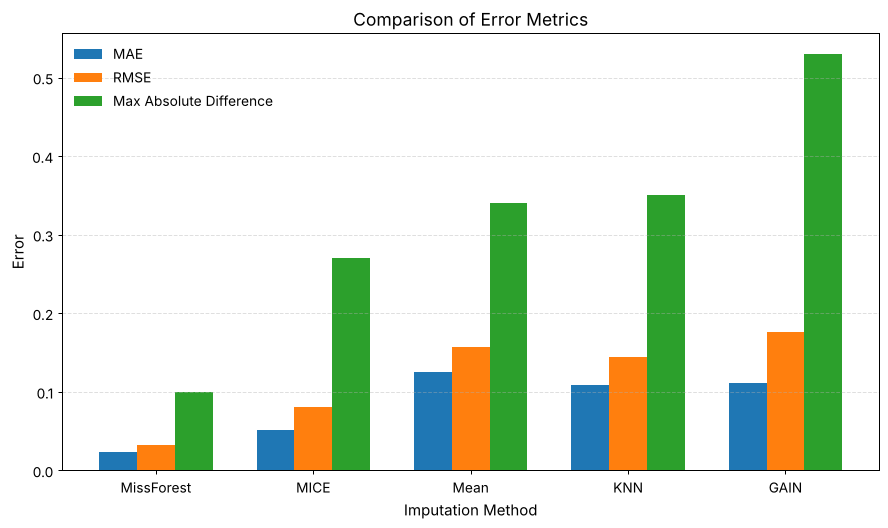

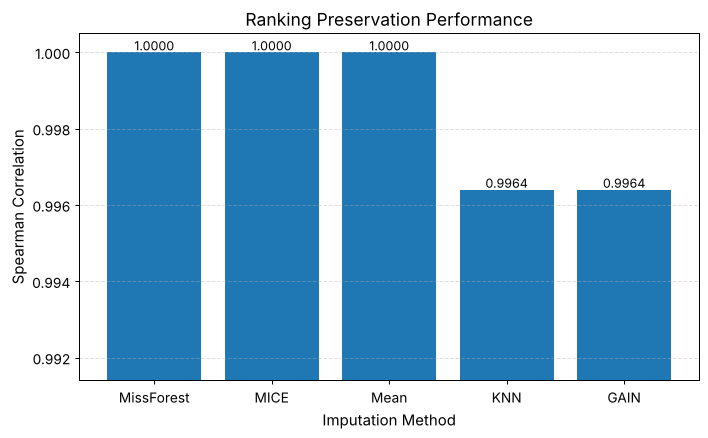

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# DATA (Already ordered by Overall Rank)
# ============================================================

# [REVISION - R1-6] values are taken from comparison_table (no hand-typed numbers)
df = comparison_table.rename(columns={
    "Imputation Method": "Method",
    "Spearman (ρ)": "Spearman"
})

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

# ============================================================
# FIGURE 1
# ============================================================

x = np.arange(len(df))
width = 0.24

plt.figure(figsize=(10,6))

plt.bar(x-width,
        df["MAE"],
        width,
        label="MAE")

plt.bar(x,
        df["RMSE"],
        width,
        label="RMSE")

plt.bar(x+width,
        df["Maximum Absolute Difference"],
        width,
        label="Max Absolute Difference")

plt.xticks(x, df["Method"])
plt.ylabel("Error")
plt.xlabel("Imputation Method")
plt.title("Comparison of Error Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

# ============================================================
# FIGURE 2
# ============================================================

plt.figure(figsize=(8,5))

bars = plt.bar(
    df["Method"],
    df["Spearman"]
)

plt.ylim(df["Spearman"].min() - 0.005, 1.0005)

plt.ylabel("Spearman Correlation")
plt.xlabel("Imputation Method")
plt.title("Ranking Preservation Performance")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, df["Spearman"]):
    plt.text(
        bar.get_x()+bar.get_width()/2,
        value+0.00005,
        f"{value:.4f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

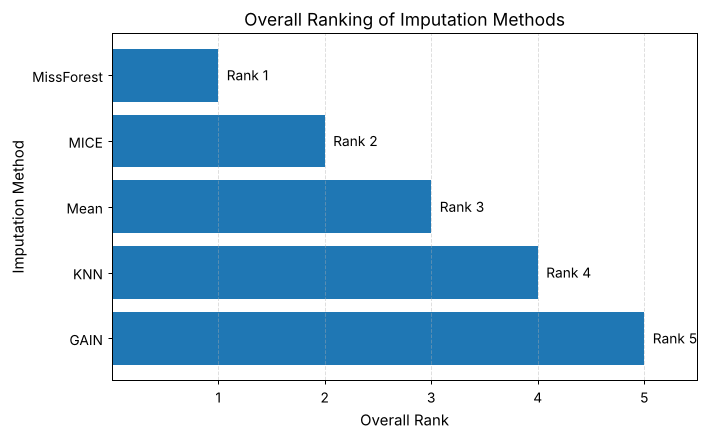

In [57]:
# ============================================================
# FIGURE 3
# Overall Ranking
# ============================================================

# [REVISION - R1-6] taken from comparison_table
ranking_df = comparison_table.rename(columns={"Imputation Method": "Method"})[["Method", "Overall Rank"]]

plt.figure(figsize=(8, 5))

bars = plt.barh(
    ranking_df["Method"],
    ranking_df["Overall Rank"]
)

plt.xlabel("Overall Rank")
plt.ylabel("Imputation Method")
plt.title("Overall Ranking of Imputation Methods")

plt.xticks([1, 2, 3, 4, 5])
plt.xlim(0, 5.5)
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)

for bar, rank in zip(bars, ranking_df["Overall Rank"]):
    plt.text(
        bar.get_width() + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"Rank {rank}",
        va="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

# REVISION ANALYSES (Major Revision)

All cells above are the original analysis (only the cells marked `[REVISION]` were changed, and their default
settings reproduce the first version). The cells below were added for the reviewers:

| Reviewer item | Cell |
|---|---|
| R2 – rationale of the dataset | R-1 |
| R1-7, R2 – hyper-parameters | R-2 |
| R1-8, R2 – Min-Max + Pearson | R-3 |
| R1-1, R1-2, R2 – missing rates 5/10/15/20/30 % and different seeds | R-4, R-5, R-6 |
| R1-6 – overall rank definition | R-6 |
| R1-10 – Mean imputation (high ρ, high error) | R-7 |
| R1-3, R2 – λ sensitivity | R-8 |
| R1-4 – negative correlations | R-9 |
| R1-8, R2 – Pearson vs Spearman | R-10 |
| R1-9 – Target = 10 | R-11 |
| R1-5 – CP, D, CT values | R-12 |
| R1-11 – tables as text / figures | R-13 |

## R-1. Dataset description (R2 – rationale of the dataset)

In [58]:
# ============================================================
# [REVISION - R2] Descriptive statistics of the five primary variables
# ============================================================

primary_cols = ["year", "mass_kg", "dry_mass_kg", "power_watts", "design_lifetime_years"]

dataset_description = payloads_clean[primary_cols].describe().T[
    ["count", "mean", "std", "min", "50%", "max"]
].round(2)

print("Table R1. Descriptive statistics of the primary variables (n = 9,426)")
display(dataset_description)

print("Table R2. Pearson correlations of the primary variables")
display(payloads_clean[primary_cols].corr().round(3))

Table R1. Descriptive statistics of the primary variables (n = 9,426)
Table R2. Pearson correlations of the primary variables


,count,mean,std,min,50%,max
year,9426.0,1990.43,19.66,1957.0,1991.00,2024.0
mass_kg,9426.0,652.54,1327.67,1.1,248.15,25000.0
dry_mass_kg,9426.0,439.45,904.14,0.7,165.80,17999.5
power_watts,9426.0,1100.19,1517.23,14.0,653.00,50000.0
design_lifetime_years,9426.0,9.51,6.88,1.0,8.00,30.0


,year,mass_kg,dry_mass_kg,power_watts,design_lifetime_years
year,1.000,0.007,0.007,-0.008,-0.002
mass_kg,0.007,1.000,0.993,-0.009,0.005
dry_mass_kg,0.007,0.993,1.000,-0.007,0.005
power_watts,-0.008,-0.009,-0.007,1.000,-0.001
design_lifetime_years,-0.002,0.005,0.005,-0.001,1.000


## R-2. Hyper-parameters of the imputation methods (R1-7, R2)

In [59]:
# ============================================================
# [REVISION - R1-7, R2] All settings used in the imputation functions above
# ============================================================

hyperparameter_table = pd.DataFrame({
    "Method": ["Mean", "KNN", "MICE", "MissForest", "GAIN"],
    "Implementation": [
        "sklearn SimpleImputer",
        "sklearn KNNImputer",
        "sklearn IterativeImputer",
        "sklearn IterativeImputer + RandomForestRegressor",
        "GAIN (Yoon et al., 2018), " + GAIN_BACKEND
    ],
    "Hyper-parameters": [
        "strategy = mean of the observed values",
        "n_neighbors = 5, weights = uniform, metric = nan_euclidean",
        "estimator = BayesianRidge, max_iter = 10, initial_strategy = mean, random_state = seed",
        "n_estimators = 50, max_depth = 10, max_iter = 5, initial_strategy = mean, random_state = seed",
        f"batch_size = {BATCH_SIZE}, epochs = {EPOCHS}, hint_rate = {HINT_RATE}, alpha = {ALPHA}, "
        f"Adam lr = {LEARNING_RATE}, hidden units = max(32, 2d) = 32, 2 hidden layers (ReLU), "
        "Sigmoid output, Min-Max scaling of observed values"
    ]
})

display(hyperparameter_table)

,Method,Implementation,Hyper-parameters
0,Mean,sklearn SimpleImputer,strategy = mean of the observed values
1,KNN,sklearn KNNImputer,"n_neighbors = 5, weights = uniform, metric = nan_euclidean"
2,MICE,sklearn IterativeImputer,"estimator = BayesianRidge, max_iter = 10, initial_strategy = mean, random_state = seed"
3,MissForest,sklearn IterativeImputer + RandomForestRegressor,"n_estimators = 50, max_depth = 10, max_iter = 5, initial_strategy = mean, random_state = seed"
4,GAIN,"GAIN (Yoon et al., 2018), numpy","batch_size = 128, epochs = 300, hint_rate = 0.9, alpha = 100.0, Adam lr = 0.001, hidden units = max(32, 2d) = 32, 2 hidden layers (ReLU), Sigmoid output, Min-Max scaling of observed values"


## R-3. Min-Max normalisation and Pearson correlation (R1-8)

In [60]:
# ============================================================
# [REVISION - R1-8] Pearson r is invariant to Min-Max scaling
# (Min-Max is a positive linear transformation x' = (x - a) / b).
# The check below shows that the roof is identical with and
# without normalisation.
# ============================================================

X_raw_tc = payloads_clean[tc_columns].copy()
X_raw_tc.columns = tc_codes

X_minmax_tc = pd.DataFrame(
    MinMaxScaler().fit_transform(X_raw_tc),
    columns=tc_codes,
    index=X_raw_tc.index
)

max_difference = (X_raw_tc.corr() - X_minmax_tc.corr()).abs().max().max()

print(f"Maximum |r(raw) - r(Min-Max)| over all TC pairs = {max_difference:.2e}")

Maximum |r(raw) - r(Min-Max)| over all TC pairs = 4.77e-15


## R-4. Helper functions for the revision experiments

In [61]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ============================================================
# [REVISION] qfd_from_roof:
# same calculations as run_adjusted_qfd (R* -> TIS -> IP -> PI -> PI% -> rank),
# but starting from an already computed roof matrix. It is used to repeat
# the QFD quickly for different lambda / negative-correlation / target settings
# without re-imputing the data.
# ============================================================

def qfd_from_roof(roof_matrix, lambda_value=0.50, negative_mode="positive", evaluation=None):

    if evaluation is None:
        evaluation = technical_evaluation

    R = relationship_matrix[tc_cols].astype(float).values
    Q = np.asarray(roof_matrix, dtype=float)

    if negative_mode == "positive":
        Qn = np.clip(Q, 0, None)
    elif negative_mode == "signed":
        Qn = Q
    elif negative_mode == "absolute":
        Qn = np.abs(Q)

    R_adj = np.clip(R @ (np.eye(len(tc_cols)) + lambda_value * Qn), 0, None)

    tis = np.array(cr_importance_scores) @ R_adj

    ip = np.round(tis / tis.sum() * 100, 2)

    pi = (
        (evaluation["Target"].values - evaluation["Current Performance"].values) * ip
        / (evaluation["Difficulty"].values + evaluation["Cost and Time"].values)
    )

    pi_percent = np.round(pi / pi.sum() * 100, 2)

    pi_rank = pd.Series(pi_percent).rank(ascending=False, method="dense").astype(int).to_numpy()

    return {"priority_to_improve_percent": pi_percent,
            "priority_to_improve_rank": pi_rank}


# ============================================================
# Comparison with the original dataset (same metrics as Table 10)
# ============================================================

def compare_to_original(result_ref, result_imp):

    rho, p_value = spearmanr(
        result_ref["priority_to_improve_rank"],
        result_imp["priority_to_improve_rank"]
    )

    error = (
        result_imp["priority_to_improve_percent"]
        - result_ref["priority_to_improve_percent"]
    )

    return {
        "Spearman": rho,
        "p-value": p_value,
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Maximum Absolute Difference": np.max(np.abs(error))
    }


# ============================================================
# Composite Score (Table 10 rule, see cell above) computed separately
# inside every replication (seed)
# ============================================================

def add_composite_score(rows):
    parts = []
    for seed, g in rows.groupby("Seed"):
        g = g.copy()
        g["Composite Score"] = composite_score(g)
        parts.append(g)
    return pd.concat(parts)


# ------------------------------------------------------------
# Check: qfd_from_roof gives exactly the same result as run_adjusted_qfd
# ------------------------------------------------------------

check = qfd_from_roof(result_original["roof_matrix"].values)

print("Same PI (%) as run_adjusted_qfd :",
      np.allclose(check["priority_to_improve_percent"], result_original["priority_to_improve_percent"]))
print("Same PI rank as run_adjusted_qfd:",
      np.array_equal(check["priority_to_improve_rank"], result_original["priority_to_improve_rank"]))

Same PI (%) as run_adjusted_qfd : True
Same PI rank as run_adjusted_qfd: True


## R-5. Repeated experiment: 5 missing rates × 10 random seeds (R1-1, R1-2, R2)

For every missing rate (5, 10, 15, 20, 30 %) and every seed (1–10) one MCAR dataset is created with
`create_mcar_dataset`; the **same** incomplete dataset is imputed by all five methods and the full QFD
(`run_adjusted_qfd`) is recalculated. Results are saved to `revision_results.pkl`, so the loop runs only once.
(Runtime ≈ 1–2 hours, mostly MissForest and GAIN.)

In [62]:
import os
import time
import pickle

# ============================================================
# [REVISION - R1-1, R1-2, R2] EXPERIMENT SETTINGS
# ============================================================

MISSING_RATES = [0.05, 0.10, 0.15, 0.20, 0.30]
SEEDS = list(range(1, 11))          # 10 independent MCAR replications

imputation_functions = {
    "Mean": impute_mean,
    "KNN": impute_knn,
    "MICE": impute_mice,
    "MissForest": impute_missforest,
    "GAIN": impute_gain
}

RESULT_FILE = "revision_results.pkl"

# ============================================================
# RUN (or load if already computed)
# ============================================================

if os.path.exists(RESULT_FILE):

    with open(RESULT_FILE, "rb") as f:
        saved = pickle.load(f)

    experiment_results = saved["experiment_results"]
    roof_store = saved["roof_store"]

    print("Loaded saved results:", len(experiment_results), "runs")

else:

    experiment_results = []
    roof_store = []          # roof matrices (Pearson and Spearman) of every run
    start = time.time()

    for rate in MISSING_RATES:
        for seed in SEEDS:

            data_missing = create_mcar_dataset(payloads_clean, rate, seed, verbose=False)
            missing_cells = data_missing[tc_columns].isna()

            for method_name, impute_function in imputation_functions.items():

                imputed = impute_function(data_missing, random_state=seed, verbose=False)

                result = run_adjusted_qfd(imputed, show=False)

                metrics = compare_to_original(result_original, result)

                # imputation accuracy on the deleted cells (normalised RMSE)
                nrmse = np.mean([
                    np.sqrt(np.mean(
                        (imputed.loc[missing_cells[c], c] - payloads_clean.loc[missing_cells[c], c]) ** 2
                    )) / payloads_clean[c].std()
                    for c in tc_columns
                ])

                # Spearman-based roof of the same imputed dataset (for R-10)
                roof_spearman = imputed[tc_columns].corr(method="spearman").values.copy()
                np.fill_diagonal(roof_spearman, 0)

                experiment_results.append({
                    "Missing Rate": rate,
                    "Seed": seed,
                    "Imputation Method": method_name,
                    "Imputation NRMSE": nrmse,
                    **metrics
                })

                roof_store.append({
                    "Missing Rate": rate,
                    "Seed": seed,
                    "Imputation Method": method_name,
                    "roof_pearson": result["roof_matrix"].values.copy(),
                    "roof_spearman": roof_spearman
                })

            print(f"rate = {rate:.2f} | seed = {seed:2d} | elapsed = {(time.time() - start) / 60:5.1f} min")

    with open(RESULT_FILE, "wb") as f:
        pickle.dump({"experiment_results": experiment_results, "roof_store": roof_store}, f)

experiment_results = pd.DataFrame(experiment_results)
experiment_results.to_csv("revision_all_runs.csv", index=False)

display(experiment_results.head())

rate = 0.05 | seed =  1 | elapsed =   1.3 min
rate = 0.05 | seed =  2 | elapsed =   2.7 min
rate = 0.05 | seed =  3 | elapsed =   4.0 min
rate = 0.05 | seed =  4 | elapsed =   5.4 min
rate = 0.05 | seed =  5 | elapsed =   6.7 min
rate = 0.05 | seed =  6 | elapsed =   8.1 min
rate = 0.05 | seed =  7 | elapsed =   9.4 min
rate = 0.05 | seed =  8 | elapsed =  10.8 min
rate = 0.05 | seed =  9 | elapsed =  12.1 min
rate = 0.05 | seed = 10 | elapsed =  13.4 min
rate = 0.10 | seed =  1 | elapsed =  14.7 min
rate = 0.10 | seed =  2 | elapsed =  16.1 min
rate = 0.10 | seed =  3 | elapsed =  17.4 min
rate = 0.10 | seed =  4 | elapsed =  18.6 min
rate = 0.10 | seed =  5 | elapsed =  19.9 min
rate = 0.10 | seed =  6 | elapsed =  21.2 min
rate = 0.10 | seed =  7 | elapsed =  22.5 min
rate = 0.10 | seed =  8 | elapsed =  23.8 min
rate = 0.10 | seed =  9 | elapsed =  25.1 min
rate = 0.10 | seed = 10 | elapsed =  26.4 min
rate = 0.15 | seed =  1 | elapsed =  27.7 min
rate = 0.15 | seed =  2 | elapsed 

,Missing Rate,Seed,Imputation Method,Imputation NRMSE,Spearman,p-value,MAE,RMSE,Maximum Absolute Difference
0,0.05,1,Mean,0.940329,0.996429,2.415979e-15,0.057333,0.066433,0.12
1,0.05,1,KNN,0.868975,0.996429,2.415979e-15,0.048667,0.061482,0.16
2,0.05,1,MICE,0.325780,1.000000,0.000000e+00,0.019333,0.025430,0.06
3,0.05,1,MissForest,0.137402,1.000000,0.000000e+00,0.006667,0.010954,0.03
4,0.05,1,GAIN,0.552173,0.992857,2.168121e-13,0.023333,0.028166,0.05


## R-6. Results for all missing rates (mean ± standard deviation over 10 seeds) and Overall Rank (R1-1, R1-2, R1-6)

Table R3. QFD agreement with the original dataset (mean ± sd over 10 seeds)
Table R4. Mean Composite Score (lower = better)
Table R5. Overall Rank for each missing rate
Overall Rank over all missing rates:
Table R6. Friedman test


Spearman              MAE             RMSE Maximum Absolute Difference Imputation NRMSE
Missing Rate Imputation Method                                                                                                
0.05         Mean               0.9979 ± 0.0030  0.0573 ± 0.0172  0.0754 ± 0.0243             0.1830 ± 0.0903  0.9749 ± 0.0660
             KNN                0.9981 ± 0.0030  0.0553 ± 0.0148  0.0702 ± 0.0174             0.1610 ± 0.0530  0.8863 ± 0.0610
             MICE               0.9996 ± 0.0011  0.0297 ± 0.0094  0.0419 ± 0.0149             0.1150 ± 0.0495  0.3622 ± 0.0350
             MissForest         0.9996 ± 0.0011  0.0157 ± 0.0111  0.0252 ± 0.0175             0.0740 ± 0.0568  0.1590 ± 0.0340
             GAIN               0.9977 ± 0.0029  0.0307 ± 0.0097  0.0407 ± 0.0131             0.0960 ± 0.0455  0.6298 ± 0.0594
0.10         Mean               0.9987 ± 0.0018  0.1085 ± 0.0283  0.1421 ± 0.0380             0.3470 ± 0.1435  1.0130 ± 0.0393
             KNN                0.9982 ± 0.0025  0.1043 ± 0.0144  0.1351 ± 0.0206             0.3310 ± 0.1008  0.9292 ± 0.0425
             MICE               0.9992 ± 0.0015  0.0603 ± 0.0178  0.0843 ± 0.0318             0.2290 ± 0.1319  0.4424 ± 0.0378
             MissForest         0.9996 ± 0.0011  0.0310 ± 0.0129  0.0505 ± 0.0212             0.1550 ± 0.0750  0.2240 ± 0.0299
             GAIN               0.9968 ± 0.0039  0.0924 ± 0.0359  0.1350 ± 0.0566             0.3560 ± 0.1833  0.7696 ± 0.0913
0.15         Mean               0.9974 ± 0.0018  0.1483 ± 0.0350  0.1884 ± 0.0473             0.4370 ± 0.1773  0.9981 ± 0.0283
             KNN                0.9980 ± 0.0021  0.1355 ± 0.0249  0.1685 ± 0.0351             0.3790 ± 0.1150  0.9194 ± 0.0328
             MICE               0.9986 ± 0.0025  0.0843 ± 0.0152  0.1174 ± 0.0313             0.3370 ± 0.1477  0.4814 ± 0.0284
             MissForest         0.9989 ± 0.0017  0.0471 ± 0.0245  0.0716 ± 0.0422             0.2150 ± 0.1504  0.2681 ± 0.0295
             GAIN               0.9939 ± 0.0053  0.1222 ± 0.0417  0.1738 ± 0.0673             0.4450 ± 0.2168  0.8030 ± 0.1039
0.20         Mean               0.9950 ± 0.0035  0.2023 ± 0.0513  0.2582 ± 0.0653             0.6110 ± 0.2131  1.0060 ± 0.0337
             KNN                0.9949 ± 0.0051  0.2001 ± 0.0392  0.2576 ± 0.0590             0.6270 ± 0.2269  0.9441 ± 0.0317
             MICE               0.9979 ± 0.0030  0.1109 ± 0.0231  0.1540 ± 0.0369             0.4450 ± 0.1517  0.5390 ± 0.0283
             MissForest         0.9987 ± 0.0016  0.0673 ± 0.0339  0.1018 ± 0.0574             0.2990 ± 0.2128  0.3308 ± 0.0349
             GAIN               0.9920 ± 0.0042  0.1709 ± 0.0497  0.2337 ± 0.0738             0.5920 ± 0.2092  0.8529 ± 0.0513
0.30         Mean               0.9932 ± 0.0059  0.2930 ± 0.0529  0.3622 ± 0.0585             0.7830 ± 0.1696  0.9914 ± 0.0326
             KNN                0.9900 ± 0.0044  0.3188 ± 0.0553  0.4003 ± 0.0716             0.8850 ± 0.2108  0.9915 ± 0.0320
             MICE               0.9956 ± 0.0038  0.1420 ± 0.0453  0.2004 ± 0.0718             0.5570 ± 0.2722  0.6493 ± 0.0435
             MissForest         0.9982 ± 0.0019  0.0819 ± 0.0305  0.1250 ± 0.0531             0.3670 ± 0.1955  0.4028 ± 0.0265
             GAIN               0.9674 ± 0.0262  0.3954 ± 0.1364  0.5505 ± 0.1886             1.4240 ± 0.5754  0.9018 ± 0.0715

Missing Rate,0.05,0.1,0.15,0.2,0.3
Imputation Method,,,,,
Mean,4.125,3.850,3.975,4.075,3.088
KNN,4.062,3.750,3.412,3.788,3.912
MICE,2.425,2.225,2.400,2.175,2.112
MissForest,1.525,1.488,1.488,1.338,1.238
GAIN,2.862,3.688,3.725,3.625,4.650


Missing Rate,0.05,0.1,0.15,0.2,0.3
Imputation Method,,,,,
Mean,5,5,5,5,3
KNN,4,4,3,4,4
MICE,2,2,2,2,2
MissForest,1,1,1,1,1
GAIN,3,3,4,3,5


,Overall Rank (all rates)
Imputation Method,
MissForest,1
MICE,2
GAIN,3
KNN,4
Mean,5


,Missing Rate,Friedman Chi-square (MAE),p-value
0,0.05,35.36,0.0
1,0.10,31.04,0.0
2,0.15,30.56,0.0
3,0.20,32.00,0.0
4,0.30,34.24,0.0


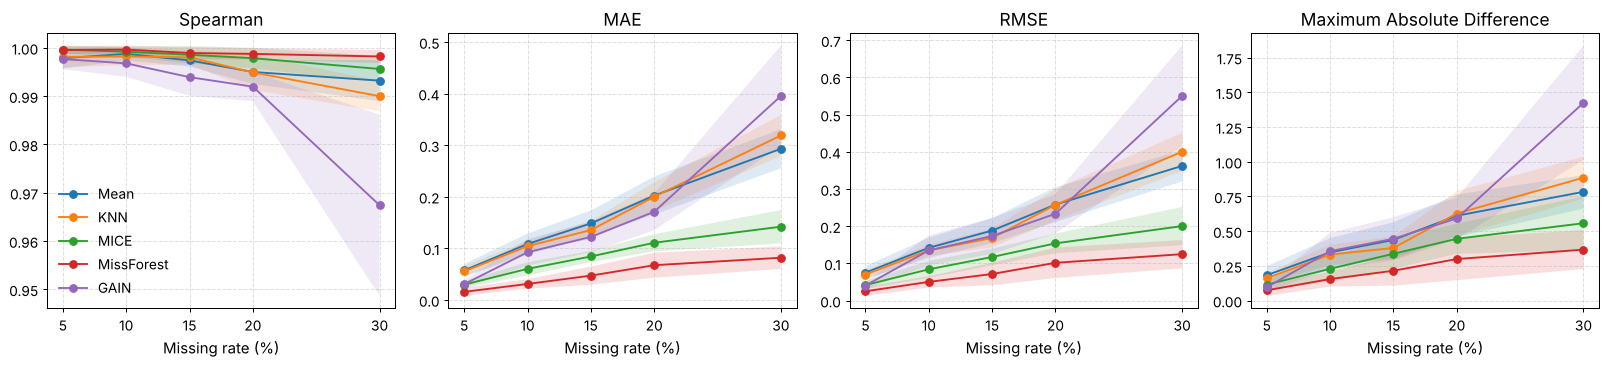

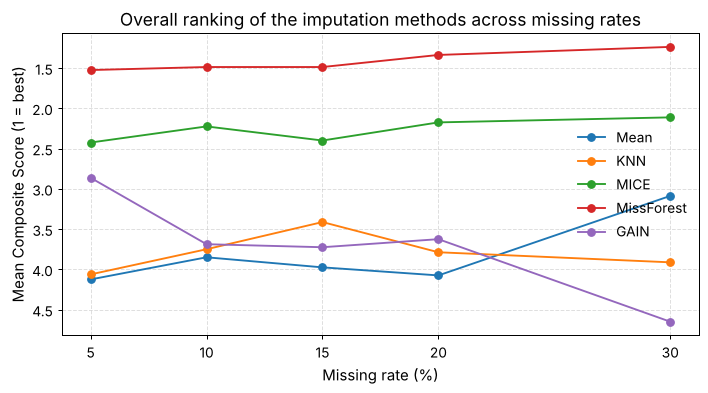

In [63]:
import matplotlib.pyplot as plt
from scipy import stats

methods_order = ["Mean", "KNN", "MICE", "MissForest", "GAIN"]
metric_cols = ["Spearman", "MAE", "RMSE", "Maximum Absolute Difference", "Imputation NRMSE"]

# ============================================================
# TABLE: mean ± sd for every missing rate and method
# ============================================================

grouped = experiment_results.groupby(["Missing Rate", "Imputation Method"])[metric_cols]
mean_table = grouped.mean()
std_table = grouped.std()

summary_table = mean_table.map("{:.4f}".format) + " ± " + std_table.fillna(0).map("{:.4f}".format)

summary_table = summary_table.reindex(
    pd.MultiIndex.from_product([MISSING_RATES, methods_order], names=["Missing Rate", "Imputation Method"])
)

print("Table R3. QFD agreement with the original dataset (mean ± sd over 10 seeds)")
display(summary_table)

# ============================================================
# [REVISION - R1-6] OVERALL RANK FOR EVERY MISSING RATE
# Same rule as Table 10: in each replication the methods are ranked on
# Spearman (desc), MAE, RMSE, Max Abs. Difference (asc); Composite Score =
# mean of the 4 ranks. The Composite Scores are averaged over the 10 seeds
# and the Overall Rank is the rank of this average (1 = best).
# ============================================================

composite_rows = []

for (rate, seed), g in experiment_results.groupby(["Missing Rate", "Seed"]):
    g = g.rename(columns={"Spearman": "Spearman (ρ)"}).reset_index(drop=True)
    g["Composite Score"] = composite_score(g)
    composite_rows.append(g[["Missing Rate", "Seed", "Imputation Method", "Composite Score"]])

composite_results = pd.concat(composite_rows)

overall_rank_by_rate = (
    composite_results.groupby(["Missing Rate", "Imputation Method"])["Composite Score"].mean()
    .unstack("Missing Rate")
    .loc[methods_order]
)

overall_rank_table = overall_rank_by_rate.rank(method="min").astype(int)

print("Table R4. Mean Composite Score (lower = better)")
display(overall_rank_by_rate.round(3))

print("Table R5. Overall Rank for each missing rate")
display(overall_rank_table)

pooled_rank = composite_results.groupby("Imputation Method")["Composite Score"].mean().loc[methods_order]
print("Overall Rank over all missing rates:")
display(pooled_rank.rank(method="min").astype(int).sort_values().to_frame("Overall Rank (all rates)"))

# ============================================================
# Friedman test: are the methods significantly different? (MAE, blocks = seeds)
# ============================================================

friedman_rows = []

for rate in MISSING_RATES:
    mae = experiment_results[experiment_results["Missing Rate"] == rate].pivot(
        index="Seed", columns="Imputation Method", values="MAE")[methods_order]
    chi2, p = stats.friedmanchisquare(*[mae[m] for m in methods_order])
    friedman_rows.append([rate, chi2, p])

friedman_table = pd.DataFrame(friedman_rows, columns=["Missing Rate", "Friedman Chi-square (MAE)", "p-value"])

print("Table R6. Friedman test")
display(friedman_table.round(5))

# ============================================================
# FIGURE: error metrics vs missing rate (mean and 95 % CI)
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for ax, metric in zip(axes, ["Spearman", "MAE", "RMSE", "Maximum Absolute Difference"]):
    for m in methods_order:
        d = experiment_results[experiment_results["Imputation Method"] == m].groupby("Missing Rate")[metric]
        mu, sd, n = d.mean(), d.std(), d.count()
        ci = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
        x = np.array(mu.index) * 100
        ax.plot(x, mu.values, "o-", label=m)
        ax.fill_between(x, mu - ci, mu + ci, alpha=0.15)
    ax.set_title(metric)
    ax.set_xlabel("Missing rate (%)")
    ax.set_xticks([5, 10, 15, 20, 30])
    ax.grid(linestyle="--", alpha=0.4)

axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig_R_metrics_vs_missing_rate.png", dpi=400, bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE: Overall rank vs missing rate
# ============================================================

plt.figure(figsize=(8, 4.5))
for m in methods_order:
    plt.plot(np.array(MISSING_RATES) * 100, overall_rank_by_rate.loc[m].values, "o-", label=m)
plt.gca().invert_yaxis()
plt.xlabel("Missing rate (%)")
plt.ylabel("Mean Composite Score (1 = best)")
plt.xticks([5, 10, 15, 20, 30])
plt.title("Overall ranking of the imputation methods across missing rates")
plt.grid(linestyle="--", alpha=0.4)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig_R_overall_rank_vs_missing_rate.png", dpi=400, bbox_inches="tight")
plt.show()

## R-7. Interpretation of Mean imputation (R1-10)

Mean imputation fills every missing cell with the column mean. Because the filled values do not co-vary with the
other variables, the correlations between technical characteristics are pulled towards zero (attenuation).
The roof only enters the HoQ through λ·Qn, i.e. it *modulates* the fixed relationship scores R; a nearly uniform
shrinkage of the roof changes the **size** of the PI values (larger MAE/RMSE) but rarely changes their **order**
(high Spearman). The ratio Σ|Q_imputed| / Σ|Q_original| below measures this shrinkage.

Table R7. Attenuation ratio of the roof (mean over seeds)
Table R8. Mean absolute roof error


Imputation Method,Mean,KNN,MICE,MissForest,GAIN
Missing Rate,,,,,
0.05,0.953,0.966,1.011,1.002,0.990
0.10,0.904,0.935,1.022,1.006,0.975
0.15,0.860,0.912,1.032,1.009,0.954
0.20,0.809,0.886,1.045,1.011,0.944
0.30,0.714,0.786,1.048,1.013,0.934


Imputation Method,Mean,KNN,MICE,MissForest,GAIN
Missing Rate,,,,,
0.05,0.0081,0.0070,0.0022,0.0009,0.0039
0.10,0.0157,0.0135,0.0043,0.0021,0.0098
0.15,0.0218,0.0184,0.0061,0.0030,0.0138
0.20,0.0289,0.0254,0.0087,0.0044,0.0192
0.30,0.0421,0.0398,0.0138,0.0066,0.0320


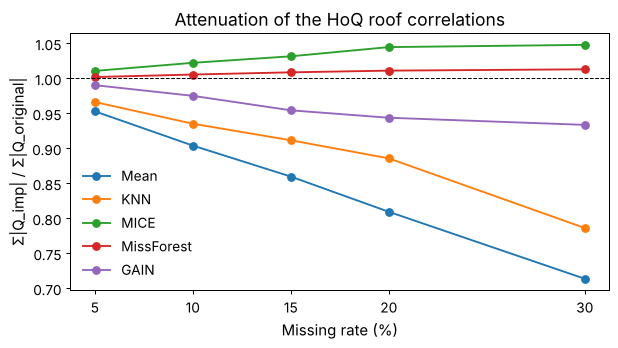

In [64]:
# ============================================================
# [REVISION - R1-10] Attenuation of the roof: sum|Q_imp| / sum|Q_original|
# (1 = same strength as the original roof, < 1 = correlations shrunk)
# ============================================================

Q_original = result_original["roof_matrix"].values
off_diagonal = ~np.eye(len(tc_cols), dtype=bool)

attenuation_rows = []
for r in roof_store:
    Q = r["roof_pearson"]
    attenuation_rows.append({
        "Missing Rate": r["Missing Rate"],
        "Imputation Method": r["Imputation Method"],
        "Attenuation Ratio": np.abs(Q[off_diagonal]).sum() / np.abs(Q_original[off_diagonal]).sum(),
        "Mean |Q_imp - Q_original|": np.abs(Q - Q_original)[off_diagonal].mean()
    })

attenuation_table = (
    pd.DataFrame(attenuation_rows)
    .groupby(["Missing Rate", "Imputation Method"]).mean()
    .unstack("Imputation Method")
)

print("Table R7. Attenuation ratio of the roof (mean over seeds)")
display(attenuation_table["Attenuation Ratio"][methods_order].round(3))

print("Table R8. Mean absolute roof error")
display(attenuation_table["Mean |Q_imp - Q_original|"][methods_order].round(4))

plt.figure(figsize=(7, 4))
for m in methods_order:
    plt.plot(np.array(MISSING_RATES) * 100, attenuation_table["Attenuation Ratio"][m].values, "o-", label=m)
plt.axhline(1, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Missing rate (%)")
plt.ylabel("Σ|Q_imp| / Σ|Q_original|")
plt.xticks([5, 10, 15, 20, 30])
plt.title("Attenuation of the HoQ roof correlations")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig_R_roof_attenuation.png", dpi=400, bbox_inches="tight")
plt.show()

## R-8. Sensitivity to λ (R1-3, R2)

Table R9. Priority to Improve Rank of the original dataset for different λ
Table R10. Agreement with the λ = 0.50 ranking
Table R11. Overall Rank of the imputation methods for different λ (15 % MCAR)
(for λ = 0 the roof is not used, so all methods give the original result and tie)


,λ = 0.0,λ = 0.1,λ = 0.25,λ = 0.5,λ = 0.75,λ = 1.0,λ = 1.5,λ = 2.0
TC1,13,13,14,14,14,14,13,12
TC2,9,10,11,11,11,11,11,11
TC3,7,7,8,10,10,10,10,10
TC4,10,8,6,7,7,6,6,6
TC5,12,11,9,8,8,8,8,8
TC6,6,9,13,13,13,12,12,13
TC7,8,5,5,4,3,3,3,3
TC8,4,6,12,12,12,13,14,14
TC9,15,14,15,15,15,15,15,15
TC10,5,4,2,2,2,2,2,2


,λ,Spearman vs λ = 0.50,Top-5 technical characteristics
0,0.00,0.5464,"TC15, TC13, TC12, TC8, TC10"
1,0.10,0.7435,"TC15, TC13, TC12, TC10, TC7"
2,0.25,0.9821,"TC15, TC10, TC12, TC13, TC7"
3,0.50,1.0000,"TC15, TC10, TC12, TC7, TC13"
4,0.75,0.9929,"TC15, TC10, TC7, TC12, TC11"
5,1.00,0.9821,"TC15, TC10, TC7, TC12, TC11"
6,1.50,0.9750,"TC15, TC10, TC7, TC12, TC11"
7,2.00,0.9607,"TC15, TC10, TC7, TC11, TC12"


λ,0.0,0.1,0.25,0.5,0.75,1.0,1.5,2.0
Imputation Method,,,,,,,,
Mean,1,5,5,5,4,5,4,4
KNN,1,4,4,3,3,3,3,3
MICE,1,2,2,2,2,2,2,2
MissForest,1,1,1,1,1,1,1,1
GAIN,1,3,3,4,5,4,5,5


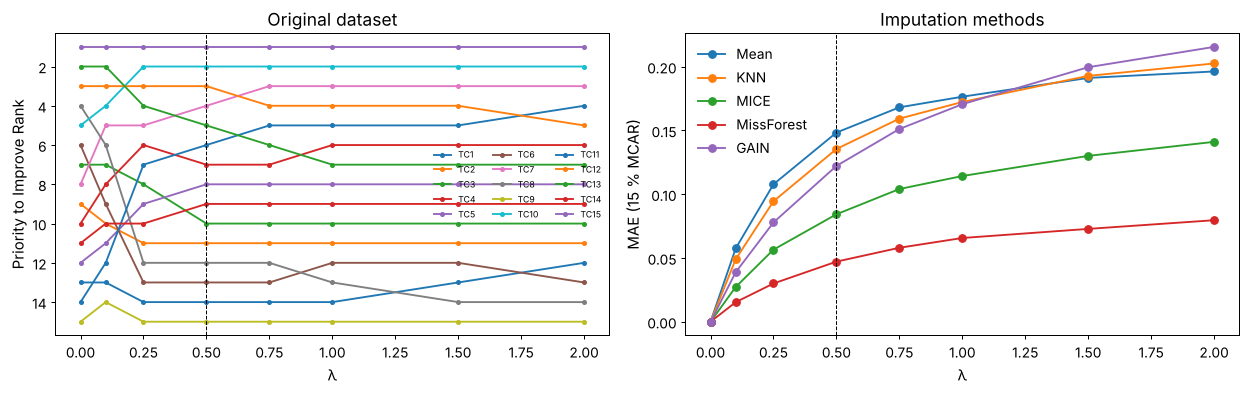

In [65]:
# ============================================================
# [REVISION - R1-3, R2] lambda sensitivity
# (a) priority ranking of the ORIGINAL dataset for different lambda values
# (b) ranking of the imputation methods (15 % MCAR, 10 seeds) for each lambda
# ============================================================

lambda_values = [0.00, 0.10, 0.25, 0.50, 0.75, 1.00, 1.50, 2.00]

baseline = qfd_from_roof(Q_original, lambda_value=0.50)

lambda_rank_table = pd.DataFrame(index=tc_cols)
lambda_summary = []

for lam in lambda_values:
    res_lam = qfd_from_roof(Q_original, lambda_value=lam)
    lambda_rank_table[f"λ = {lam}"] = res_lam["priority_to_improve_rank"]
    rho, _ = spearmanr(baseline["priority_to_improve_rank"], res_lam["priority_to_improve_rank"])
    top5 = [tc_cols[i] for i in np.argsort(-res_lam["priority_to_improve_percent"])[:5]]
    lambda_summary.append([lam, rho, ", ".join(top5)])

lambda_summary = pd.DataFrame(lambda_summary, columns=["λ", "Spearman vs λ = 0.50", "Top-5 technical characteristics"])

print("Table R9. Priority to Improve Rank of the original dataset for different λ")
display(lambda_rank_table)

print("Table R10. Agreement with the λ = 0.50 ranking")
display(lambda_summary.round(4))

# (b) method comparison for every lambda at 15 % missing data
lambda_method_rows = []

for lam in lambda_values:
    ref_lam = qfd_from_roof(Q_original, lambda_value=lam)
    rows = []
    for r in roof_store:
        if r["Missing Rate"] != 0.15:
            continue
        rows.append({"Seed": r["Seed"], "Imputation Method": r["Imputation Method"],
                     **compare_to_original(ref_lam, qfd_from_roof(r["roof_pearson"], lambda_value=lam))})
    rows = pd.DataFrame(rows).rename(columns={"Spearman": "Spearman (ρ)"})
    rows = add_composite_score(rows)
    score = rows.groupby("Imputation Method")["Composite Score"].mean()
    mae = rows.groupby("Imputation Method")["MAE"].mean()
    for m in methods_order:
        lambda_method_rows.append([lam, m, mae[m], score[m]])

lambda_method_table = pd.DataFrame(lambda_method_rows, columns=["λ", "Imputation Method", "MAE", "Composite Score"])
lambda_method_table["Overall Rank"] = lambda_method_table.groupby("λ")["Composite Score"].rank(method="min").astype(int)

print("Table R11. Overall Rank of the imputation methods for different λ (15 % MCAR)")
print("(for λ = 0 the roof is not used, so all methods give the original result and tie)")
display(lambda_method_table.pivot(index="Imputation Method", columns="λ", values="Overall Rank").loc[methods_order])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for tc in tc_cols:
    axes[0].plot(lambda_values, lambda_rank_table.loc[tc].values, "o-", markersize=3, label=tc)
axes[0].invert_yaxis()
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("λ"); axes[0].set_ylabel("Priority to Improve Rank")
axes[0].set_title("Original dataset")
axes[0].legend(ncol=3, fontsize=7, frameon=False)
for m in methods_order:
    d = lambda_method_table[lambda_method_table["Imputation Method"] == m]
    axes[1].plot(d["λ"], d["MAE"], "o-", label=m)
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("λ"); axes[1].set_ylabel("MAE (15 % MCAR)")
axes[1].set_title("Imputation methods")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig_R_lambda_sensitivity.png", dpi=400, bbox_inches="tight")
plt.show()

## R-9. Treatment of negative technical correlations (R1-4)

Three options are compared: **positive** (first version, Qn = max(0, Q)), **signed** (Qn = Q, negative correlations
reduce the relationship scores; negative R* values are set to 0) and **absolute** (Qn = |Q|).

In [66]:
# ============================================================
# [REVISION - R1-4] negative correlations
# ============================================================

upper = Q_original[np.triu_indices(len(tc_cols), 1)]
print(f"TC pairs: {len(upper)} | negative: {(upper < 0).sum()} | r < -0.30: {(upper < -0.30).sum()} | min r = {upper.min():.3f}")

strong_negative = pd.DataFrame(
    [(tc_cols[i], tc_cols[j], Q_original[i, j])
     for i in range(len(tc_cols)) for j in range(i + 1, len(tc_cols)) if Q_original[i, j] < -0.30],
    columns=["TC j", "TC k", "r"]
)
print("Strong negative correlations:")
display(strong_negative.round(3))

R_base = relationship_matrix[tc_cols].astype(float).values
negative_rows = []
negative_method_rows = []

for mode in ["positive", "signed", "absolute"]:

    res_mode = qfd_from_roof(Q_original, negative_mode=mode)
    rho, _ = spearmanr(baseline["priority_to_improve_rank"], res_mode["priority_to_improve_rank"])
    Qn_mode = {"positive": np.clip(Q_original, 0, None), "signed": Q_original, "absolute": np.abs(Q_original)}[mode]
    negative_cells = int((R_base @ (np.eye(len(tc_cols)) + 0.5 * Qn_mode) < 0).sum())
    top5 = [tc_cols[i] for i in np.argsort(-res_mode["priority_to_improve_percent"])[:5]]
    negative_rows.append([mode, negative_cells, rho, ", ".join(top5), *res_mode["priority_to_improve_rank"]])

    rows = []
    for r in roof_store:
        if r["Missing Rate"] != 0.15:
            continue
        rows.append({"Seed": r["Seed"], "Imputation Method": r["Imputation Method"],
                     **compare_to_original(res_mode, qfd_from_roof(r["roof_pearson"], negative_mode=mode))})
    rows = pd.DataFrame(rows).rename(columns={"Spearman": "Spearman (ρ)"})
    rows = add_composite_score(rows)
    score = rows.groupby("Imputation Method")["Composite Score"].mean()
    mae = rows.groupby("Imputation Method")["MAE"].mean()
    for m in methods_order:
        negative_method_rows.append([mode, m, mae[m], score[m]])

negative_table = pd.DataFrame(
    negative_rows,
    columns=["Roof treatment", "Negative R* cells (set to 0)", "Spearman vs positive", "Top-5 technical characteristics", *tc_cols]
)
negative_method_table = pd.DataFrame(negative_method_rows, columns=["Roof treatment", "Imputation Method", "MAE", "Composite Score"])
negative_method_table["Overall Rank"] = negative_method_table.groupby("Roof treatment")["Composite Score"].rank(method="min").astype(int)

print("Table R12. Priority to Improve Rank of the original dataset under the three roof treatments")
display(negative_table.round(4))

print("Table R13. Overall Rank of the imputation methods (15 % MCAR)")
display(negative_method_table.pivot(index="Imputation Method", columns="Roof treatment", values="Overall Rank").loc[methods_order])

TC pairs: 105 | negative: 45 | r < -0.30: 2 | min r = -1.000
Strong negative correlations:
Table R12. Priority to Improve Rank of the original dataset under the three roof treatments
Table R13. Overall Rank of the imputation methods (15 % MCAR)


,TC j,TC k,r
0,TC1,TC9,-1.0
1,TC6,TC8,-1.0


,Roof treatment,Negative R* cells (set to 0),Spearman vs positive,Top-5 technical characteristics,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,positive,0,1.0000,"TC15, TC10, TC12, TC7, TC13",14,11,10,7,8,13,4,12,15,2,6,3,5,9,1
1,signed,27,0.9786,"TC15, TC10, TC12, TC7, TC11",13,11,10,6,8,12,4,14,15,2,5,3,7,9,1
2,absolute,0,0.8847,"TC15, TC10, TC7, TC13, TC12",13,9,8,7,10,12,3,5,14,2,6,4,3,11,1


Roof treatment,absolute,positive,signed
Imputation Method,,,
Mean,3,5,5
KNN,4,3,3
MICE,2,2,2
MissForest,1,1,1
GAIN,5,4,4


## R-10. Pearson vs Spearman roof (R1-8, R2)

In [67]:
# ============================================================
# [REVISION - R1-8, R2] The full QFD is repeated with a Spearman roof
# ============================================================

result_original_spearman = run_adjusted_qfd(payloads_clean, show=False, corr_method="spearman")

rho, _ = spearmanr(result_original["priority_to_improve_rank"], result_original_spearman["priority_to_improve_rank"])
print(f"Spearman between the Pearson-roof and Spearman-roof rankings (original data): {rho:.4f}")
print(f"Max |r_Pearson - r_Spearman| in the roof: {(result_original['roof_matrix'] - result_original_spearman['roof_matrix']).abs().max().max():.3f}")

display(pd.DataFrame({
    "Pearson roof rank": result_original["priority_to_improve_rank"],
    "Spearman roof rank": result_original_spearman["priority_to_improve_rank"]
}, index=tc_cols).T)

corr_method_rows = []
for kind, Q_ref_kind, key in [("Pearson", Q_original, "roof_pearson"),
                              ("Spearman", result_original_spearman["roof_matrix"].values, "roof_spearman")]:
    ref_kind = qfd_from_roof(Q_ref_kind)
    rows = []
    for r in roof_store:
        if r["Missing Rate"] != 0.15:
            continue
        rows.append({"Seed": r["Seed"], "Imputation Method": r["Imputation Method"],
                     **compare_to_original(ref_kind, qfd_from_roof(r[key]))})
    rows = pd.DataFrame(rows).rename(columns={"Spearman": "Spearman (ρ)"})
    rows = add_composite_score(rows)
    agg = rows.groupby("Imputation Method")[["Spearman (ρ)", "MAE", "RMSE", "Composite Score"]].mean()
    for m in methods_order:
        corr_method_rows.append([kind, m, *agg.loc[m].values])

corr_method_table = pd.DataFrame(corr_method_rows, columns=["Roof", "Imputation Method", "Spearman (ρ)", "MAE", "RMSE", "Composite Score"])
corr_method_table["Overall Rank"] = corr_method_table.groupby("Roof")["Composite Score"].rank(method="min").astype(int)

print("Table R14. Imputation methods with Pearson and Spearman roofs (15 % MCAR, mean of 10 seeds)")
display(corr_method_table.round(4))

Spearman between the Pearson-roof and Spearman-roof rankings (original data): 0.9893
Max |r_Pearson - r_Spearman| in the roof: 0.727
Table R14. Imputation methods with Pearson and Spearman roofs (15 % MCAR, mean of 10 seeds)


,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
Pearson roof rank,14,11,10,7,8,13,4,12,15,2,6,3,5,9,1
Spearman roof rank,14,11,10,7,9,12,4,13,15,2,5,3,6,8,1


,Roof,Imputation Method,Spearman (ρ),MAE,RMSE,Composite Score,Overall Rank
0,Pearson,Mean,0.9974,0.1483,0.1884,3.9750,5
1,Pearson,KNN,0.9980,0.1355,0.1685,3.4125,3
2,Pearson,MICE,0.9986,0.0843,0.1174,2.4000,2
3,Pearson,MissForest,0.9989,0.0471,0.0716,1.4875,1
4,Pearson,GAIN,0.9939,0.1222,0.1738,3.7250,4
5,Spearman,Mean,0.9935,0.2913,0.3527,4.5625,5
6,Spearman,KNN,0.9897,0.1696,0.2087,3.1500,3
7,Spearman,MICE,0.9949,0.1760,0.2104,2.9625,2
8,Spearman,MissForest,1.0000,0.0133,0.0169,1.0250,1
9,Spearman,GAIN,0.9936,0.1876,0.2371,3.3000,4


## R-11. Sensitivity to the Target value (R1-9)

CP is scored on a 1–10 scale where 10 = excellent, so T = 10 means that every technical characteristic is
benchmarked against the best achievable level and (T − CP) is its performance gap. Alternatives tested:
uniform T = 9 and T = 8 (all CP ≤ 7, so the gaps stay positive) and T = CP + 3 (equal gap for all TCs).

In [68]:
# ============================================================
# [REVISION - R1-9] Target sensitivity
# ============================================================

target_scenarios = {
    "T = 10 (first version)": np.full(len(tc_cols), 10),
    "T = 9": np.full(len(tc_cols), 9),
    "T = 8": np.full(len(tc_cols), 8),
    "T = CP + 3 (equal gap)": technical_evaluation["Current Performance"].values + 3
}

target_rows = []
target_method_rows = []

for name, target in target_scenarios.items():

    evaluation_t = technical_evaluation.copy()
    evaluation_t["Target"] = target

    res_t = qfd_from_roof(Q_original, evaluation=evaluation_t)
    rho, _ = spearmanr(baseline["priority_to_improve_rank"], res_t["priority_to_improve_rank"])
    top5 = [tc_cols[i] for i in np.argsort(-res_t["priority_to_improve_percent"])[:5]]
    target_rows.append([name, rho, ", ".join(top5), *res_t["priority_to_improve_rank"]])

    rows = []
    for r in roof_store:
        if r["Missing Rate"] != 0.15:
            continue
        rows.append({"Seed": r["Seed"], "Imputation Method": r["Imputation Method"],
                     **compare_to_original(res_t, qfd_from_roof(r["roof_pearson"], evaluation=evaluation_t))})
    rows = pd.DataFrame(rows).rename(columns={"Spearman": "Spearman (ρ)"})
    rows = add_composite_score(rows)
    score = rows.groupby("Imputation Method")["Composite Score"].mean()
    for m in methods_order:
        target_method_rows.append([name, m, score[m]])

target_table = pd.DataFrame(target_rows, columns=["Target scenario", "Spearman vs T = 10", "Top-5 technical characteristics", *tc_cols])
target_method_table = pd.DataFrame(target_method_rows, columns=["Target scenario", "Imputation Method", "Composite Score"])
target_method_table["Overall Rank"] = target_method_table.groupby("Target scenario")["Composite Score"].rank(method="min").astype(int)

print("Table R15. Priority to Improve Rank of the original dataset for different targets")
display(target_table.round(4))

print("Table R16. Overall Rank of the imputation methods for different targets (15 % MCAR)")
display(target_method_table.pivot(index="Imputation Method", columns="Target scenario", values="Overall Rank").loc[methods_order])

Table R15. Priority to Improve Rank of the original dataset for different targets
Table R16. Overall Rank of the imputation methods for different targets (15 % MCAR)


,Target scenario,Spearman vs T = 10,Top-5 technical characteristics,TC1,TC2,TC3,TC4,TC5,TC6,TC7,TC8,TC9,TC10,TC11,TC12,TC13,TC14,TC15
0,T = 10 (first version),1.0000,"TC15, TC10, TC12, TC7, TC13",14,11,10,7,8,13,4,12,15,2,6,3,5,9,1
1,T = 9,0.9714,"TC15, TC10, TC12, TC7, TC13",14,9,8,7,10,13,4,12,15,2,6,3,5,11,1
2,T = 8,0.8964,"TC15, TC12, TC13, TC10, TC7",14,9,8,7,12,11,5,10,15,4,6,2,3,13,1
3,T = CP + 3 (equal gap),0.8357,"TC15, TC10, TC5, TC7, TC14",13,12,10,7,3,11,4,14,15,2,6,8,9,5,1


Target scenario,T = 10 (first version),T = 8,T = 9,T = CP + 3 (equal gap)
Imputation Method,,,,
Mean,5,5,5,5
KNN,3,3,4,3
MICE,2,2,2,2
MissForest,1,1,1,1
GAIN,4,4,3,4


## R-12. Robustness to the expert scores CP, D and CT (R1-5)

1,000 scenarios: every CP, D and CT value in Table 6 is changed by −1, 0 or +1 (random, independently) and kept
inside the 1–10 scale (CP ≤ 9 so that T − CP > 0). For each scenario the priority ranking of the original dataset
is recalculated; for 200 of them the ranking of the imputation methods (15 % MCAR) is also recalculated.

In [69]:
# ============================================================
# [REVISION - R1-5] Monte-Carlo perturbation of the expert scores
# ============================================================

rng = np.random.default_rng(2024)
N_SCENARIOS = 1000
N_METHOD_SCENARIOS = 200

baseline_method_rank = overall_rank_table[0.15]

rho_list, top5_list, tc_rank_list, method_rank_list = [], [], [], []
baseline_top5 = set(np.argsort(-baseline["priority_to_improve_percent"])[:5])

for k in range(N_SCENARIOS):

    evaluation_k = technical_evaluation.copy()
    evaluation_k["Current Performance"] = np.clip(evaluation_k["Current Performance"] + rng.integers(-1, 2, len(tc_cols)), 1, 9)
    evaluation_k["Difficulty"] = np.clip(evaluation_k["Difficulty"] + rng.integers(-1, 2, len(tc_cols)), 1, 10)
    evaluation_k["Cost and Time"] = np.clip(evaluation_k["Cost and Time"] + rng.integers(-1, 2, len(tc_cols)), 1, 10)

    res_k = qfd_from_roof(Q_original, evaluation=evaluation_k)
    rho_k, _ = spearmanr(baseline["priority_to_improve_rank"], res_k["priority_to_improve_rank"])
    rho_list.append(rho_k)
    top5_list.append(len(baseline_top5 & set(np.argsort(-res_k["priority_to_improve_percent"])[:5])) / 5)
    tc_rank_list.append(pd.Series(res_k["priority_to_improve_percent"]).rank(ascending=False, method="min").values)

    if k < N_METHOD_SCENARIOS:
        rows = []
        for r in roof_store:
            if r["Missing Rate"] != 0.15:
                continue
            rows.append({"Seed": r["Seed"], "Imputation Method": r["Imputation Method"],
                         **compare_to_original(res_k, qfd_from_roof(r["roof_pearson"], evaluation=evaluation_k))})
        rows = pd.DataFrame(rows).rename(columns={"Spearman": "Spearman (ρ)"})
        rows = add_composite_score(rows)
        method_rank_list.append(rows.groupby("Imputation Method")["Composite Score"].mean().rank(method="min")[methods_order].values)

tc_rank_list = np.array(tc_rank_list)
method_rank_list = np.array(method_rank_list)

expert_summary = pd.DataFrame({
    "Statistic": ["Mean Spearman with the baseline ranking", "5th percentile of Spearman",
                  "Mean Top-5 overlap", "Share of scenarios with the same Top-5"],
    "Value": [np.mean(rho_list), np.percentile(rho_list, 5), np.mean(top5_list), np.mean(np.array(top5_list) == 1)]
})

expert_tc_table = pd.DataFrame({
    "Baseline rank": baseline["priority_to_improve_rank"],
    "Median rank (1000 scenarios)": np.median(tc_rank_list, axis=0),
    "Probability of being in Top-5": (tc_rank_list <= 5).mean(axis=0)
}, index=tc_cols)

expert_method_table = pd.DataFrame({
    "Overall Rank (baseline, 15 %)": baseline_method_rank[methods_order].values,
    "Share of scenarios with the same rank": [(method_rank_list[:, j] == baseline_method_rank[m]).mean() for j, m in enumerate(methods_order)],
    "Mean rank over scenarios": method_rank_list.mean(axis=0)
}, index=methods_order)

print("Table R17. Robustness of the original priority ranking to ±1 changes in CP, D, CT")
display(expert_summary.round(4))
display(expert_tc_table.round(3))

print("Table R18. Robustness of the imputation-method ranking to ±1 changes in CP, D, CT")
display(expert_method_table.round(3))

Table R17. Robustness of the original priority ranking to ±1 changes in CP, D, CT
Table R18. Robustness of the imputation-method ranking to ±1 changes in CP, D, CT


,Statistic,Value
0,Mean Spearman with the baseline ranking,0.8205
1,5th percentile of Spearman,0.6786
2,Mean Top-5 overlap,0.7124
3,Share of scenarios with the same Top-5,0.0910


,Baseline rank,Median rank (1000 scenarios),Probability of being in Top-5
TC1,14,14.0,0.008
TC2,11,10.0,0.045
TC3,10,9.0,0.081
TC4,7,6.0,0.382
TC5,8,8.0,0.281
TC6,13,12.0,0.003
TC7,4,4.0,0.663
TC8,12,12.0,0.003
TC9,15,15.0,0.000
TC10,2,3.0,0.754


,"Overall Rank (baseline, 15 %)",Share of scenarios with the same rank,Mean rank over scenarios
Mean,5,0.955,4.955
KNN,3,0.420,3.600
MICE,2,0.995,2.005
MissForest,1,1.000,1.000
GAIN,4,0.375,3.410


## R-13. Tables 2, 4, 5, 8, 9 as text tables and figures (R1-11)

Large matrices are given as heat-maps (figures) and all tables are exported to `revision_tables.xlsx`,
so they can be pasted into the manuscript as text tables.

Table 8 (text version)
Table 9 (text version)
Saved revision_tables.xlsx with 26 sheets


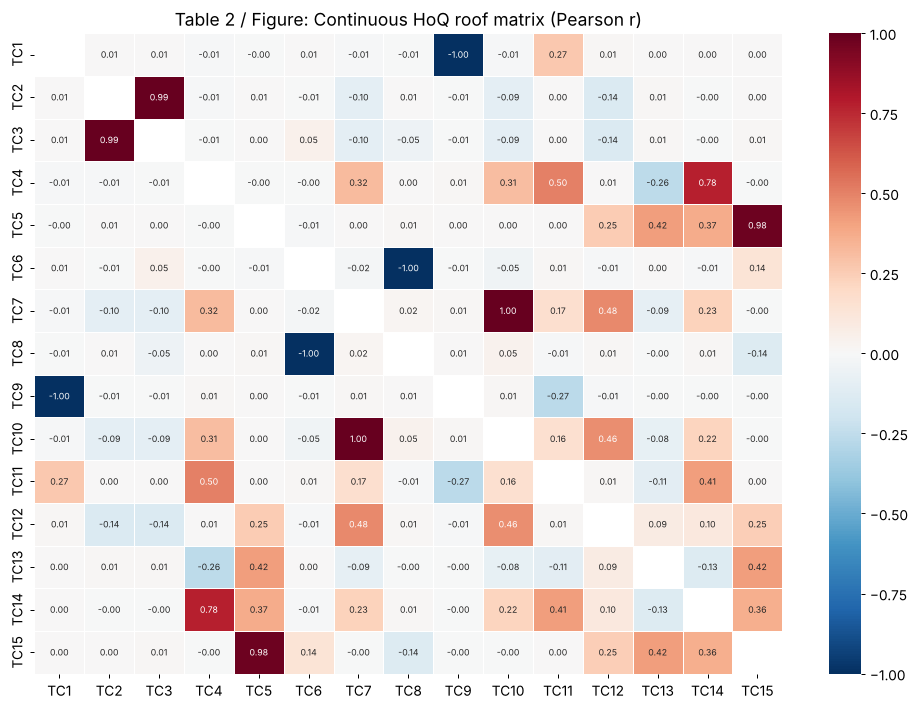

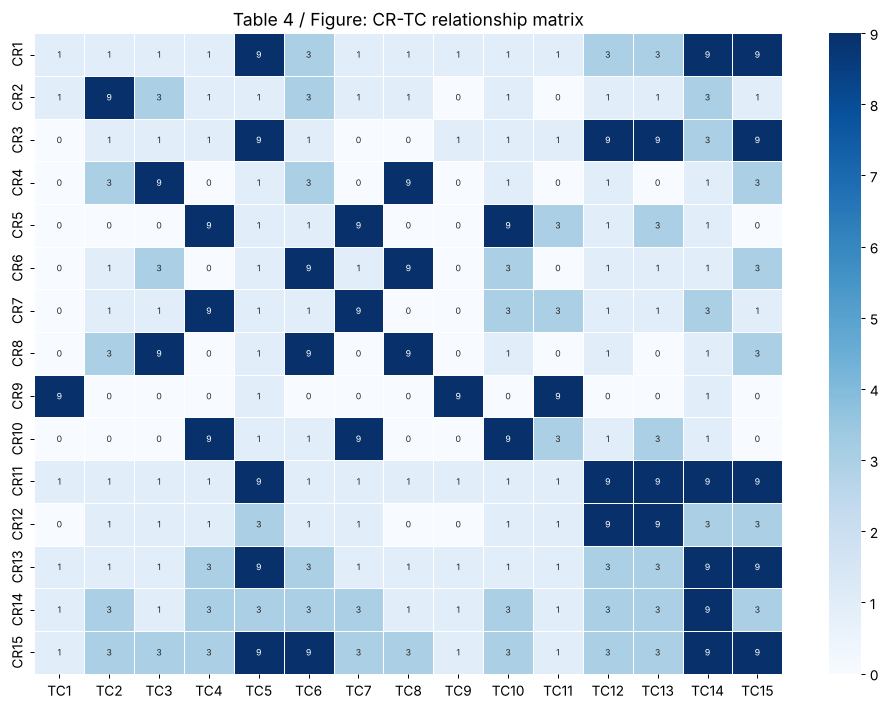

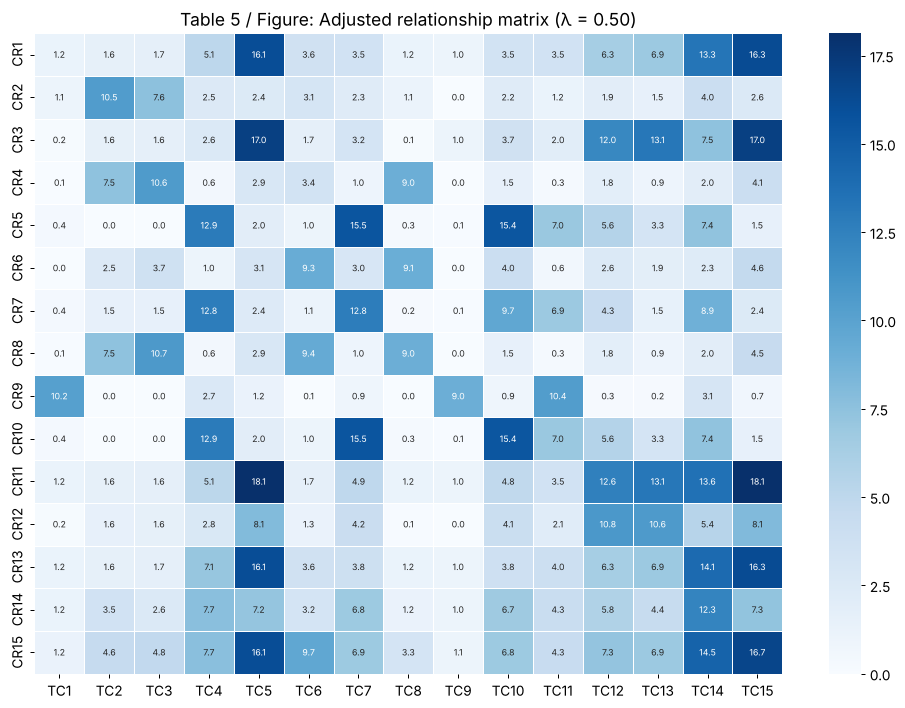

,Technical Characteristic,TIS,IP (%),PR,CP,T,D,CT,PI,PI (%),PIR
TC1,Launch Year,132.35,1.46,14,6,10,3,2,1.1680,3.80,14
TC2,Payload Mass,378.11,4.16,12,5,10,6,6,1.7333,5.64,11
TC3,Dry Mass,398.70,4.39,11,5,10,6,6,1.8292,5.95,10
TC4,Power Consumption,711.79,7.84,7,6,10,7,7,2.2400,7.29,7
TC5,Design Lifetime,1085.54,11.95,2,7,10,9,9,1.9917,6.48,8
TC6,Mass Efficiency,446.77,4.92,10,6,10,7,7,1.4057,4.57,13
TC7,Power Density,720.96,7.94,5,6,10,6,6,2.6467,8.61,4
TC8,Structural Fraction,287.63,3.17,13,5,10,6,5,1.4409,4.69,12
TC9,Technology Age,108.30,1.19,15,7,10,5,4,0.3967,1.29,15
TC10,Power per Dry Mass,714.00,7.86,6,6,10,6,5,2.8582,9.30,2


,Original PI (%),Original Rank,Mean PI (%),Mean Rank,KNN PI (%),KNN Rank,MICE PI (%),MICE Rank,MissForest PI (%),MissForest Rank,GAIN PI (%),GAIN Rank
TC1,3.80,14,3.95,14,4.15,14,3.75,14,3.77,14,4.33,14
TC2,5.64,11,5.66,11,5.61,11,5.58,11,5.62,11,5.64,11
TC3,5.95,10,5.99,10,5.89,10,5.90,10,5.92,10,5.94,10
TC4,7.29,7,7.19,7,7.29,6,7.30,7,7.28,7,7.33,7
TC5,6.48,8,6.38,8,6.36,8,6.48,8,6.48,8,6.30,8
TC6,4.57,13,4.81,13,4.74,13,4.52,13,4.56,13,4.64,13
TC7,8.61,4,8.44,4,8.49,4,8.59,4,8.63,4,8.61,3
TC8,4.69,12,5.03,12,4.85,12,4.66,12,4.70,12,4.77,12
TC9,1.29,15,1.36,15,1.33,15,1.27,15,1.28,15,1.35,15
TC10,9.30,2,9.03,2,9.10,2,9.23,2,9.33,2,9.22,2


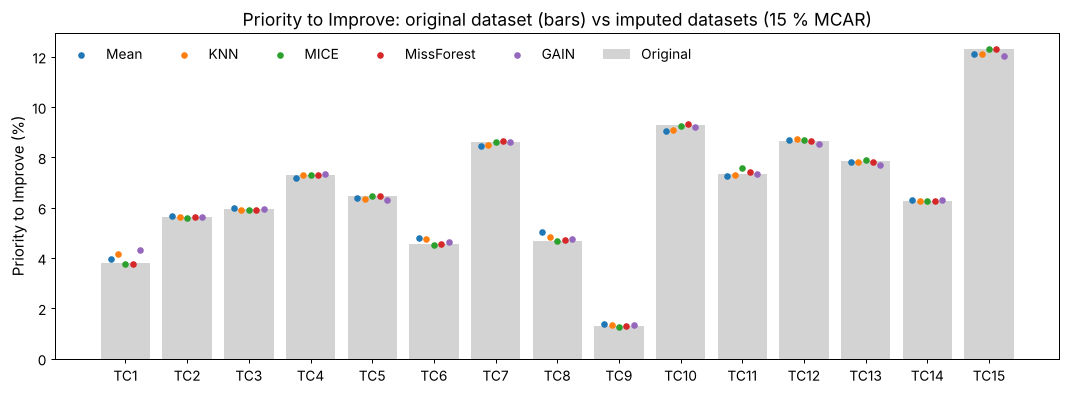

In [70]:
import seaborn as sns

# ============================================================
# [REVISION - R1-11] Heat-maps for the large matrices
# ============================================================

def save_heatmap(matrix, title, file_name, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1):
    plt.figure(figsize=(11, 8))
    sns.heatmap(matrix, annot=True, fmt=fmt, cmap=cmap, center=center, vmin=vmin, vmax=vmax,
                annot_kws={"size": 7}, linewidths=0.4, linecolor="white")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(file_name, dpi=400, bbox_inches="tight")
    plt.show()

roof_values = result_original["roof_matrix"].to_numpy(copy=True)
np.fill_diagonal(roof_values, np.nan)
roof_for_plot = pd.DataFrame(roof_values, index=tc_cols, columns=tc_cols)

save_heatmap(roof_for_plot, "Table 2 / Figure: Continuous HoQ roof matrix (Pearson r)", "Fig_R_Table2_roof.png")

save_heatmap(relationship_matrix[tc_cols].astype(float), "Table 4 / Figure: CR-TC relationship matrix",
             "Fig_R_Table4_relationship.png", fmt=".0f", cmap="Blues", center=None, vmin=0, vmax=9)

save_heatmap(result_original["adjusted_relationship_matrix"], "Table 5 / Figure: Adjusted relationship matrix (λ = 0.50)",
             "Fig_R_Table5_adjusted.png", fmt=".1f", cmap="Blues", center=None, vmin=0,
             vmax=result_original["adjusted_relationship_matrix"].values.max())

# ============================================================
# Table 8 as a compact text table (one row per TC)
# ============================================================

table8_text = pd.DataFrame({
    "Technical Characteristic": list(tc_names.values()),
    "TIS": result_original["adjusted_technical_importance"].round(2),
    "IP (%)": result_original["importance_percent"],
    "PR": result_original["priority_rank"],
    "CP": technical_evaluation["Current Performance"].values,
    "T": technical_evaluation["Target"].values,
    "D": technical_evaluation["Difficulty"].values,
    "CT": technical_evaluation["Cost and Time"].values,
    "PI": np.round(result_original["priority_to_improve"], 4),
    "PI (%)": result_original["priority_to_improve_percent"],
    "PIR": result_original["priority_to_improve_rank"]
}, index=tc_cols)

print("Table 8 (text version)")
display(table8_text)

# ============================================================
# Table 9 as a compact text table: PI (%) and rank, original vs methods (15 %, seed 42)
# ============================================================

table9_text = pd.DataFrame(index=tc_cols)
for name, res in [("Original", result_original), ("Mean", result_mean), ("KNN", result_knn),
                  ("MICE", result_mice), ("MissForest", result_missforest), ("GAIN", result_gain)]:
    table9_text[f"{name} PI (%)"] = res["priority_to_improve_percent"]
    table9_text[f"{name} Rank"] = res["priority_to_improve_rank"]

print("Table 9 (text version)")
display(table9_text)

# Figure alternative for Table 9
plt.figure(figsize=(12, 4.5))
x = np.arange(len(tc_cols))
plt.bar(x, result_original["priority_to_improve_percent"], color="lightgrey", label="Original")
for k, (name, res) in enumerate([("Mean", result_mean), ("KNN", result_knn), ("MICE", result_mice),
                                 ("MissForest", result_missforest), ("GAIN", result_gain)]):
    plt.scatter(x + (k - 2) * 0.12, res["priority_to_improve_percent"], s=18, label=name, zorder=3)
plt.xticks(x, tc_cols)
plt.ylabel("Priority to Improve (%)")
plt.title("Priority to Improve: original dataset (bars) vs imputed datasets (15 % MCAR)")
plt.legend(frameon=False, ncol=6)
plt.tight_layout()
plt.savefig("Fig_R_Table9_PI.png", dpi=400, bbox_inches="tight")
plt.show()

# ============================================================
# EXPORT ALL TABLES
# ============================================================

all_tables = {
    "Table2_roof": result_original["roof_matrix"].round(3),
    "Table4_relationship": relationship_matrix[tc_cols],
    "Table5_adjusted": result_original["adjusted_relationship_matrix"].round(3),
    "Table8_text": table8_text,
    "Table9_text": table9_text,
    "Table10_comparison_15": comparison_table,
    "R1_dataset": dataset_description,
    "R2_hyperparameters": hyperparameter_table,
    "R3_summary_by_rate": summary_table.reset_index(),
    "R4_composite_by_rate": overall_rank_by_rate.round(3),
    "R5_overall_rank_by_rate": overall_rank_table,
    "R6_friedman": friedman_table,
    "R7_attenuation": attenuation_table["Attenuation Ratio"][methods_order].round(3),
    "R8_roof_error": attenuation_table["Mean |Q_imp - Q_original|"][methods_order].round(4),
    "R9_lambda_ranks": lambda_rank_table,
    "R10_lambda_summary": lambda_summary,
    "R11_lambda_methods": lambda_method_table,
    "R12_negative": negative_table,
    "R13_negative_methods": negative_method_table,
    "R14_pearson_spearman": corr_method_table,
    "R15_target": target_table,
    "R16_target_methods": target_method_table,
    "R17_expert_summary": expert_summary,
    "R17b_expert_tc": expert_tc_table,
    "R18_expert_methods": expert_method_table,
    "All_runs": experiment_results
}

with pd.ExcelWriter("revision_tables.xlsx") as writer:
    for sheet, table in all_tables.items():
        table.to_excel(writer, sheet_name=sheet[:31])

print("Saved revision_tables.xlsx with", len(all_tables), "sheets")